# IDW Spatial Interpolation - Lagunazo Mine Waste (ICP geochemistry)

## 1 · Imports & Configuration

In [1]:
import warnings, time, math, re, zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import openpyxl
from scipy.spatial import cKDTree
from scipy import stats
from scipy.ndimage import gaussian_filter

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patheffects as mpe
import matplotlib.gridspec as gridspec
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle, PathPatch
from matplotlib.lines import Line2D
from matplotlib.path import Path as MPath

try:
    import seaborn as sns
    SNS_OK = True
except ImportError:
    sns, SNS_OK = None, False
    print("warning: seaborn not found - using matplotlib fallback for heatmaps.")
# pandas' Styler (.style) needs a sufficiently recent jinja2. Ask pandas itself rather than `import jinja2`:
# an old jinja2 imports fine but pandas still refuses .style. Without it, tables fall back to plain HTML.
try:
    pd.DataFrame({"a": [1]}).style.to_html()
    JINJA_OK = True
except Exception:
    JINJA_OK = False
    print("note: pandas table styling unavailable (jinja2 missing or too old) - tables are shown as plain HTML.")
try:
    import contextily as ctx
    CTX_OK = True
except ImportError:
    CTX_OK = False
    print("warning: contextily not found - basemap disabled (pip install contextily).")
try:
    from pyproj import Transformer
    PROJ_OK = True
except ImportError:
    PROJ_OK = False
    raise ImportError("pyproj is required for the WGS 84 -> UTM 29N projection (pip install pyproj).")
try:
    import shapely
    from shapely.geometry import Polygon as ShapelyPolygon, MultiPoint, Point
    SHAPELY_OK = True
except ImportError:
    SHAPELY_OK = False
    print("warning: shapely not found - polygon handling falls back to matplotlib (pip install shapely).")

matplotlib.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 400,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in",
})

# Input files
ICP_XLSX   = "ICP-DATA_2026.xlsx"          # laboratory Final Report workbook
SHEET_DATA = "Analytical Data"
SHEET_QC   = "QC Data"
SHEET_LOC  = "Locations"
KMZ_FILE   = "Lagunazo_waste_area.kmz"     # mine-waste boundary polygon

# Element for the detailed single-element workflow
VAR_NAME   = "Bi"                          # any mappable CRM analyte listed in Section 5, e.g. "Sb", "Cu", "Co"
EPSG_UTM   = "EPSG:32629"                  # WGS 84 / UTM Zone 29N

# Sample-ID reconciliation
LAB_TO_FIELD_PREFIX = {"LA": "LG"}         # laboratory prefix -> field (Locations sheet) prefix
LOCATION_ID_FIXES = [                      # keyed on the 'No.' column of the Locations sheet
    dict(no=13, recorded="LG-35-31", corrected="LG-25-31", kind="typo",
         reason="year field '35' is a typo; point lies in the LG-25-33 -> 31 -> 29 field sequence"),
    dict(no=23, recorded="LH-25-06", corrected="LG-25-06", kind="typo",
         reason="prefix 'LH' is a typo; point lies in the LG-25-07 -> 06 -> 05 field sequence"),
    dict(no=29, recorded="LG-25-34", corrected="LG-25-24", kind="inferred",
         reason="LG-25-34 is recorded twice (No. 29 and No. 44) and LG-25-24 is otherwise missing; "
                "No. 29 lies between LG-25-25 and LG-25-23 in the field sequence"),
]
APPLY_INFERRED_FIXES = True   # False -> the No. 29 / No. 44 duplicate stays ambiguous and both samples are dropped

# Censored assays
BDL_FACTOR     = 0.5    # "<MDL" -> BDL_FACTOR x MDL
ODL_FACTOR     = 1.0    # ">UDL" -> ODL_FACTOR x upper limit (a LOWER BOUND - flagged everywhere)
MIN_QUANT_FRAC = 0.15   # min. fraction of located samples quantified (was 0.70; lowered so that every CRM with a
                        # spatial signal is mapped - censored stations form the '<MDL' map class)
MIN_QUANT_FRAC_STRICT = 0.70   # below this detected share a map is flagged as censored ('<MDL' class shown)
MIN_DETECTED_N = 5      # min. number of located detections (> MDL); below it (Be 1, Pd 0, Ta 0) -> detection map only
MIN_N_MAP      = 15     # min. number of located samples for mapping

# Grid & display
GRID_DENSITY_M = 3.0    # interpolation grid spacing (m)
SMOOTH_SIGMA   = 0.0    # display-only Gaussian sigma in cells; 0 = raw IDW surface (reported values)
PAD_FRAC       = 0.06   # map padding as a fraction of extent

# IDW parameter search (LOOCV)
P_VALUES       = np.round(np.arange(0.5, 3.01, 0.25), 2)   # distance-decay powers
K_VALUES       = [4, 6, 8, 10, 12, 16, 20, 24]              # max neighbours
MIN_NEIGHBORS  = 4                                          # min. neighbours inside the radius, else fallback
RADIUS_FACTORS = [None, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]     # None = no radius (pure k-nearest); otherwise radius
                                                            # = factor x D_MINK, the median distance from a station
                                                            # to its MIN_NEIGHBORS-th nearest station (Section 8)
STATION_TOL_M  = 5.0                                        # replicates within this radius = one station
SELECTION      = "parsimony"  # "min_rmse" (r8: lowest LOOCV RMSE) | "parsimony": among the sets within RMSE_TOL_PCT %
RMSE_TOL_PCT   = 1.0          # of the minimum RMSE, prefer no search radius, then the observed-on-predicted slope
                              # closest to 1 (least conditional bias, as in kriging neighbourhood analysis)
TRANSFORM      = "none"   # "none" | "log" (log: weighted geometric mean - median-type, NOT mean-unbiased)

# Classified display
CLASS_SCHEME       = "equal"     # detail maps: "equal" = rounded equal intervals (r8 standard) | "quantile"
ATLAS_CLASS_SCHEME = "quantile"  # atlas maps: station percentiles P0-10-25-50-75-90-95-100 (geochemical-atlas
                                 # convention; equal intervals flatten skewed elements into one or two classes)
N_GRADE_CLASSES   = 7
N_SUPPORT_CLASSES = 6
GRADE_CMAP, SUPPORT_CMAP, RESID_CMAP = "turbo", "RdYlGn_r", "RdBu_r"
HATCH_EXTRAP      = True      # hatch nodes farther from any station than EXTRAP_DIST_M (extrapolation)
EXTRAP_DIST_M     = None      # None = largest station-to-nearest-station distance (outside the sampled configuration)
BASEMAP_ALPHA     = 0.62

# CRM atlas (Section 12)
RUN_ATLAS         = True      # tune + map every mappable CRM analyte
MIN_R2_SURFACE    = 0.10      # reliability threshold: LOOCV R2 >= this = 'predictive', 0-this = 'weak', < 0 = 'no skill'
MAP_ALL_SURFACES  = True      # True: interpolate EVERY mappable CRM, each map labelled with its reliability;
                              # False: post the sample values where LOOCV R2 < MIN_R2_SURFACE (previous behaviour)
CENSORED_CLASS    = True      # lowest map class = '<MDL' for elements with stations below detection
DETECTION_MAP_PNG = "ICP_CRM_detection_maps_UTM29N.png"
ATLAS_SINGLE_MAPS = True      # also save a full r8-style map per element

if not Path(ICP_XLSX).exists():
    raise FileNotFoundError(f"'{ICP_XLSX}' not found in {Path.cwd()} - place the laboratory workbook next to this notebook.")

print("Configuration loaded.")
print(f"  Workbook       : {ICP_XLSX}")
print(f"  Detail element : {VAR_NAME}   |   transform = {TRANSFORM}")
print(f"  CRS            : {EPSG_UTM} (metres)")
print(f"  Grid spacing   : {GRID_DENSITY_M:g} m   |   display smoothing sigma = {SMOOTH_SIGMA:g} (0 = raw)")
print(f"  Search grid    : {len(P_VALUES)} powers x {len(K_VALUES)} k x {len(RADIUS_FACTORS)} radii "
      f"= {len(P_VALUES)*len(K_VALUES)*len(RADIUS_FACTORS)} parameter sets")

note: pandas table styling unavailable (jinja2 missing or too old) - tables are shown as plain HTML.
Configuration loaded.
  Workbook       : ICP-DATA_2026.xlsx
  Detail element : Bi   |   transform = none
  CRS            : EPSG:32629 (metres)
  Grid spacing   : 3 m   |   display smoothing sigma = 0 (0 = raw)
  Search grid    : 11 powers x 8 k x 7 radii = 616 parameter sets


## 2 · Core Geostatistical Routines

All estimation goes through **one** neighbourhood rule, `_idw_rule`, used identically for grid nodes and for
leave-one-out prediction. For each target the *k* nearest stations are found; if at least `min_k` of them lie
within the search radius, only those are used; otherwise the node uses the **extended** neighbourhood — all *k*
nearest regardless of distance (the r8 "fallback"). The neighbourhood type of every node is mapped (Figure 4d). A target that coincides with a
station returns that station's value, so the interpolator is exact. `idw_point` / `loocv_idw_bruteforce` reproduce
the r8 point-by-point implementation and are kept only to verify the vectorised engine (Section 11).

In [2]:
# stations
def station_means(df, x_col, y_col, var, tol_m=5.0, id_col=None, flag_col=None, verbose=True):
    """Collapse replicate measurements to one value per STATION (single-linkage within tol_m metres).

    Leave-one-out validation must remove every measurement made at a location, otherwise a
    held-out value is predicted from its own replicate.  Returns (station_df, report)."""
    d = df.copy()
    for c in (x_col, y_col, var):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=[x_col, y_col, var]).reset_index(drop=True)
    if d.empty:
        raise ValueError(f"No valid rows for {var}.")
    xy = d[[x_col, y_col]].to_numpy(float)
    parent = np.arange(len(d))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in cKDTree(xy).query_pairs(r=max(tol_m, 1e-9)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    d["_station"] = [find(i) for i in range(len(d))]

    agg = {x_col: (x_col, "mean"), y_col: (y_col, "mean"), var: (var, "mean"),
           "n_reps": (var, "size"), "rep_sd": (var, "std")}
    if id_col:
        agg[id_col] = (id_col, lambda s: "+".join(map(str, s)))
    if flag_col:
        agg[flag_col] = (flag_col, lambda s: ",".join(sorted(set(map(str, s)))))
    out = d.groupby("_station").agg(**agg).reset_index(drop=True)
    ext = d.groupby("_station")[[x_col, y_col]].agg(lambda s: s.max() - s.min())
    spread = np.hypot(ext[x_col].to_numpy(), ext[y_col].to_numpy())
    rep = dict(n_measurements=int(len(d)), n_stations=int(len(out)),
               n_stations_with_reps=int((out["n_reps"] > 1).sum()),
               max_cluster_extent_m=float(spread.max()) if spread.size else 0.0,
               n_chained=int(np.sum(spread > 3.0 * tol_m)), tol_m=float(tol_m))
    if verbose:
        print(f"Station aggregation ({var}): {rep['n_measurements']} measurements -> "
              f"{rep['n_stations']} stations at a {tol_m:g} m tolerance "
              f"({rep['n_stations_with_reps']} with replicates)")
        if rep["n_chained"]:
            print(f"  WARNING: {rep['n_chained']} cluster(s) span > 3x the tolerance (single-linkage chaining).")
    return out.drop(columns=["rep_sd"]), rep


# declustering
def declustering_weights(coords, values, cell_sizes=None, n_origins=12, target="min_mean", seed=0):
    """Cell declustering (Journel 1983; GSLIB `declus`).

    For each candidate cell size, weights 1/(samples in cell) are averaged over `n_origins`
    grid-origin offsets and normalised to mean 1; the cell size giving the minimum declustered
    mean ("min_mean", appropriate when high values were preferentially sampled) or the maximum
    ("max_mean") is selected.  Returns (weights, chosen_cell_size_m, table)."""
    coords = np.asarray(coords, float)
    v = np.asarray(values, float)
    n = len(v)
    if n < 3:
        return np.ones(n), np.nan, pd.DataFrame()
    if cell_sizes is None:
        nn = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
        ext = float(max(np.ptp(coords[:, 0]), np.ptp(coords[:, 1])))
        cell_sizes = np.unique(np.round(np.linspace(max(nn, 1.0), max(ext / 2.0, nn * 1.01), 24), 1))
    rng = np.random.default_rng(seed)
    x0, y0 = coords[:, 0].min(), coords[:, 1].min()
    rows, W = [], {}
    for cs in cell_sizes:
        acc = np.zeros(n)
        for o in range(n_origins):
            ox, oy = (0.0, 0.0) if o == 0 else (rng.uniform(0, cs), rng.uniform(0, cs))
            ix = np.floor((coords[:, 0] - x0 + ox) / cs).astype(np.int64)
            iy = np.floor((coords[:, 1] - y0 + oy) / cs).astype(np.int64)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0,
                                    return_inverse=True, return_counts=True)
            w = 1.0 / cnt[np.asarray(inv).ravel()]
            acc += w * n / w.sum()
        w = acc / n_origins
        w *= n / w.sum()
        W[float(cs)] = w
        rows.append((float(cs), float(np.sum(w * v) / n)))
    tab = pd.DataFrame(rows, columns=["cell_size_m", "declustered_mean"])
    i = tab["declustered_mean"].idxmin() if target == "min_mean" else tab["declustered_mean"].idxmax()
    cs = float(tab.loc[i, "cell_size_m"])
    return W[cs], cs, tab


def declustered_stats(values, weights=None):
    v = np.asarray(values, float)
    w = np.ones_like(v) if weights is None else np.asarray(weights, float)
    w = w / w.sum()
    mean = float(np.sum(w * v))
    order = np.argsort(v)
    cw = np.cumsum(w[order]) - 0.5 * w[order]
    return dict(naive_mean=float(v.mean()), declustered_mean=mean,
                declustered_median=float(np.interp(0.5, cw, v[order])),
                declustered_sd=float(np.sqrt(np.sum(w * (v - mean) ** 2))),
                effect_pct=float(100 * (mean - v.mean()) / v.mean()) if v.mean() else np.nan)


# transform
def fwd(z, kind=None):
    kind = TRANSFORM if kind is None else kind
    z = np.asarray(z, float)
    if kind == "log":
        if np.any(z <= 0):
            raise ValueError("log transform requires strictly positive values")
        return np.log(z)
    return z

def back(y, kind=None):
    kind = TRANSFORM if kind is None else kind
    return np.exp(y) if kind == "log" else np.asarray(y, float)


# IDW engine
def _idw_rule(dists, idxs, values, p, min_k, radius, eps=1e-9):
    """Shared IDW neighbourhood rule (vectorised).

    dists, idxs : (m, k) nearest-neighbour arrays sorted by distance (cKDTree convention:
                  missing neighbours have distance inf and index == len(values)).
    Returns (estimate, fallback_flag, n_used, reach) - reach = distance to the farthest station used."""
    values = np.asarray(values, float)
    n = len(values)
    dists = np.atleast_2d(dists)
    idxs = np.atleast_2d(idxs)
    valid = np.isfinite(dists) & (idxs < n)
    vals = values[np.where(valid, idxs, 0)]
    if radius is not None and np.isfinite(radius) and radius > 0:
        within = valid & (dists <= radius)
        enough = within.sum(axis=1) >= min_k
        use = np.where(enough[:, None], within, valid)
    else:
        enough = np.ones(len(dists), bool)
        use = valid
    w = np.where(use, 1.0 / np.maximum(dists, eps) ** p, 0.0)
    wsum = w.sum(axis=1)
    est = np.full(len(dists), np.nan)
    ok = wsum > 0
    est[ok] = (w[ok] * vals[ok]).sum(axis=1) / wsum[ok]
    zero = use & (dists <= eps)                      # coincident with a station -> exact
    hit = zero.any(axis=1)
    if hit.any():
        est[hit] = (np.where(zero, vals, 0.0).sum(axis=1) / np.maximum(zero.sum(axis=1), 1))[hit]
    reach = np.where(use, dists, 0.0).max(axis=1)
    return est, ~enough, use.sum(axis=1), reach


def idw_grid(targets, coords, values, p, k, min_k, radius, tree=None):
    """IDW at arbitrary target points with the shared rule."""
    n = len(values)
    kq = int(min(k, n))
    tree = cKDTree(coords) if tree is None else tree
    d, ix = tree.query(np.atleast_2d(targets), k=kq)
    d = np.asarray(d).reshape(-1, kq)
    ix = np.asarray(ix).reshape(-1, kq)
    return _idw_rule(d, ix, values, p, min(min_k, kq), radius)


def loocv_idw(coords, values, p, k, min_k, radius):
    """Vectorised leave-one-out IDW: each station is predicted from the others with the SAME rule
    as the grid (the k+1 nearest are queried and the station itself is removed)."""
    coords = np.asarray(coords, float)
    values = np.asarray(values, float)
    n = len(values)
    if n < 3:
        raise ValueError("LOOCV needs at least three stations.")
    k = int(min(k, n - 1))
    kq = k + 1
    d, ix = cKDTree(coords).query(coords, k=kq)
    d = np.asarray(d).reshape(n, kq)
    ix = np.asarray(ix).reshape(n, kq)
    self_col = ix == np.arange(n)[:, None]
    no_self = ~self_col.any(axis=1)                  # only possible with > k coincident stations
    self_col[no_self, -1] = True
    keep = ~self_col
    d2 = d[keep].reshape(n, k)
    ix2 = ix[keep].reshape(n, k)
    est, fb, _, _ = _idw_rule(d2, ix2, values, p, min(min_k, k), radius)
    return est, int(fb.sum())


# reference (r8-style, point-by-point) implementation: used only for verification 
def idw_point(pt, coords, values, tree, p=2.0, k=8, min_k=4, radius=None, eps=1e-9):
    n = len(values)
    use_r = radius is not None and np.isfinite(radius) and radius > 0
    idx = tree.query_ball_point(pt, r=radius) if use_r else []
    if len(idx) < min_k or not use_r:
        kk = int(min(max(min_k, k), n)) if use_r else int(min(k, n))
        dd, idx = tree.query(pt, k=kk)
        idx = np.atleast_1d(idx)[np.isfinite(np.atleast_1d(dd)) & (np.atleast_1d(idx) < n)]
    idx = np.asarray(idx, int)
    if idx.size == 0:
        return np.nan
    d = np.linalg.norm(coords[idx] - pt, axis=1)
    if idx.size > k:
        sel = np.argsort(d)[:k]
        idx, d = idx[sel], d[sel]
    zero = d <= eps
    if zero.any():
        return float(np.mean(values[idx[zero]]))
    w = 1.0 / d ** p
    return float(np.dot(w, values[idx]) / w.sum())


def loocv_idw_bruteforce(coords, values, p, k, min_k, radius):
    n = len(values)
    out = np.full(n, np.nan)
    for i in range(n):
        keep = np.arange(n) != i
        c, v = coords[keep], values[keep]
        out[i] = idw_point(coords[i], c, v, cKDTree(c), p=p, k=min(k, n - 1),
                           min_k=min(min_k, n - 1), radius=radius)
    return out


# metrics
def metrics(y_true, y_pred, label=""):
    """Cross-validation statistics (MAPE deliberately omitted: meaningless at low grades;
    R2_pred is the Nash-Sutcliffe efficiency for these inputs, so it is reported once)."""
    yt = np.asarray(y_true, float)
    yp = np.asarray(y_pred, float)
    ok = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[ok], yp[ok]
    if yt.size < 2:
        return {}
    res = yp - yt
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(res ** 2)))
    good = np.std(yt) > 0 and np.std(yp) > 0
    slope = stats.linregress(yt, yp)[0] if good else np.nan      # predicted on observed: smoothing
    slope_op = stats.linregress(yp, yt)[0] if good else np.nan   # observed on predicted: conditional bias (ideal 1)
    return dict(
        Label=label, n=int(yt.size),
        RMSE=float(rmse), MAE=float(np.mean(np.abs(res))), ME_bias=float(res.mean()),
        Rel_bias_pct=float(100 * res.mean() / yt.mean()) if yt.mean() else np.nan,
        Rel_RMSE_pct=float(100 * rmse / yt.mean()) if yt.mean() else np.nan,
        R2_pred=float(1 - np.sum(res ** 2) / ss_tot) if ss_tot > 0 else np.nan,
        Pearson_r=float(np.corrcoef(yt, yp)[0, 1]) if np.std(yt) > 0 and np.std(yp) > 0 else np.nan,
        Spearman_r=float(stats.spearmanr(yt, yp)[0]),
        Reg_slope=float(slope), Slope_obs_on_pred=float(slope_op),
        Obs_min=float(yt.min()), Obs_max=float(yt.max()),
        Est_min=float(yp.min()), Est_max=float(yp.max()),
        Var_ratio=float(np.var(yp) / np.var(yt)) if np.var(yt) > 0 else np.nan)


def interpret_metrics(m, unit="ppm"):
    print(f"\nInterpretation of {m.get('Label', '')}:")
    r2 = m.get("R2_pred", np.nan)
    if np.isfinite(r2):
        if r2 <= 0:
            print(f"  R2 = {r2:.3f} <= 0: the surface predicts held-out stations no better than the sample\n"
                  "     mean. Report this plainly; the map shows the data pattern, it is not a predictive grade model.")
        elif r2 < 0.3:
            print(f"  R2 = {r2:.3f}: weak predictive skill, typical of a high short-range (nugget) variability.")
        else:
            print(f"  R2 = {r2:.3f}: moderate-to-good predictive skill for an exact interpolator.")
    vr = m.get("Var_ratio", np.nan)
    if np.isfinite(vr) and vr < 0.5:
        print(f"  Variance ratio {vr:.2f}: the estimates carry < 50 % of the data variance (strong smoothing);\n"
              "     tonnage above a cut-off read from this surface is not reliable.")
    sl = m.get("Reg_slope", np.nan)
    if np.isfinite(sl) and sl < 0.5:
        print(f"  Slope of predicted on observed {sl:.2f}: strong smoothing - highs under-, lows over-estimated.")
    so = m.get("Slope_obs_on_pred", np.nan)
    if np.isfinite(so):
        msg = ("close to 1 - estimates are conditionally unbiased" if abs(so - 1) <= 0.1 else
               "< 1 - estimates too variable: high estimates overstate true grades" if so < 1 else
               "> 1 - estimates over-smoothed: high estimates understate true grades")
        print(f"  Slope of observed on predicted {so:.2f}: {msg}.")
    rb = m.get("Rel_bias_pct", np.nan)
    if np.isfinite(rb) and abs(rb) > 10:
        print(f"  Mean error {rb:+.1f} % of the mean: systematic bias in the cross-validation.")

# tables
_STATUS_CSS = {"PASS": "background-color:#eafaf1;color:#1e8449;font-weight:bold",
               "WARN": "background-color:#fef9e7;color:#b7950b;font-weight:bold",
               "FAIL": "background-color:#fdedec;color:#922b21;font-weight:bold",
               "INFO": "background-color:#eaf2f8;color:#1a5276;font-weight:bold"}

def show_table(df, precision=None, status_col=None):
    """Display a DataFrame without its index.

    Uses the pandas Styler when jinja2 is installed and plain HTML (DataFrame.to_html, which does not need
    jinja2) otherwise, so the notebook runs in any kernel. `status_col` colours PASS/WARN/FAIL/INFO cells."""
    if JINJA_OK:
        try:
            sty = df.style
            if precision is not None:
                sty = sty.format(precision=precision, thousands=",")
            if status_col is not None:
                colour = sty.map if hasattr(sty, "map") else sty.applymap      # pandas >= 2.1 / older
                sty = colour(lambda v: _STATUS_CSS.get(v, ""), subset=[status_col])
            display(sty.hide(axis="index"))
            return
        except Exception:                      # any Styler problem -> plain HTML below
            pass
    d = df.copy()
    if precision is not None:
        num = d.select_dtypes("number").columns
        d[num] = d[num].round(precision)
    html = d.to_html(index=False, na_rep="", escape=True)
    if status_col is not None:
        for key, css in _STATUS_CSS.items():
            html = html.replace(f"<td>{key}</td>", f'<td style="{css}">{key}</td>')
    display(HTML(html))

print("Core routines loaded.")

Core routines loaded.


## 3 · ICP Workbook, Censored Values and Sample Locations

Each assay cell is parsed into a numeric value and a flag: `ok` (quantified), `bdl` (`<MDL`; the number is the
detection limit), `odl` (`>UDL`; the number is the upper reporting limit), `is` (insufficient sample) or `na`
(not analysed). Column names are the analyte for AQ251 and `<analyte>_LF725` for the fusion-XRF package, so that
Ba, Cu, Pb and Zn from the two methods are never mixed.

In [3]:
def parse_cell(v):
    """Laboratory cell -> (number, flag)."""
    if v is None:
        return np.nan, "na"
    s = str(v).strip().replace(",", "")
    if s == "":
        return np.nan, "na"
    if s.upper() == "IS":
        return np.nan, "is"
    try:
        if s.startswith("<"):
            return float(s[1:]), "bdl"
        if s.startswith(">"):
            return float(s[1:]), "odl"
        return float(s), "ok"
    except ValueError:
        return np.nan, "other"


def canon_id(s):
    """'LA - 25 - 03' / 'Lg-25-7' -> ('LA', 25, 3); None if not parseable."""
    m = re.match(r"^\s*([A-Za-z]+)\s*-\s*(\d+)\s*-\s*(\d+)\s*$", str(s))
    return (m.group(1).upper(), int(m.group(2)), int(m.group(3))) if m else None


def read_lab_sheet(path, sheet):
    """Read a laboratory report sheet -> (VAL, FLAG, META, info) with one row per sample."""
    ws = openpyxl.load_workbook(path, data_only=True, read_only=True)[sheet]
    rows = [list(r) for r in ws.iter_rows(values_only=True)]

    def find_row(label):
        for i, r in enumerate(rows):
            if len(r) > 1 and isinstance(r[1], str) and r[1].strip().lower() == label:
                return i
        raise ValueError(f"'{label}' header row not found in sheet '{sheet}'")

    i_meth, i_an, i_unit, i_mdl = (find_row(x) for x in ("method", "analyte", "unit", "mdl"))
    i_hdr = next(i for i, r in enumerate(rows)
                 if r and isinstance(r[0], str) and r[0].strip().lower() == "sample")
    meta = []
    for j in range(2, len(rows[i_an])):
        an, me = rows[i_an][j], rows[i_meth][j]
        if an is None or me in (None, "WGHT"):
            continue
        key = str(an).strip() if me == "AQ251" else f"{str(an).strip()}_{me}"
        meta.append(dict(col=j, key=key, analyte=str(an).strip(), method=me,
                         unit=str(rows[i_unit][j]).strip(), mdl=float(rows[i_mdl][j])))
    meta = pd.DataFrame(meta).set_index("key")
    recs, ids, types = [], [], []
    for r in rows[i_hdr + 1:]:
        if not r or r[0] is None or str(r[0]).strip() == "" or r[1] is None:
            continue                                   # section captions / empty rows
        ids.append(str(r[0]).strip())
        types.append(str(r[1]).strip())
        recs.append([parse_cell(r[j]) for j in meta["col"]])
    val = pd.DataFrame([[c[0] for c in rec] for rec in recs], columns=meta.index)
    flg = pd.DataFrame([[c[1] for c in rec] for rec in recs], columns=meta.index)
    val.insert(0, "Lab_ID", ids); flg.insert(0, "Lab_ID", ids)
    val.insert(1, "Type", types); flg.insert(1, "Type", types)
    info = {str(r[0]).strip(":"): r[1] for r in rows[:i_meth] if r and isinstance(r[0], str)}
    return val, flg, meta.drop(columns="col"), info


RAW_VAL, RAW_FLAG, META, LAB_INFO = read_lab_sheet(ICP_XLSX, SHEET_DATA)
AQ_COLS = [c for c in META.index if META.loc[c, "method"] == "AQ251"]
LF_COLS = [c for c in META.index if META.loc[c, "method"] == "LF725"]

keys = RAW_VAL["Lab_ID"].map(canon_id)
if keys.isna().any():
    raise ValueError(f"Unparseable laboratory IDs: {list(RAW_VAL.loc[keys.isna(), 'Lab_ID'])}")
RAW_VAL["Sample"] = [f"{p}-{y:02d}-{n:02d}" for p, y, n in keys]
RAW_FLAG["Sample"] = RAW_VAL["Sample"]
RAW_VAL["_key"] = [(LAB_TO_FIELD_PREFIX.get(p, p), y, n) for p, y, n in keys]
has_aq = RAW_FLAG[AQ_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
has_lf = RAW_FLAG[LF_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
is_is  = RAW_FLAG[AQ_COLS].eq("is").all(axis=1)

print(f"Laboratory      : {LAB_INFO.get('Client', '')} | job {LAB_INFO.get('Job Number', '')} | "
      f"report {LAB_INFO.get('File Created', '')} | project '{LAB_INFO.get('Project', '')}'")
print(f"Analytes        : {len(AQ_COLS)} by AQ251 (aqua regia ICP-ES/MS), {len(LF_COLS)} by LF725 (fusion XRF)")
print(f"Sample rows     : {len(RAW_VAL)}  (header states {LAB_INFO.get('Number of Samples', '?')} - "
      f"this workbook holds a subset of the job)")
print(f"  with AQ251 data          : {int(has_aq.sum())}")
print(f"  with LF725 data          : {int(has_lf.sum())}  -> {list(RAW_VAL.loc[has_lf, 'Sample'])}")
print(f"  insufficient sample (IS) : {int(is_is.sum())}  -> {list(RAW_VAL.loc[is_is, 'Sample'])}")
print(f"  LF725 only (no AQ251)    : {list(RAW_VAL.loc[has_lf & ~has_aq, 'Sample'])}")

census = (RAW_FLAG[AQ_COLS + LF_COLS].apply(lambda c: c.value_counts()).T
          .reindex(columns=["ok", "bdl", "odl", "is", "na"]).fillna(0).astype(int))
census.index.name = "analyte"

Laboratory      : Delft University of Technology | job PLKRK2600014 | report 29-Apr-2026 | project 'Tailings analysis'
Analytes        : 53 by AQ251 (aqua regia ICP-ES/MS), 16 by LF725 (fusion XRF)
Sample rows     : 55  (header states 146 - this workbook holds a subset of the job)
  with AQ251 data          : 46
  with LF725 data          : 8  -> ['LA-25-03', 'LA-25-06', 'LA-25-13', 'LA-25-16', 'LA-25-19', 'LA-25-23', 'LA-25-25', 'LA-25-45']
  insufficient sample (IS) : 5  -> ['LA-24-22', 'LA-24-29', 'LA-25-14', 'LA-25-15', 'LA-25-18']
  LF725 only (no AQ251)    : ['LA-25-16', 'LA-25-23', 'LA-25-25', 'LA-25-45']


In [4]:
# Locations sheet: DMS -> decimal degrees -> UTM 29N; ID reconciliation
DMS_RE = re.compile(r"(\d+(?:\.\d+)?)\s*[°º]\s*(\d+(?:\.\d+)?)\s*['′’]\s*(\d+(?:\.\d+)?)\s*(?:\"|″|'')?\s*([NSEW])")

def dms_pair(s):
    out = {}
    for d, m_, s_, h in DMS_RE.findall(str(s)):
        v = float(d) + float(m_) / 60 + float(s_) / 3600
        out["lat" if h in "NS" else "lon"] = -v if h in "SW" else v
    if set(out) != {"lat", "lon"}:
        raise ValueError(f"Cannot parse coordinate string: {s!r}")
    return out["lat"], out["lon"]

def lonlat_to_utm(lon, lat, epsg=EPSG_UTM):
    tf = Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
    x, y = tf.transform(np.asarray(lon, float), np.asarray(lat, float))
    return np.asarray(x, float), np.asarray(y, float)

ws_loc = openpyxl.load_workbook(ICP_XLSX, data_only=True, read_only=True)[SHEET_LOC]
LOC = pd.DataFrame([r[:3] for r in ws_loc.iter_rows(min_row=2, values_only=True)],
                   columns=["No", "Field_ID_recorded", "Location"]).dropna(subset=["Field_ID_recorded"])
LOC["No"] = LOC["No"].astype(int)
LOC[["Lat", "Lon"]] = LOC["Location"].apply(lambda s: pd.Series(dms_pair(s)))
LOC["X_utm"], LOC["Y_utm"] = lonlat_to_utm(LOC["Lon"], LOC["Lat"])

LOC["Field_ID"] = LOC["Field_ID_recorded"].str.strip()
LOC["ID_fix"] = ""
fix_rows = []
for f in LOCATION_ID_FIXES:
    hit = (LOC["No"] == f["no"]) & (LOC["Field_ID_recorded"].str.upper().str.replace(" ", "")
                                    == f["recorded"].upper())
    applied = bool(hit.any()) and (f["kind"] != "inferred" or APPLY_INFERRED_FIXES)
    if applied:
        LOC.loc[hit, "Field_ID"] = f["corrected"]
        LOC.loc[hit, "ID_fix"] = f["kind"]
    fix_rows.append({**f, "found": bool(hit.any()), "applied": applied})
ID_FIX_TABLE = pd.DataFrame(fix_rows)

k_loc = LOC["Field_ID"].map(canon_id)
LOC["Field_ID"] = [f"{p_}-{y:02d}-{n:02d}" for p_, y, n in k_loc]   # canonical spelling, e.g. LG-25-7 -> LG-25-07
LOC["_key"] = k_loc
dup = LOC["_key"].duplicated(keep=False)
AMBIGUOUS = LOC.loc[dup, ["No", "Field_ID_recorded", "Field_ID"]]
loc_ok = LOC.loc[~dup].set_index("_key")

# join: analytical rows with assay data <-> unique field locations
has_any = has_aq | has_lf
SAMP = RAW_VAL.loc[has_any, ["Sample", "_key"]].copy()
SAMP = SAMP.join(loc_ok[["No", "Field_ID", "Field_ID_recorded", "ID_fix", "Lon", "Lat", "X_utm", "Y_utm"]],
                 on="_key")
SAMP["Located"] = SAMP["X_utm"].notna()
SAMP["Series"] = SAMP["Sample"].str[:5]
LOCATED = SAMP["Located"].to_numpy()

print("ID reconciliation (Locations sheet):")
display(ID_FIX_TABLE[["no", "recorded", "corrected", "kind", "found", "applied", "reason"]])
if len(AMBIGUOUS):
    print(f"  AMBIGUOUS field IDs (dropped): {AMBIGUOUS.to_dict('records')}")
print(f"\nSamples with assay data : {len(SAMP)}")
_aq_loc = int((SAMP["Located"] & has_aq[has_any].to_numpy()).sum())
print(f"  located               : {int(SAMP['Located'].sum())}  ({_aq_loc} with AQ251 data, "
      f"{int(SAMP['Located'].sum()) - _aq_loc} with LF725 fusion data only)")
print(f"  not located           : {int((~SAMP['Located']).sum())} -> "
      f"{', '.join(SAMP.loc[~SAMP['Located'], 'Sample'])}")
unused = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"]), "Field_ID"].tolist()
print(f"  field points without assay data in this workbook: {', '.join(sorted(unused))}")
_xy = LOC[["X_utm", "Y_utm"]].round(3)
_dups = LOC[_xy.duplicated(keep=False)]
if len(_dups):
    print(f"  WARNING: identical coordinates recorded for {', '.join(_dups['Field_ID'])} - the position of any "
          "assayed sample among them is uncertain (only one can have been taken exactly there).")
print(f"  UTM extent of located samples: E {SAMP['X_utm'].min():.0f}-{SAMP['X_utm'].max():.0f}  "
      f"N {SAMP['Y_utm'].min():.0f}-{SAMP['Y_utm'].max():.0f}")
_d, _ = cKDTree(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy()).query(
    SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(), k=2)
print(f"  nearest-neighbour spacing: median {np.median(_d[:, 1]):.1f} m, min {_d[:, 1].min():.1f} m "
      f"(DMS given to 0.1\" = ~3 m, comparable with handheld GPS error)")

ID reconciliation (Locations sheet):


,no,recorded,corrected,kind,found,applied,reason
0,13,LG-35-31,LG-25-31,typo,True,True,year field '35' is a typo; point lies in the L...
1,23,LH-25-06,LG-25-06,typo,True,True,prefix 'LH' is a typo; point lies in the LG-25...
2,29,LG-25-34,LG-25-24,inferred,True,True,LG-25-34 is recorded twice (No. 29 and No. 44)...



Samples with assay data : 50
  located               : 40  (36 with AQ251 data, 4 with LF725 fusion data only)
  not located           : 10 -> LA-24-19, LA-24-20, LA-24-21, LA-24-24, LA-24-25, LA-24-26, LA-24-27, LA-24-28, LA-24-30, LA-24-31
  field points without assay data in this workbook: LG-25-07, LG-25-09, LG-25-14, LG-25-15, LG-25-17, LG-25-18, LG-25-32, LG-25-44, LG-25-46, LG-25-50
  UTM extent of located samples: E 661439-661976  N 4165391-4165792
  nearest-neighbour spacing: median 22.4 m, min 9.8 m (DMS given to 0.1" = ~3 m, comparable with handheld GPS error)


## 4 · Laboratory QC (precision, blanks, reference materials)

The `QC Data` sheet holds one usable pulp duplicate (LA-25-03), repeated reference materials (OREAS 262, BVGEO01)
and method blanks. Certified values are not in the workbook, so **accuracy cannot be assessed here** — only
repeatability (CV %) and contamination. Duplicate RPD is reported only where both results exceed 10 × MDL.

In [5]:
QC_VAL, QC_FLAG, _, _ = read_lab_sheet(ICP_XLSX, SHEET_QC)
QC_CHECK = ["Cu", "Co", "Ni", "Mn", "As", "Sb", "Bi", "V", "Ti", "Al", "Ba", "Sr", "La", "Ce", "Y", "Sc",
            "Ga", "Ge", "Hf", "Nb", "Ta", "W", "Li", "Be", "B", "Mg", "P", "Pd", "Pt"]

# pulp duplicates
dup_rows = []
for i, lid in enumerate(QC_VAL["Lab_ID"]):
    if lid.endswith("Rpt"):
        orig = lid[:-3].strip()
        j = QC_VAL.index[QC_VAL["Lab_ID"] == orig]
        if len(j) == 0:
            continue
        j = j[0]
        for el in QC_CHECK:
            a, b = QC_VAL.loc[j, el], QC_VAL.loc[i, el]
            fa, fb = QC_FLAG.loc[j, el], QC_FLAG.loc[i, el]
            if fa == "ok" and fb == "ok" and min(a, b) >= 10 * META.loc[el, "mdl"]:
                dup_rows.append(dict(Sample=re.sub(r"\s*-\s*", "-", orig), Element=el, Original=a, Duplicate=b,
                                     RPD_pct=200 * abs(a - b) / (a + b)))
QC_DUP = pd.DataFrame(dup_rows)

# reference materials
std = QC_VAL[QC_VAL["Type"] == "STD"].copy()
std["Standard"] = std["Lab_ID"].str.split().str[1].str.split("_").str[0]
std_rows = []
for name, g in std.groupby("Standard"):
    for el in QC_CHECK:
        f = QC_FLAG.loc[g.index, el]
        v = g.loc[f == "ok", el]
        if len(v) >= 2:
            std_rows.append(dict(Standard=name, Element=el, n=len(v), Mean=v.mean(), SD=v.std(ddof=1),
                                 CV_pct=100 * v.std(ddof=1) / v.mean() if v.mean() else np.nan))
QC_STD = pd.DataFrame(std_rows)

# blanks
blk = QC_VAL[QC_VAL["Type"] == "BLK"].index
blk_rows = []
for el in QC_CHECK:
    f = QC_FLAG.loc[blk, el]
    v = QC_VAL.loc[blk, el]
    det = v[f == "ok"]
    if (f != "na").any():
        blk_rows.append(dict(Element=el, n_blanks=int((f != "na").sum()), n_above_MDL=int(len(det)),
                             max_blank=float(det.max()) if len(det) else np.nan,
                             max_over_MDL=float(det.max() / META.loc[el, "mdl"]) if len(det) else 0.0))
QC_BLK = pd.DataFrame(blk_rows)

print("Pulp duplicate (both results >= 10 x MDL):")
display(QC_DUP.round(3))
print(f"  median RPD = {QC_DUP['RPD_pct'].median():.1f} %  |  max = {QC_DUP['RPD_pct'].max():.1f} % "
      f"({QC_DUP.loc[QC_DUP['RPD_pct'].idxmax(), 'Element']})")
print("\nReference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:")
display(QC_STD.pivot(index="Element", columns="Standard", values="CV_pct").round(1))
hot = QC_BLK[QC_BLK["max_over_MDL"] > 5]
print("\nMethod blanks: " + ("no CRM analyte exceeds 5 x MDL." if hot.empty else
      f"exceed 5 x MDL for {', '.join(hot['Element'])}"))

Pulp duplicate (both results >= 10 x MDL):


,Sample,Element,Original,Duplicate,RPD_pct
0,LA-25-03,Cu,158.660,154.780,2.476
1,LA-25-03,Ni,1.000,1.000,0.000
2,LA-25-03,Mn,30.000,30.000,0.000
3,LA-25-03,As,6377.000,6155.700,3.532
4,LA-25-03,Sb,432.230,421.250,2.573
5,LA-25-03,Bi,80.770,81.350,0.716
6,LA-25-03,V,39.000,37.000,5.263
7,LA-25-03,Al,0.180,0.180,0.000
8,LA-25-03,Ba,129.300,127.200,1.637
9,LA-25-03,Sr,9.500,9.500,0.000


  median RPD = 1.2 %  |  max = 9.0 % (P)

Reference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:


Standard,BVGEO01,OREAS262
Element,,
Al,1.0,3.4
As,1.7,1.9
B,16.5,10.6
Ba,7.4,1.5
Be,0.0,5.7
Bi,3.4,2.9
Ce,2.3,3.9
Co,2.2,1.7
Cu,2.3,1.2



Method blanks: no CRM analyte exceeds 5 x MDL.


## 5 · Critical Raw Materials in the ICP Data (EU CRMA 2024)

The reference is **Annex II, Section 1 of Regulation (EU) 2024/1252** (34 critical raw materials, of which the 17
in Annex I, Section 1 are also *strategic*). Following the EU criticality assessment, the HREE group comprises Y,
Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb and Lu, and the LREE group La, Ce, Pr, Nd and Sm; scandium is listed separately.
The AQ251 package contains **Y** (HREE), **La and Ce** (LREE) only. Materials that are minerals or commodities
rather than elements (baryte, phosphate rock, silicon metal) are matched to their chemical proxy and marked
*proxy*; coking coal, feldspar, fluorspar (F), helium and natural graphite (C) are not determinable from this
analytical suite.

An analyte counts as **identified** when it is quantified above its MDL in at least one sample. Statistics use
every sample with assay data (including the unlocated LA-24 series); mapping eligibility uses located samples only.

In [6]:
# (CRMA 2024 entry, strategic?, ICP analytes, note)
CRMA_2024 = [
    ("Aluminium / bauxite",  "yes",  ["Al", "Al2O3_LF725"], ""),
    ("Antimony",             "no",   ["Sb"], ""),
    ("Arsenic",              "no",   ["As"], ""),
    ("Baryte",               "no",   ["Ba", "Ba_LF725"], "proxy: Ba (baryte = BaSO4)"),
    ("Beryllium",            "no",   ["Be"], ""),
    ("Bismuth",              "yes",  ["Bi"], ""),
    ("Boron / borate",       "yes (metallurgy grade)", ["B"], ""),
    ("Cobalt",               "yes",  ["Co"], ""),
    ("Coking coal",          "no",   [], "not determinable (fuel, not an element assay)"),
    ("Copper",               "yes",  ["Cu", "Cu_LF725"], ""),
    ("Feldspar",             "no",   [], "not determinable (mineral; needs mineralogy)"),
    ("Fluorspar",            "no",   [], "not analysed (F not in AQ251/LF725)"),
    ("Gallium",              "yes",  ["Ga"], ""),
    ("Germanium",            "yes",  ["Ge"], ""),
    ("Hafnium",              "no",   ["Hf"], ""),
    ("Helium",               "no",   [], "not determinable"),
    ("Heavy rare earth elements", "partly (magnet REE Tb, Dy, Gd not analysed)", ["Y"],
     "only Y analysed; Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Lu not in AQ251"),
    ("Light rare earth elements", "partly (Ce is a magnet REE)", ["La", "Ce"],
     "Pr, Nd, Sm not in AQ251"),
    ("Lithium",              "yes (battery grade)", ["Li"], ""),
    ("Magnesium",            "yes (metal)", ["Mg", "MgO_LF725"], ""),
    ("Manganese",            "yes (battery grade)", ["Mn", "MnO_LF725"], ""),
    ("Natural graphite",     "yes (battery grade)", [], "not analysed (C not in AQ251/LF725)"),
    ("Nickel – battery grade", "yes", ["Ni"], ""),
    ("Niobium",              "no",   ["Nb"], ""),
    ("Phosphate rock",       "no",   ["P2O5_LF725"], "proxy: P2O5"),
    ("Phosphorus",           "no",   ["P", "P2O5_LF725"], ""),
    ("Platinum group metals", "yes", ["Pd", "Pt"], "only Pd, Pt analysed"),
    ("Scandium",             "no",   ["Sc"], ""),
    ("Silicon metal",        "yes",  ["SiO2_LF725"], "proxy only: SiO2 in tailings is not a Si-metal feedstock"),
    ("Strontium",            "no",   ["Sr"], ""),
    ("Tantalum",             "no",   ["Ta"], ""),
    ("Titanium metal",       "yes",  ["Ti", "TiO2_LF725"], ""),
    ("Tungsten",             "yes",  ["W"], ""),
    ("Vanadium",             "no",   ["V"], ""),
]
assert len(CRMA_2024) == 34, "CRMA 2024 Annex II lists 34 critical raw materials"

# Behaviour of aqua regia (AQ251) by host phase. Fusion (LF725) is a total method.
AR_NEAR_TOTAL = {"Cu", "Co", "Ni", "Bi", "Sb", "As"}                       # sulphide / sulphosalt / oxide-hosted
AR_PARTIAL    = {"Al", "Ba", "Be", "Ga", "Hf", "Li", "Nb", "Sc", "Sr", "Ta", "Ti", "V", "W",
                 "La", "Ce", "Y", "B", "Mg"}                                # silicate / resistate-hosted
AR_VARIABLE   = {"Mn": "Mn-oxide/carbonate soluble, silicate Mn not",
                 "P": "apatite soluble, monazite/xenotime not",
                 "Ge": "sphalerite-hosted Ge soluble; volatile GeCl4 losses possible in HCl media",
                 "Pd": "native/sulphide-hosted PGM largely soluble", "Pt": "native/sulphide-hosted PGM largely soluble"}

def digestion_class(key):
    if key.endswith("_LF725"):
        return "total (fusion XRF)"
    if key in AR_NEAR_TOTAL:
        return "near-total (aqua regia)"
    if key in AR_PARTIAL:
        return "partial (aqua regia) †"
    if key in AR_VARIABLE:
        return "variable (aqua regia)"
    return "aqua regia"

def fmt_num(v):
    if not np.isfinite(v):
        return ""
    return f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}"

rows = []
for crm, srm, analytes, note in CRMA_2024:
    for a in analytes:
        f_all = RAW_FLAG.loc[has_any, a]
        v_all = RAW_VAL.loc[has_any, a]
        analysed = f_all.isin(["ok", "bdl", "odl"])
        det = f_all.isin(["ok", "odl"])
        q = v_all[f_all == "ok"]
        sub = np.where(f_all == "bdl", BDL_FACTOR * v_all, v_all)[analysed.to_numpy()]   # >UDL kept at the limit
        min_s = (f"<{META.loc[a, 'mdl']:g}" if (f_all == "bdl").any() else fmt_num(q.min())) if analysed.any() else ""
        max_s = (f">{v_all[f_all == 'odl'].max():g}" if (f_all == "odl").any()
                 else fmt_num(q.max()) if len(q) else f"<{META.loc[a, 'mdl']:g}") if analysed.any() else ""
        hi = v_all[det]
        quality = ("" if not det.any() else "marginal (all detections < 3 x MDL)"
                   if (hi < 3 * META.loc[a, "mdl"]).all() else "")
        f_loc = RAW_FLAG.loc[has_any, a][LOCATED]
        n_loc = int(f_loc.isin(["ok", "bdl", "odl"]).sum())
        q_loc = int((f_loc == "ok").sum())
        d_loc = int(f_loc.isin(["ok", "odl"]).sum())             # located detections (quantified or above the UDL)
        frac = q_loc / n_loc if n_loc else 0.0
        reason = ("n/a" if n_loc == 0 else
                  f"n = {n_loc} < {MIN_N_MAP}" if n_loc < MIN_N_MAP else
                  f"{d_loc} located detection(s) < {MIN_DETECTED_N}" if d_loc < MIN_DETECTED_N else
                  f"{100*frac:.0f} % quantified < {100*MIN_QUANT_FRAC:.0f} %" if frac < MIN_QUANT_FRAC else "")
        rows.append({
            "CRMA 2024 raw material": crm, "Strategic (Annex I)": srm, "Analyte": a,
            "Method": META.loc[a, "method"], "Unit": META.loc[a, "unit"], "MDL": META.loc[a, "mdl"],
            "n analysed": int(analysed.sum()), "n > MDL": int(det.sum()),
            "% > MDL": round(100 * det.sum() / analysed.sum(), 1) if analysed.sum() else np.nan,
            "n > upper limit": int((f_all == "odl").sum()),
            "Min": min_s, "Median (subst.)": float(np.median(sub)) if sub.size else np.nan, "Max": max_s,
            "Identified": "yes" if det.any() else ("not detected" if analysed.any() else "not analysed"),
            "Detection quality": quality,
            "Digestion": digestion_class(a),
            "Located n": n_loc, "Located n > MDL": d_loc, "Located % quantified": round(100 * frac, 1),
            "Censoring on the map": ("" if reason or frac >= MIN_QUANT_FRAC_STRICT else
                                     "heavy: < 50 % detected, '<MDL' class dominates" if frac < 0.5 else
                                     "moderate: '<MDL' class shown"),
            "Mappable": "yes" if reason == "" else "no", "Reason not mapped": reason, "Note": note})
# Min / Max are strings so that censoring stays visible ("<0.1", ">2000"); the median uses 1/2 MDL for <MDL and the
# upper limit for >UDL, which leaves it unaffected while fewer than half the values are censored on one side.
CRM_TABLE = pd.DataFrame(rows)
# element-level strategic status inside the REE groups (Annex I lists Nd, Pr, Tb, Dy, Gd, Sm and Ce for magnets)
SRM_OVERRIDE = {"Y": "no (Y is not a magnet REE)", "La": "no (La is not a magnet REE)", "Ce": "yes (magnet REE)"}
CRM_TABLE["Strategic (Annex I)"] = [SRM_OVERRIDE.get(a, s) for a, s in
                                    zip(CRM_TABLE["Analyte"], CRM_TABLE["Strategic (Annex I)"])]
CRM_NOT_COVERED = pd.DataFrame([dict(**{"CRMA 2024 raw material": c, "Strategic (Annex I)": s, "Note": n})
                                for c, s, a, n in CRMA_2024 if not a])

MAPPABLE = list(dict.fromkeys(CRM_TABLE.loc[CRM_TABLE["Mappable"] == "yes", "Analyte"]))
# CRM analytes assayed at the located samples but with too few detections to interpolate -> detection maps
DETECTION_ONLY = list(dict.fromkeys(CRM_TABLE.loc[(CRM_TABLE["Mappable"] == "no") & (CRM_TABLE["Method"] == "AQ251")
                                                  & (CRM_TABLE["Located n"] >= MIN_N_MAP), "Analyte"]))
IDENTIFIED = CRM_TABLE.loc[CRM_TABLE["Identified"] == "yes", "Analyte"].tolist()

show = CRM_TABLE.copy()
show["Median (subst.)"] = show["Median (subst.)"].map(fmt_num)
pd.set_option("display.max_colwidth", 60)
show_table(show.drop(columns=["Note"]))
print("\nCRMA 2024 raw materials not determinable from this analytical suite:")
show_table(CRM_NOT_COVERED)

CRMA 2024 raw material,Strategic (Annex I),Analyte,Method,Unit,MDL,n analysed,n > MDL,% > MDL,n > upper limit,Min,Median (subst.),Max,Identified,Detection quality,Digestion,Located n,Located n > MDL,Located % quantified,Censoring on the map,Mappable,Reason not mapped
Aluminium / bauxite,yes,Al,AQ251,%,0.010,46,43,93.5,0,<0.01,0.07,0.65,yes,,partial (aqua regia) †,36,33,91.7,,yes,
Aluminium / bauxite,yes,Al2O3_LF725,LF725,%,0.020,8,8,100.0,0,0.12,0.985,2.35,yes,,total (fusion XRF),8,8,100.0,,no,n = 8 < 15
Antimony,no,Sb,AQ251,ppm,0.020,46,46,100.0,2,38.87,297.1,>2000,yes,,near-total (aqua regia),36,36,94.4,,yes,
Arsenic,no,As,AQ251,ppm,0.100,46,46,100.0,1,190.4,926.6,>10000,yes,,near-total (aqua regia),36,36,100.0,,yes,
Baryte,no,Ba,AQ251,ppm,0.500,46,46,100.0,0,1.8,30.9,191.2,yes,,partial (aqua regia) †,36,36,100.0,,yes,
Baryte,no,Ba_LF725,LF725,%,0.010,8,6,75.0,0,<0.01,0.015,0.05,yes,,total (fusion XRF),8,6,75.0,,no,n = 8 < 15
Beryllium,no,Be,AQ251,ppm,0.100,46,1,2.2,0,<0.1,0.05,0.2,yes,marginal (all detections < 3 x MDL),partial (aqua regia) †,36,1,2.8,,no,1 located detection(s) < 5
Bismuth,yes,Bi,AQ251,ppm,0.020,46,46,100.0,0,5.34,75.19,672.7,yes,,near-total (aqua regia),36,36,100.0,,yes,
Boron / borate,yes (metallurgy grade),B,AQ251,ppm,1.000,46,12,26.1,0,<1,0.5,5,yes,,partial (aqua regia) †,36,8,22.2,"heavy: < 50 % detected, '<MDL' class dominates",yes,
Cobalt,yes,Co,AQ251,ppm,0.100,46,46,100.0,0,0.2,3.1,32.5,yes,,near-total (aqua regia),36,36,100.0,,yes,



CRMA 2024 raw materials not determinable from this analytical suite:


CRMA 2024 raw material,Strategic (Annex I),Note
Coking coal,no,"not determinable (fuel, not an element assay)"
Feldspar,no,not determinable (mineral; needs mineralogy)
Fluorspar,no,not analysed (F not in AQ251/LF725)
Helium,no,not determinable
Natural graphite,yes (battery grade),not analysed (C not in AQ251/LF725)


In [7]:
# Summary list of CRM elements identified in the ICP data
OXIDE_TO_EL = {"Al2O3": "Al", "MgO": "Mg", "MnO": "Mn", "P2O5": "P", "SiO2": "Si", "TiO2": "Ti"}
CRM_TABLE["Element"] = CRM_TABLE["Analyte"].str.split("_").str[0].replace(OXIDE_TO_EL)
ident_el = []
for el, sub in CRM_TABLE.groupby("Element", sort=False):
    crms = list(dict.fromkeys(sub["CRMA 2024 raw material"]))
    srm = list(dict.fromkeys(sub["Strategic (Annex I)"]))
    proxy = sub["Note"].str.startswith("proxy").all()
    ident_el.append(dict(Element=el, CRM=" / ".join(crms), Strategic=" / ".join(srm),
                         Basis="proxy" if proxy else "element",
                         Status="identified" if (sub["Identified"] == "yes").any() else "analysed, not detected",
                         Analytes=", ".join(dict.fromkeys(sub["Analyte"])),
                         Mappable="yes" if (sub["Mappable"] == "yes").any() else "no"))
CRM_ELEMENTS = pd.DataFrame(ident_el)
show_table(CRM_ELEMENTS)
n_id = int((CRM_ELEMENTS["Status"] == "identified").sum())
print(f"CRM elements identified in the ICP data: {n_id} of {len(CRM_ELEMENTS)} analysed CRM elements\n")
print("  identified   : " + ", ".join(
    r.Element + (" (proxy)" if r.Basis == "proxy" else "")
    for r in CRM_ELEMENTS[CRM_ELEMENTS["Status"] == "identified"].itertuples()))
_marg = CRM_TABLE.loc[CRM_TABLE["Detection quality"] != "", "Analyte"].tolist()
if _marg:
    print("  marginal     : " + ", ".join(_marg) + "  (every detection < 3 x MDL - presence not firmly established)")
print("  not detected : " + ", ".join(CRM_ELEMENTS.loc[CRM_ELEMENTS['Status'] != 'identified', 'Element']))
print("  strategic (Annex I) among identified: " + ", ".join(
    CRM_ELEMENTS.loc[(CRM_ELEMENTS['Status'] == 'identified') &
                     CRM_ELEMENTS['Strategic'].str.startswith('yes'), 'Element']))
print(f"\nMappable by IDW (>= {MIN_N_MAP} located, >= {MIN_DETECTED_N} detections, >= {100*MIN_QUANT_FRAC:.0f} % "
      f"quantified): {len(MAPPABLE)} analytes - " + ", ".join(MAPPABLE))
_cens = CRM_TABLE.loc[(CRM_TABLE["Mappable"] == "yes") & (CRM_TABLE["Censoring on the map"] != ""),
                      ["Analyte", "Located % quantified"]].drop_duplicates("Analyte")
if len(_cens):
    print("  mapped with a '<MDL' class (quantified share of located samples): "
          + ", ".join(f"{r['Analyte']} {r['Located % quantified']:.0f} %" for _, r in _cens.iterrows()))
print("Detection maps only (fewer than MIN_DETECTED_N located detections): " + (", ".join(DETECTION_ONLY) or "none"))

Element,CRM,Strategic,Basis,Status,Analytes,Mappable
Al,Aluminium / bauxite,yes,element,identified,"Al, Al2O3_LF725",yes
Sb,Antimony,no,element,identified,Sb,yes
As,Arsenic,no,element,identified,As,yes
Ba,Baryte,no,proxy,identified,"Ba, Ba_LF725",yes
Be,Beryllium,no,element,identified,Be,no
Bi,Bismuth,yes,element,identified,Bi,yes
B,Boron / borate,yes (metallurgy grade),element,identified,B,yes
Co,Cobalt,yes,element,identified,Co,yes
Cu,Copper,yes,element,identified,"Cu, Cu_LF725",yes
Ga,Gallium,yes,element,identified,Ga,yes


CRM elements identified in the ICP data: 29 of 30 analysed CRM elements

  identified   : Al, Sb, As, Ba (proxy), Be, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pd, Pt, Sc, Si (proxy), Sr, Ti, W, V
  marginal     : Be, Pd, Pt  (every detection < 3 x MDL - presence not firmly established)
  not detected : Ta
  strategic (Annex I) among identified: Al, Bi, B, Co, Cu, Ga, Ge, Ce, Li, Mg, Mn, Ni, Pd, Pt, Si, Ti, W

Mappable by IDW (>= 15 located, >= 5 detections, >= 15 % quantified): 26 analytes - Al, Sb, As, Ba, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pt, Sc, Sr, Ti, W, V
  mapped with a '<MDL' class (quantified share of located samples): B 22 %, Ge 47 %, Li 61 %, Mg 39 %, Nb 28 %, Pt 17 %, Sc 67 %
Detection maps only (fewer than MIN_DETECTED_N located detections): Be, Pd, Ta


### 5.1 · Digestion check - aqua regia vs fusion XRF

Four samples (LA-25-03, -06, -13, -19) were analysed by both methods. Converting the fusion oxides to elements
gives the fraction of each element that aqua regia actually recovered (only where the fusion result is at least
10 × its MDL, so that the reference value is itself reliable). A low recovery means the ICP-AR value is an
*extractable* concentration, not a total one, and cannot be compared with pXRF (a total, surface method).

In [8]:
_AW = dict(Ti=47.867, Al=26.982, Fe=55.845, Mn=54.938, Mg=24.305, P=30.974, Ca=40.078, K=39.098,
           Si=28.086, O=15.999, Ba=137.327, Cu=63.546)
OXIDE_FACTOR = {  # element fraction of the oxide
    "TiO2_LF725": ("Ti", _AW["Ti"] / (_AW["Ti"] + 2 * _AW["O"])),
    "Al2O3_LF725": ("Al", 2 * _AW["Al"] / (2 * _AW["Al"] + 3 * _AW["O"])),
    "Fe2O3_LF725": ("Fe", 2 * _AW["Fe"] / (2 * _AW["Fe"] + 3 * _AW["O"])),
    "MnO_LF725": ("Mn", _AW["Mn"] / (_AW["Mn"] + _AW["O"])),
    "MgO_LF725": ("Mg", _AW["Mg"] / (_AW["Mg"] + _AW["O"])),
    "P2O5_LF725": ("P", 2 * _AW["P"] / (2 * _AW["P"] + 5 * _AW["O"])),
    "Ba_LF725": ("Ba", 1.0), "Cu_LF725": ("Cu", 1.0)}
TO_PPM = {"%": 1e4, "ppm": 1.0, "ppb": 1e-3}

both = has_aq & has_lf
dig_rows = []
for lf, (el, fac) in OXIDE_FACTOR.items():
    for i in RAW_VAL.index[both]:
        if RAW_FLAG.loc[i, lf] != "ok" or RAW_FLAG.loc[i, el] != "ok":
            continue
        if RAW_VAL.loc[i, lf] < 10 * META.loc[lf, "mdl"]:      # fusion total too close to its MDL to be a reference
            continue
        tot = RAW_VAL.loc[i, lf] * fac * TO_PPM[META.loc[lf, "unit"]]
        ar = RAW_VAL.loc[i, el] * TO_PPM[META.loc[el, "unit"]]
        dig_rows.append(dict(Sample=RAW_VAL.loc[i, "Sample"], Element=el, AR_ppm=ar, Fusion_total_ppm=tot,
                             Recovery_pct=100 * ar / tot))
DIGESTION_CHECK = pd.DataFrame(dig_rows)
rec = (DIGESTION_CHECK.groupby("Element")["Recovery_pct"]
       .agg(["count", "min", "median", "max"]).round(1).sort_values("median"))
display(rec)
for el, r in rec.iterrows():
    if r["median"] < 60:
        print(f"  {el}: aqua regia recovers ~{r['median']:.0f} % of the fusion total -> ICP-AR {el} is a "
              f"partial (extractable) concentration.")

,count,min,median,max
Element,,,,
Ti,4,0.7,1.7,29.5
Al,3,15.5,24.4,32.2
P,1,80.2,80.2,80.2
Fe,4,84.8,90.6,96.0
Cu,1,97.6,97.6,97.6


  Ti: aqua regia recovers ~2 % of the fusion total -> ICP-AR Ti is a partial (extractable) concentration.
  Al: aqua regia recovers ~24 % of the fusion total -> ICP-AR Al is a partial (extractable) concentration.


## 6 · Mapping Domain and Sample Location Map

The waste-area polygon is read from the same KMZ as the pXRF notebook. Without it, a 60 m buffer around the convex
hull of **all located ICP samples** is used, so that every element is estimated on the same domain and the atlas
maps are directly comparable.

In [9]:
def parse_kmz_boundary(kmz_path, epsg_out=EPSG_UTM):
    """Outer ring of the first polygon in a KMZ, projected to UTM; (None, None) if unavailable."""
    if not Path(kmz_path).exists():
        return None, None
    try:
        with zipfile.ZipFile(kmz_path) as z:
            kml_name = next(n for n in z.namelist() if n.endswith(".kml"))
            root = ET.fromstring(z.read(kml_name).decode("utf-8"))
        node = next((e for e in root.iter() if e.tag.endswith("outerBoundaryIs")), None)
        node = next((e for e in (node.iter() if node is not None else root.iter())
                     if e.tag.endswith("coordinates")), None)
        if node is None or not (node.text and node.text.strip()):
            print("  KMZ parse warning: no coordinate node found.")
            return None, None
        pts = [tuple(map(float, t.split(",")[:2])) for t in node.text.split() if len(t.split(",")) >= 2]
        if len(pts) < 3:
            return None, None
        xs, ys = lonlat_to_utm([p[0] for p in pts], [p[1] for p in pts], epsg=epsg_out)
        if not (xs[0] == xs[-1] and ys[0] == ys[-1]):
            xs, ys = np.append(xs, xs[0]), np.append(ys, ys[0])
        return xs, ys
    except Exception as e:
        print(f"  KMZ parse error: {e}")
        return None, None

XY_ALL = SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float)
px_utm, py_utm = parse_kmz_boundary(KMZ_FILE)
KMZ_LOADED = px_utm is not None
if KMZ_LOADED:
    print(f"KMZ boundary loaded: {len(px_utm) - 1} vertices")
elif SHAPELY_OK:
    _hull = MultiPoint([tuple(p) for p in XY_ALL]).convex_hull.buffer(60)
    px_utm, py_utm = map(np.array, _hull.exterior.coords.xy)
    print(f"'{KMZ_FILE}' not found - using the convex hull of the located ICP samples buffered by 60 m.")
else:
    from scipy.spatial import ConvexHull
    h = ConvexHull(XY_ALL)
    px_utm = np.append(XY_ALL[h.vertices, 0], XY_ALL[h.vertices[0], 0])
    py_utm = np.append(XY_ALL[h.vertices, 1], XY_ALL[h.vertices[0], 1])
    print(f"'{KMZ_FILE}' not found - using the plain convex hull of the located samples.")

BND_PATH = MPath(np.column_stack([px_utm, py_utm]))
if SHAPELY_OK:
    boundary_poly = ShapelyPolygon(zip(px_utm, py_utm))
    boundary_poly = boundary_poly if boundary_poly.is_valid else boundary_poly.buffer(0)
    print(f"  Boundary area: {boundary_poly.area / 1e4:.2f} ha")
else:
    boundary_poly = None

def inside_domain(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if SHAPELY_OK and hasattr(shapely, "contains_xy"):
        return shapely.contains_xy(boundary_poly, x, y)
    return BND_PATH.contains_points(np.column_stack([x, y]))

SAMP["In_domain"] = False
SAMP.loc[LOCATED, "In_domain"] = inside_domain(XY_ALL[:, 0], XY_ALL[:, 1])
xmin_u, xmax_u = float(px_utm.min()), float(px_utm.max())
ymin_u, ymax_u = float(py_utm.min()), float(py_utm.max())
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC
BND_LABEL = "Waste area polygon" if KMZ_LOADED else "60 m buffered hull (KMZ not found)"
BND_LEGEND = "Waste boundary" if KMZ_LOADED else "Mapping domain (60 m hull - KMZ not found)"
n_out = int((SAMP.loc[LOCATED, "In_domain"] == False).sum())
print(f"  Located samples outside the domain: {n_out}"
      + (f" -> {', '.join(SAMP.loc[LOCATED & ~SAMP['In_domain'], 'Sample'])}" if n_out else ""))

KMZ boundary loaded: 146 vertices
  Boundary area: 16.25 ha
  Located samples outside the domain: 1 -> LA-25-03


In [10]:
# Cartographic helpers
# Esri WorldImagery basemap. contextily's add_basemap() re-projects the tiles with rasterio/GDAL, whose PROJ database
# is often out of step with pyproj in conda installs ("The EPSG code is unknown. PROJ: proj_create_from_database ...",
# which left the maps without imagery). The tiles are therefore fetched in Web Mercator with ctx.bounds2img (no CRS
# handling), warped here to UTM 29N with pyproj + numpy, cached once and re-used by every map (all maps share one
# extent). contextily's own add_basemap is tried only if that fails; a neutral fill is the last resort.
BASEMAP_ZOOM   = "auto"   # tile zoom level: "auto" (contextily's choice for the extent) or an integer (<= 19)
BASEMAP_PIXELS = 1800     # width of the warped basemap image (pixels across the map extent)
_BASEMAP = {"img": None, "extent": None, "failed": False, "warned": False}

def _utm_to_webmercator(x, y):
    lon, lat = Transformer.from_crs(EPSG_UTM, "EPSG:4326", always_xy=True).transform(x, y)
    lat = np.clip(np.asarray(lat, float), -85.05112878, 85.05112878)
    R = 6378137.0
    return R * np.radians(lon), R * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))

def _build_basemap():
    """Fetch Esri tiles covering the map extent and warp them onto a regular UTM raster (row 0 = north)."""
    from scipy.ndimage import map_coordinates
    x0, x1, y0, y1 = xmin_u - pad_x, xmax_u + pad_x, ymin_u - pad_y, ymax_u + pad_y
    lon, lat = Transformer.from_crs(EPSG_UTM, "EPSG:4326", always_xy=True).transform(
        [x0, x1, x0, x1], [y0, y0, y1, y1])
    img, ext = ctx.bounds2img(min(lon), min(lat), max(lon), max(lat), zoom=BASEMAP_ZOOM,
                              source=ctx.providers.Esri.WorldImagery, ll=True)
    img = np.asarray(img)
    nx_ = int(BASEMAP_PIXELS)
    ny_ = max(int(round(nx_ * (y1 - y0) / (x1 - x0))), 2)
    gx = np.linspace(x0, x1, nx_)
    gy = np.linspace(y1, y0, ny_)
    GX, GY = np.meshgrid(gx, gy)
    mx, my = _utm_to_webmercator(GX.ravel(), GY.ravel())
    H, W = img.shape[:2]
    col = (mx - ext[0]) / (ext[1] - ext[0]) * W - 0.5          # ext = (left, right, bottom, top) in EPSG:3857
    row = (ext[3] - my) / (ext[3] - ext[2]) * H - 0.5
    bands = [map_coordinates(img[..., b].astype(float), [row, col], order=1, mode="nearest")
             for b in range(min(img.shape[2], 3))]
    rgb = np.clip(np.stack(bands, axis=-1).reshape(ny_, nx_, -1), 0, 255).astype(np.uint8)
    return rgb, (x0, x1, y0, y1)

def add_satellite_basemap(ax, alpha=BASEMAP_ALPHA, zorder=0):
    """Esri WorldImagery below the UTM layers; neutral fill if tiles are unavailable."""
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x)
    ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    if CTX_OK and not _BASEMAP["failed"]:
        try:
            if _BASEMAP["img"] is None:
                _BASEMAP["img"], _BASEMAP["extent"] = _build_basemap()
            ax.imshow(_BASEMAP["img"], extent=_BASEMAP["extent"], origin="upper", alpha=alpha, zorder=zorder,
                      interpolation="bilinear")
            ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x)
            ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
            ax.text(0.005, 0.004, "Imagery: Esri, Maxar, Earthstar Geographics", transform=ax.transAxes,
                    fontsize=5, color="0.25", ha="left", va="bottom", zorder=29,
                    bbox=dict(fc="white", ec="none", alpha=0.6, pad=0.5))
            return True
        except Exception as e:
            _BASEMAP["failed"] = True
            _err = e
        try:                                                 # contextily's own path (needs a working rasterio PROJ)
            ctx.add_basemap(ax, crs=EPSG_UTM, source=ctx.providers.Esri.WorldImagery,
                            attribution_size=5, alpha=alpha, zorder=zorder, reset_extent=True)
            _BASEMAP["failed"] = False
            return True
        except Exception as e2:
            if not _BASEMAP["warned"]:
                print(f"  Satellite basemap unavailable -> neutral fill (tiles: {str(_err)[:60]}; "
                      f"contextily: {str(e2)[:60]})")
                _BASEMAP["warned"] = True
    ax.set_facecolor("#d9e1e8")
    return False


def add_map_furniture(ax, scale_segs=4, label_axes=True, fs=1.0):
    """Neatline, graticule, vertical northing labels, segmented scale bar, north arrow, boundary."""
    for s in ax.spines.values():
        s.set_linewidth(1.4); s.set_color("black"); s.set_zorder(30)
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x); ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(6))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(direction="in", length=6 * fs, width=1.0, labelsize=9 * fs, top=True, right=True)
    ax.grid(True, ls=":", lw=0.5, color="white", alpha=0.55, zorder=3)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center"); lab.set_ha("center"); lab.set_rotation_mode("anchor")
    if label_axes:
        ax.set_xlabel(""); ax.set_ylabel("")
    ax.plot(px_utm, py_utm, color="white", lw=3.0 * fs, zorder=9, solid_capstyle="round")
    ax.plot(px_utm, py_utm, color="black", lw=1.3 * fs, ls="--", zorder=10)
    xext, yext = xmax_u - xmin_u + 2 * pad_x, ymax_u - ymin_u + 2 * pad_y
    raw = (xmax_u - xmin_u) * 0.22
    mag = 10 ** int(np.floor(np.log10(raw))) if raw > 0 else 1
    bar = round(raw / mag) * mag
    seg = bar / scale_segs
    sx = xmin_u - pad_x + 0.045 * xext; sy = ymin_u - pad_y + 0.055 * yext; th = 0.012 * yext
    halo = [mpe.withStroke(linewidth=2, foreground="white")]
    for i in range(scale_segs):
        ax.add_patch(Rectangle((sx + i * seg, sy), seg, th, fc="black" if i % 2 == 0 else "white",
                               ec="black", lw=1.0, zorder=15))
    for i in range(scale_segs + 1):
        ax.text(sx + i * seg, sy - th * 0.5, f"{i * seg:g}", ha="center", va="top", fontsize=7.0 * fs,
                fontweight="bold", zorder=16, path_effects=halo)
    ax.text(sx + bar + seg * 0.25, sy + th * 0.5, "m", ha="left", va="center", fontsize=8 * fs,
            fontweight="bold", zorder=16, path_effects=halo)
    nx = xmax_u + pad_x - 0.075 * xext; ny = ymax_u + pad_y - 0.105 * yext; al = 0.07 * yext
    ax.annotate("", xy=(nx, ny), xytext=(nx, ny - al), zorder=16,
                arrowprops=dict(arrowstyle="-|>", color="white", lw=4.5 * fs, mutation_scale=22 * fs))
    ax.annotate("", xy=(nx, ny), xytext=(nx, ny - al), zorder=17,
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8 * fs, mutation_scale=22 * fs))
    ax.text(nx, ny + al * 0.18, "N", ha="center", va="bottom", fontsize=15 * fs, fontweight="bold",
            zorder=18, color="white", path_effects=[mpe.withStroke(linewidth=3.5 * fs, foreground="black")])


def clip_to_boundary(ax, *artists):
    patch = PathPatch(BND_PATH, transform=ax.transData, fc="none", ec="none", zorder=4)
    ax.add_patch(patch)
    for a in artists:
        if a is not None:
            a.set_clip_path(patch)
    return patch


def info_block(ax, lines, fs=7.2):
    """GIS data-frame metadata block, bottom-right, lines left-aligned (fixes r8 misalignment)."""
    ax.text(0.985, 0.018, "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
            multialignment="left", fontsize=fs, family="monospace", linespacing=1.5, zorder=20,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.4", lw=0.8, alpha=0.92))

print("Cartographic helpers loaded.")

Cartographic helpers loaded.


### Figure 0 · ICP sample locations

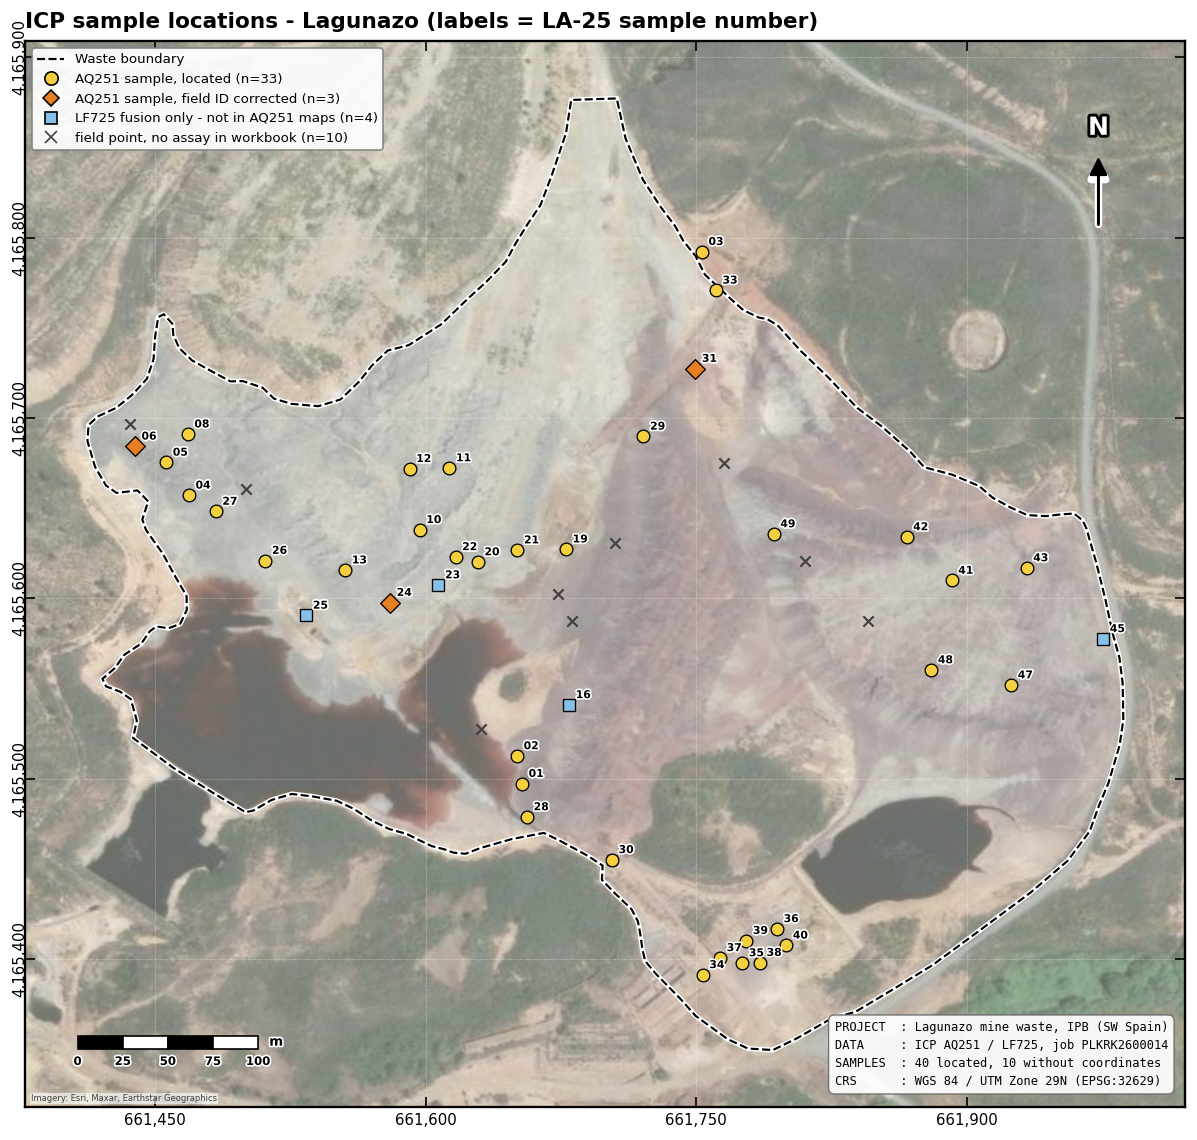

Figure 0 saved -> ICP_sample_locations_UTM29N.png


In [11]:
fig, ax = plt.subplots(figsize=(11, 9.6))
add_satellite_basemap(ax)
loc_only = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"])]
ax.scatter(loc_only["X_utm"], loc_only["Y_utm"], marker="x", s=38, c="0.25", lw=1.3, zorder=11)
_aq = has_aq[has_any].to_numpy()
s_ok = SAMP[LOCATED & _aq & (SAMP["ID_fix"] == "")]
s_fx = SAMP[LOCATED & _aq & (SAMP["ID_fix"] != "")]
s_lf = SAMP[LOCATED & ~_aq]
ax.scatter(s_lf["X_utm"], s_lf["Y_utm"], s=52, c="#85c1e9", marker="s", edgecolors="black", lw=0.8, zorder=12)
ax.scatter(s_ok["X_utm"], s_ok["Y_utm"], s=58, c="#f4d03f", edgecolors="black", lw=0.8, zorder=12)
ax.scatter(s_fx["X_utm"], s_fx["Y_utm"], s=70, c="#e67e22", marker="D", edgecolors="black", lw=0.8, zorder=12)
for _, r in SAMP[LOCATED].iterrows():
    ax.annotate(r["Sample"][-2:], (r["X_utm"], r["Y_utm"]), xytext=(4, 4), textcoords="offset points",
                fontsize=6.5, fontweight="bold", zorder=13,
                path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
add_map_furniture(ax)
ax.set_title("ICP sample locations - Lagunazo (labels = LA-25 sample number)",
             fontsize=13, fontweight="bold", loc="left", pad=8)
ax.legend(handles=[
    Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
    Line2D([0], [0], marker="o", color="w", mfc="#f4d03f", mec="black", ms=8,
           label=f"AQ251 sample, located (n={len(s_ok)})"),
    Line2D([0], [0], marker="D", color="w", mfc="#e67e22", mec="black", ms=7,
           label=f"AQ251 sample, field ID corrected (n={len(s_fx)})"),
    Line2D([0], [0], marker="s", color="w", mfc="#85c1e9", mec="black", ms=7,
           label=f"LF725 fusion only - not in AQ251 maps (n={len(s_lf)})"),
    Line2D([0], [0], marker="x", color="0.25", lw=0, ms=7,
           label=f"field point, no assay in workbook (n={len(loc_only)})")],
    loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5")
info_block(ax, [
    "PROJECT  : Lagunazo mine waste, IPB (SW Spain)",
    f"DATA     : ICP AQ251 / LF725, job {LAB_INFO.get('Job Number', '')}",
    f"SAMPLES  : {int(LOCATED.sum())} located, {int((~LOCATED).sum())} without coordinates",
    "CRS      : WGS 84 / UTM Zone 29N (EPSG:32629)"])
plt.tight_layout()
plt.savefig("ICP_sample_locations_UTM29N.png", dpi=400, bbox_inches="tight")
plt.show()
print("Figure 0 saved -> ICP_sample_locations_UTM29N.png")

## 7 · Detailed Workflow - Data Preparation for `VAR_NAME`

Censored values are substituted (Section 1 settings), replicates within 5 m are merged into stations, and a
cell-declustered mean is computed. The declustered mean, not the naive mean, is the global statistic to carry into
any volumetric estimate.

Station aggregation (Bi): 36 measurements -> 36 stations at a 5 m tolerance (0 with replicates)
Bi (ppm) - near-total (aqua regia)
  located assays      : 36  (quantified 36, <MDL 0, >UDL 0)
  stations            : 36
  min / median / max  : 5.34 / 80.67 / 672.7 ppm
  CV = 1.07   skewness = 2.26   log-skewness = -0.42
  declustering        : naive mean 139.7 -> declustered 128.2 ppm (-8.3 %, cell 61 m)


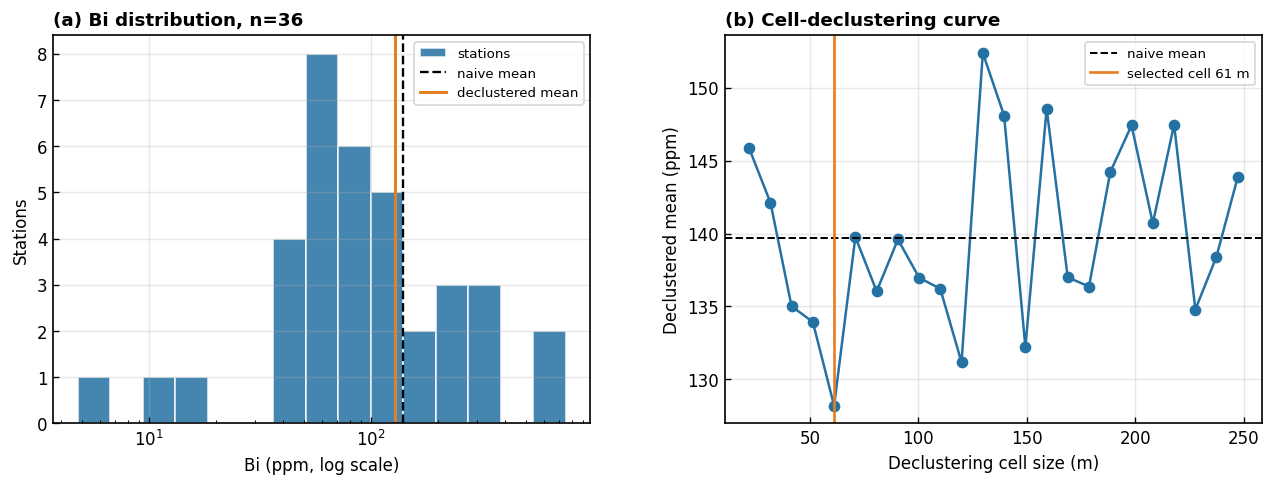

In [12]:
def element_points(el):
    """Located samples with an assay for `el`; censored values substituted, flag kept."""
    f = RAW_FLAG.loc[has_any, el].to_numpy()
    v = RAW_VAL.loc[has_any, el].to_numpy(float)
    z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v,
                 np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    d = pd.DataFrame({"Sample": SAMP["Sample"].to_numpy(), "X_utm": SAMP["X_utm"].to_numpy(),
                      "Y_utm": SAMP["Y_utm"].to_numpy(), el: z, "flag": f})
    return d[LOCATED & np.isfinite(z)].reset_index(drop=True)

def unit_of(el):
    return META.loc[el, "unit"]

def is_partial(el):
    return digestion_class(el).startswith("partial")

if VAR_NAME not in MAPPABLE:
    _r = CRM_TABLE.loc[CRM_TABLE["Analyte"] == VAR_NAME, "Reason not mapped"]
    raise ValueError(f"VAR_NAME='{VAR_NAME}' is not mappable ({_r.iloc[0] if len(_r) else 'not a CRM analyte'}). "
                     f"Choose one of: {MAPPABLE}")

UNIT = unit_of(VAR_NAME)
pts = element_points(VAR_NAME)
df_work, STATION_REPORT = station_means(pts, "X_utm", "Y_utm", VAR_NAME, tol_m=STATION_TOL_M,
                                        id_col="Sample", flag_col="flag")
vals_s = df_work[VAR_NAME].to_numpy(float)
xs_utm, ys_utm = df_work["X_utm"].to_numpy(float), df_work["Y_utm"].to_numpy(float)
coords_utm = np.column_stack([xs_utm, ys_utm])
N_SAMPLES = len(vals_s)
CENS = pts["flag"].value_counts().reindex(["ok", "bdl", "odl"]).fillna(0).astype(int)

DECLUS_W, DECLUS_CELL, DECLUS_TAB = declustering_weights(coords_utm, vals_s)
DECLUS = declustered_stats(vals_s, DECLUS_W)

print(f"{VAR_NAME} ({UNIT}) - {digestion_class(VAR_NAME)}")
print(f"  located assays      : {len(pts)}  (quantified {CENS['ok']}, <MDL {CENS['bdl']}, >UDL {CENS['odl']})")
if CENS["odl"]:
    print(f"  WARNING: {CENS['odl']} value(s) above the upper limit were set to the limit - LOWER BOUNDS: "
          f"{', '.join(pts.loc[pts['flag'] == 'odl', 'Sample'])}")
print(f"  stations            : {N_SAMPLES}")
print(f"  min / median / max  : {vals_s.min():,.4g} / {np.median(vals_s):,.4g} / {vals_s.max():,.4g} {UNIT}")
print(f"  CV = {vals_s.std(ddof=1) / vals_s.mean():.2f}   skewness = {stats.skew(vals_s):.2f}   "
      f"log-skewness = {stats.skew(np.log(vals_s)):.2f}")
print(f"  declustering        : naive mean {DECLUS['naive_mean']:,.4g} -> declustered "
      f"{DECLUS['declustered_mean']:,.4g} {UNIT} ({DECLUS['effect_pct']:+.1f} %, cell {DECLUS_CELL:.0f} m)")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"wspace": 0.25})
bins = np.logspace(np.log10(vals_s.min()) - 0.05, np.log10(vals_s.max()) + 0.05, 16)
axs[0].hist(vals_s, bins=bins, color="#2471a3", edgecolor="white", alpha=0.85, label="stations")
for fl, col, lab in (("bdl", "#7f8c8d", "<MDL (substituted)"), ("odl", "#e74c3c", ">UDL (lower bound)")):
    sel = df_work["flag"].str.contains(fl)
    if sel.any():
        axs[0].plot(vals_s[sel], np.full(sel.sum(), 0.3), "v", color=col, ms=9, label=lab)
axs[0].axvline(DECLUS["naive_mean"], color="black", ls="--", lw=1.4, label="naive mean")
axs[0].axvline(DECLUS["declustered_mean"], color="#e67e22", ls="-", lw=1.8, label="declustered mean")
axs[0].set_xscale("log"); axs[0].set_xlabel(f"{VAR_NAME} ({UNIT}, log scale)"); axs[0].set_ylabel("Stations")
axs[0].set_title(f"(a) {VAR_NAME} distribution, n={N_SAMPLES}", fontweight="bold", loc="left")
axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3)
axs[1].plot(DECLUS_TAB["cell_size_m"], DECLUS_TAB["declustered_mean"], "o-", color="#2471a3")
axs[1].axhline(DECLUS["naive_mean"], color="black", ls="--", lw=1.2, label="naive mean")
axs[1].axvline(DECLUS_CELL, color="#e67e22", lw=1.6, label=f"selected cell {DECLUS_CELL:.0f} m")
axs[1].set_xlabel("Declustering cell size (m)"); axs[1].set_ylabel(f"Declustered mean ({UNIT})")
axs[1].set_title("(b) Cell-declustering curve", fontweight="bold", loc="left")
axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
plt.savefig(f"IDW_{VAR_NAME}_distribution_declustering.png", dpi=300, bbox_inches="tight")
plt.show()

## 8 · Parameter Tuning (LOOCV)

Every combination of power *p*, maximum neighbours *k* and search radius is scored by leave-one-out RMSE on the stations, in the original units (after
back-transformation when `TRANSFORM = "log"`). Bias is reported as a diagnostic, not mixed into the score. An
optimum on the edge of the search grid is flagged, because the true optimum may then lie outside it.

**Selection rule.** With ~36 stations the LOOCV RMSE surface is typically flat: many parameter sets differ by less
than 1 %, which is far inside the sampling error of the RMSE itself, yet they can describe very different
neighbourhoods. Taking the strict minimum then picks the neighbourhood arbitrarily. With `SELECTION = "parsimony"`
all sets within `RMSE_TOL_PCT` (1 %) of the minimum are treated as equally accurate, and among them (i) the simplest
model is preferred — no search radius, i.e. a single continuous *k*-nearest neighbourhood, because a radius with a
*k*-nearest fallback switches abruptly between two neighbourhoods and draws artificial steps where they meet — then
(ii) the least conditional bias: the slope of the regression of observed on LOOCV-predicted values closest to 1, the
criterion used in kriging neighbourhood analysis (a slope below 1 means high estimates overstate the true grades). `SELECTION = "min_rmse"` restores the r8 rule. Note that
`Reg_slope` (predicted on observed, as in r8) measures smoothing, not conditional bias; both are reported.

**Search radius scaling.** The samples lie on traverses: the nearest-neighbour spacing (~22 m) measures the
along-line spacing, while the gaps between traverses are 60–150 m. A radius expressed as a multiple of the
nearest-neighbour spacing (the r8 convention) therefore rarely contains `MIN_NEIGHBORS` stations, and the estimator
silently degenerates to "k nearest at any distance". Here the radius is a multiple of `D_MINK`, the median distance
from a station to its `MIN_NEIGHBORS`-th nearest station, so that a factor of 1 gives half the stations a complete
minimum neighbourhood. Nodes that still lack `MIN_NEIGHBORS` stations inside the radius use the extended
(k-nearest) neighbourhood; this is an estimation mode, not by itself an extrapolation.

In [13]:
def median_spacing(coords):
    d, _ = cKDTree(coords).query(coords, k=2)
    nn = d[:, 1][np.isfinite(d[:, 1]) & (d[:, 1] > 0)]
    return float(np.median(nn)) if nn.size else float(GRID_DENSITY_M)


def dist_to_kth(coords, kth=None):
    """Median distance from a station to its kth nearest other station (kth = MIN_NEIGHBORS)."""
    kth = MIN_NEIGHBORS if kth is None else kth
    kth = int(min(kth, len(coords) - 1))
    d, _ = cKDTree(coords).query(coords, k=kth + 1)
    return float(np.median(np.asarray(d).reshape(len(coords), -1)[:, kth]))


def tune_idw(coords, vals, transform=None):
    transform = TRANSFORM if transform is None else transform
    n = len(vals)
    spacing = median_spacing(coords)
    d_mink = dist_to_kth(coords)
    yv = fwd(vals, transform)
    rows = []
    for p in P_VALUES:
        for k in K_VALUES:
            kk = int(min(k, n - 1))
            mk = int(min(MIN_NEIGHBORS, kk))
            for rf in RADIUS_FACTORS:
                rf = np.inf if rf is None else float(rf)        # inf = no radius (pure k-nearest)
                r = d_mink * rf
                pr, nfb = loocv_idw(coords, yv, float(p), kk, mk, r)
                m = metrics(vals, back(pr, transform), label=f"p={p:.2f} k={kk} rf={rf:g}")
                if m and m["n"] >= max(6, n // 3):
                    rows.append({**m, "p": float(p), "k_neighbors": kk, "min_neighbors": mk,
                                 "radius_factor": float(rf), "search_radius_m": r,
                                 "n_fallback": nfb, "median_spacing_m": spacing, "d_mink_m": d_mink})
    df = (pd.DataFrame(rows).drop_duplicates(subset=["p", "k_neighbors", "radius_factor"])
            .sort_values(["RMSE", "MAE"], kind="mergesort").reset_index(drop=True))
    if df.empty:
        raise ValueError("No valid LOOCV parameter combinations were produced.")
    return df, spacing


def select_best(df):
    """Adopt a parameter set from the RMSE-sorted tuning table.

    'min_rmse'     : lowest LOOCV RMSE (r8 behaviour).
    'parsimony'    : sets within RMSE_TOL_PCT % of the minimum are treated as equally accurate; among them the
                     simplest model is preferred (no search radius, i.e. one parameter fewer and no switching
                     between two neighbourhoods), then the observed-on-predicted slope closest to 1 (least
                     conditional bias), then the fewest extended-neighbourhood predictions, then RMSE.
    Returns (row, n_equivalent)."""
    if SELECTION == "min_rmse":
        return df.iloc[0], 1
    eq = df[df["RMSE"] <= df["RMSE"].min() * (1 + RMSE_TOL_PCT / 100)].copy()
    eq["_has_radius"] = np.isfinite(eq["search_radius_m"]).astype(int)
    eq["_slope_dev"] = (eq["Slope_obs_on_pred"] - 1).abs().round(3)
    eq = eq.sort_values(["_has_radius", "_slope_dev", "n_fallback", "RMSE"], kind="mergesort")
    return eq.drop(columns=["_has_radius", "_slope_dev"]).iloc[0], len(eq)


def edge_flags(best, n):
    fl = []
    if best["p"] <= P_VALUES.min() or best["p"] >= P_VALUES.max():
        fl.append(f"p={best['p']:.2f} on the edge of P_VALUES")
    kmax = min(max(K_VALUES), n - 1)
    if best["k_neighbors"] <= min(K_VALUES) or best["k_neighbors"] >= kmax:
        fl.append(f"k={int(best['k_neighbors'])} on the edge of K_VALUES")
    finite = [f for f in RADIUS_FACTORS if f is not None]
    if np.isfinite(best["radius_factor"]) and finite and best["radius_factor"] <= min(finite):
        fl.append(f"radius factor {best['radius_factor']:g} on the lower edge of RADIUS_FACTORS")
    return fl


t0 = time.time()
tuning_df, spacing_m = tune_idw(coords_utm, vals_s)
D_MINK = float(tuning_df["d_mink_m"].iloc[0])
print(f"Median nearest-neighbour spacing        : {spacing_m:.1f} m")
print(f"Median distance to {MIN_NEIGHBORS}th nearest station (D_MINK): {D_MINK:.1f} m  -> radii "
      f"{', '.join('none' if f is None else f'{D_MINK * f:.0f}' for f in RADIUS_FACTORS)} m")
print(f"Tuning complete in {time.time() - t0:.1f}s - {len(tuning_df)} parameter sets evaluated\n")
print("Top 10 parameter combinations (ranked by cross-validated RMSE):")
display(tuning_df[["p", "k_neighbors", "radius_factor", "search_radius_m", "n_fallback",
                   "RMSE", "MAE", "ME_bias", "R2_pred", "Reg_slope", "Slope_obs_on_pred", "Var_ratio"]].head(10).round(3))

best, N_EQUIV = select_best(tuning_df)
BEST_RANK = int(best.name) + 1
BEST_P    = float(best["p"])
BEST_K    = int(best["k_neighbors"])
BEST_MINK = int(best["min_neighbors"])
BEST_RF   = float(best["radius_factor"])
BEST_RAD  = float(best["search_radius_m"])
EDGE      = edge_flags(best, N_SAMPLES)

print(f"\nSelection ({SELECTION}): {N_EQUIV} parameter set(s) within {RMSE_TOL_PCT:g} % of the minimum RMSE "
      f"({tuning_df['RMSE'].min():,.4g} {UNIT}); adopted set = rank {BEST_RANK} by RMSE.")
print(f"RMSE range over all {len(tuning_df)} sets: {tuning_df['RMSE'].min():,.4g} - {tuning_df['RMSE'].max():,.4g} "
      f"{UNIT} ({100 * (tuning_df['RMSE'].max() / tuning_df['RMSE'].min() - 1):.1f} % spread)")
print("=" * 58)
print(f"  CROSS-VALIDATION-OPTIMAL IDW PARAMETERS - {VAR_NAME}")
print("=" * 58)
print(f"  Power (p)        : {BEST_P:.2f}")
print(f"  Neighbours (k)   : {BEST_K}" + (f"   (min {BEST_MINK} inside the radius)" if np.isfinite(best["search_radius_m"]) else ""))
HAS_RADIUS = bool(np.isfinite(BEST_RAD))
RAD_TXT = f"{BEST_RAD:.0f} m" if HAS_RADIUS else "none"
if HAS_RADIUS:
    print(f"  Search radius    : {BEST_RAD:.0f} m  ({BEST_RF:g} x D_MINK {D_MINK:.1f} m)")
    print(f"  Extended nbhd    : {int(best['n_fallback'])} of {N_SAMPLES} LOOCV predictions use the k nearest "
          f"(< {BEST_MINK} stations within {BEST_RAD:.0f} m)")
else:
    print(f"  Search radius    : none - pure {BEST_K}-nearest neighbourhood (continuous, no mode switching)")
print(f"  LOOCV RMSE       : {best['RMSE']:,.4g} {UNIT}   ({best['Rel_RMSE_pct']:.1f} % of mean)")
print(f"  LOOCV R2         : {best['R2_pred']:.3f}   slope obs-on-pred {best['Slope_obs_on_pred']:.3f} "
      f"(pred-on-obs {best['Reg_slope']:.3f})")
print("=" * 58)
for e in EDGE:
    print(f"  NOTE: {e} - the optimum may lie outside the searched range; widen the grid if this matters.")

Median nearest-neighbour spacing        : 22.1 m
Median distance to 4th nearest station (D_MINK): 59.6 m  -> radii none, 45, 60, 74, 89, 119, 149 m
Tuning complete in 2.7s - 616 parameter sets evaluated

Top 10 parameter combinations (ranked by cross-validated RMSE):


,p,k_neighbors,radius_factor,search_radius_m,n_fallback,RMSE,MAE,ME_bias,R2_pred,Reg_slope,Slope_obs_on_pred,Var_ratio
0,1.75,24,0.75,44.7,25,109.062,74.154,5.982,0.450,0.482,0.941,0.512
1,2.00,24,inf,inf,0,109.084,74.696,6.335,0.450,0.496,0.918,0.540
2,2.00,20,inf,inf,0,109.126,74.860,6.507,0.449,0.500,0.912,0.548
3,1.75,20,0.75,44.7,25,109.139,74.308,6.169,0.449,0.486,0.933,0.521
4,1.75,20,inf,inf,0,109.182,74.330,4.603,0.449,0.469,0.961,0.488
5,1.50,24,0.75,44.7,25,109.198,74.100,3.970,0.449,0.452,0.994,0.454
6,1.50,20,0.75,44.7,25,109.204,74.285,4.257,0.448,0.458,0.981,0.467
7,1.75,24,inf,inf,0,109.211,74.169,4.343,0.448,0.463,0.972,0.476
8,2.00,24,0.75,44.7,25,109.312,74.887,7.638,0.447,0.508,0.898,0.566
9,2.25,24,inf,inf,0,109.334,75.196,7.924,0.447,0.523,0.878,0.596



Selection (parsimony): 108 parameter set(s) within 1 % of the minimum RMSE (109.1 ppm); adopted set = rank 31 by RMSE.
RMSE range over all 616 sets: 109.1 - 125.4 ppm (15.0 % spread)
  CROSS-VALIDATION-OPTIMAL IDW PARAMETERS - Bi
  Power (p)        : 1.50
  Neighbours (k)   : 20
  Search radius    : none - pure 20-nearest neighbourhood (continuous, no mode switching)
  LOOCV RMSE       : 109.8 ppm   (78.6 % of mean)
  LOOCV R2         : 0.442   slope obs-on-pred 1.026 (pred-on-obs 0.432)


## 9 · Validation & Performance Metrics

The ICP set has no independent hold-out samples, so leave-one-out cross-validation at the adopted parameters is the
only performance measure. Because the same LOOCV was used to choose the parameters, the reported error is mildly
optimistic (selection effect). Section 11 compares the tuned RMSE with a fixed default parameter set as an
indication of how much the tuning gains; that comparison is not a nested cross-validation.

In [14]:
preds_t, N_FALLBACK_CV = loocv_idw(coords_utm, fwd(vals_s), BEST_P, BEST_K, BEST_MINK, BEST_RAD)
preds_cv = back(preds_t)

cv_df = df_work.rename(columns={"X_utm": "X_utm", "Y_utm": "Y_utm"}).copy()
cv_df["Predicted_LOOCV"] = preds_cv
cv_df["Residual"] = preds_cv - vals_s
cv_df["Abs_Error"] = np.abs(cv_df["Residual"])

cv_metrics = metrics(vals_s, preds_cv, label="LOOCV")
metrics_tbl = pd.DataFrame([cv_metrics]).set_index("Label")
print(f"LOOCV: {int(np.isfinite(preds_cv).sum())} / {N_SAMPLES} stations predicted "
      f"({N_FALLBACK_CV} with the extended k-nearest neighbourhood)")
print("=" * 62); print(f"  LOOCV PERFORMANCE METRICS - {VAR_NAME} ({UNIT})"); print("=" * 62)
display(metrics_tbl.round(4))

res = cv_df["Residual"].dropna()
res_stats = pd.DataFrame({
    "Statistic": ["Min", "P5", "P25", "Median", "P75", "P95", "Max", "IQR", "Std"],
    f"Value ({UNIT})": [res.min(), res.quantile(.05), res.quantile(.25), res.median(), res.quantile(.75),
                        res.quantile(.95), res.max(), res.quantile(.75) - res.quantile(.25), res.std()],
}).set_index("Statistic")
print("\nLOOCV residual statistics (estimate - observed):")
display(res_stats.round(4))
interpret_metrics(cv_metrics, UNIT)

LOOCV: 36 / 36 stations predicted (0 with the extended k-nearest neighbourhood)
  LOOCV PERFORMANCE METRICS - Bi (ppm)


,n,RMSE,MAE,ME_bias,Rel_bias_pct,Rel_RMSE_pct,R2_pred,Pearson_r,Spearman_r,Reg_slope,Slope_obs_on_pred,Obs_min,Obs_max,Est_min,Est_max,Var_ratio
Label,,,,,,,,,,,,,,,,
LOOCV,36,109.8137,74.0298,2.3026,1.648,78.5935,0.4423,0.6655,0.6474,0.4317,1.0259,5.34,672.68,38.532,416.2699,0.4207



LOOCV residual statistics (estimate - observed):


,Value (ppm)
Statistic,
Min,-321.2703
P5,-226.8029
P25,-30.1037
Median,14.6280
P75,48.0004
P95,154.5222
Max,248.4883
IQR,78.1041
Std,111.3470



Interpretation of LOOCV:
  R2 = 0.442: moderate-to-good predictive skill for an exact interpolator.
  Variance ratio 0.42: the estimates carry < 50 % of the data variance (strong smoothing);
     tonnage above a cut-off read from this surface is not reliable.
  Slope of predicted on observed 0.43: strong smoothing - highs under-, lows over-estimated.
  Slope of observed on predicted 1.03: close to 1 - estimates are conditionally unbiased.


## 10 · Interpolation Grid

The grid spans the boundary's bounding box at `GRID_DENSITY_M` and is masked to the polygon. Estimates use the
adopted parameters and **the same neighbourhood rule as the LOOCV**. Three layers are kept: the grade estimate, the
distance to the nearest station (data support) and the neighbourhood flag (1 = extended k-nearest neighbourhood).
Nodes farther from every station than `EXTRAP_DIST_M` (default: the largest station-to-nearest-station distance, i.e.
outside the sampled configuration) are treated as extrapolations and hatched on the grade maps. All three are exported as ESRI ASCII rasters (UTM 29N, cell-centre registered).

In [15]:
def nice_breaks(vmin, vmax, n=7):
    """Rounded equal-interval class breaks spanning [vmin, vmax] (GIS style)."""
    raw = (vmax - vmin) / max(n, 1)
    if raw <= 0:
        return np.linspace(vmin, vmax + 1e-9, n + 1)
    mag = 10 ** np.floor(np.log10(raw))
    step = max(round(raw / mag) * mag, mag)
    edges = [np.floor(vmin / step) * step]
    while edges[-1] < vmax:
        edges.append(edges[-1] + step)
    return np.array(edges)


def class_breaks(zgrid, svals, scheme=None, n=N_GRADE_CLASSES):
    """Class breaks covering both the grid estimates and the station values."""
    scheme = CLASS_SCHEME if scheme is None else scheme
    zv = np.concatenate([np.asarray(zgrid)[np.isfinite(zgrid)], np.asarray(svals, float)])
    lo, hi = float(zv.min()), float(zv.max())
    if scheme == "quantile":
        q = np.nanpercentile(svals, [0, 10, 25, 50, 75, 90, 95, 100])
        q = np.unique([float(f"{v:.3g}") for v in q])
        q[0], q[-1] = min(q[0], lo), max(q[-1], hi)
        return q
    return nice_breaks(lo, hi, n)


def crm_breaks(el, zgrid, svals, scheme):
    """Class breaks for one element. If any station is below detection (<MDL, plotted at BDL_FACTOR x MDL), the
    lowest class is [minimum, MDL) = '<MDL' and the other classes are built from the DETECTED station values only
    (percentiles or equal intervals), so tied substituted values cannot collapse the legend into one or two classes.
    Returns (breaks, mdl or None)."""
    sv = np.asarray(svals, float)
    mdl = float(META.loc[el, "mdl"])
    if not (CENSORED_CLASS and np.any(sv < mdl * (1 - 1e-9))):
        return class_breaks(zgrid, sv, scheme), None
    zv = np.concatenate([np.asarray(zgrid)[np.isfinite(zgrid)], sv])
    lo, hi = float(zv.min()), float(zv.max())
    det = sv[sv >= mdl * (1 - 1e-9)]
    if scheme == "quantile" and det.size >= 4:
        q = np.unique([float(f"{x:.3g}") for x in np.nanpercentile(det, [0, 25, 50, 75, 90, 100])])
    else:
        q = nice_breaks(mdl, max(hi, mdl * 1.001), max(N_GRADE_CLASSES - 1, 2))
    upper = [float(x) for x in q if x > mdl * (1 + 1e-9)]
    if not upper:
        upper = [max(hi, mdl * 1.5)]
    upper[-1] = max(upper[-1], hi)
    edges = np.array(sorted(set([min(lo, mdl * BDL_FACTOR), mdl] + upper)))
    return edges, mdl


def crm_formatter(breaks, mdl):
    """Colour-bar labels: the '<MDL' class ends at the tick labelled 'MDL x'; its bottom edge is left blank."""
    if mdl is None:
        return mticker.FuncFormatter(lambda v, _=None: fmt_num(v))
    def f(v, _=None):
        if abs(v - breaks[0]) <= 1e-9 * max(abs(breaks[0]), 1e-300):
            return ""
        if abs(v - mdl) <= 1e-6 * max(abs(mdl), 1e-300):
            return f"MDL {fmt_num(mdl)}"
        return fmt_num(v)
    return mticker.FuncFormatter(f)


MDL_CLASS_COLOUR = "#b3b3b3"      # the '<MDL' class is drawn in neutral grey, graded classes in GRADE_CMAP

def crm_cmap(breaks, mdl):
    """Class colours: GRADE_CMAP, with a grey first class when that class is '<MDL'."""
    n = len(breaks) - 1
    if mdl is None:
        return plt.get_cmap(GRADE_CMAP, n)
    base = plt.get_cmap(GRADE_CMAP, max(n - 1, 1))
    return ListedColormap([MDL_CLASS_COLOUR] + [base(i) for i in range(max(n - 1, 1))][: n - 1])


RELIABILITY_COLOUR = {"predictive": "#1e8449", "weak": "#b9770e", "no skill": "#922b21"}

def reliability_class(r2):
    """Cross-validated reliability of a surface: predictive (R2 >= MIN_R2_SURFACE), weak (0 <= R2 < MIN_R2_SURFACE)
    or no skill (R2 < 0: worse than predicting the mean everywhere - the surface is descriptive only)."""
    if r2 is None or not np.isfinite(r2) or r2 < 0:
        return "no skill"
    return "predictive" if r2 >= MIN_R2_SURFACE else "weak"


def censor_line(el, svals):
    """Info-block line for censored elements."""
    mdl = float(META.loc[el, "mdl"])
    nb = int(np.sum(np.asarray(svals, float) < mdl * (1 - 1e-9)))
    if not nb:
        return None
    s = (f"CENSORED : {nb} of {len(svals)} stations <MDL ({fmt_num(mdl)} {unit_of(el)}), plotted at "
         f"{BDL_FACTOR:g} x MDL")
    if nb > 0.5 * len(svals):
        s += "\nNOTE     : mostly below detection - read as detection zones, not grades"
    _q = CRM_TABLE.loc[CRM_TABLE["Analyte"] == el, "Detection quality"]
    if len(_q) and _q.iloc[0]:
        s += "\nNOTE     : all detections < 3 x MDL - presence not firmly established"
    return s


def write_esri_ascii(path, Z2D, gx, gy, cellsize, nodata=-9999.0):
    """Write a 2-D grid (row 0 = south) as an ESRI ASCII raster for ArcGIS/QGIS/Surfer."""
    arr = np.where(np.isfinite(Z2D), Z2D, nodata)[::-1, :]
    with open(path, "w") as f:
        f.write(f"ncols {arr.shape[1]}\nnrows {arr.shape[0]}\n")
        f.write(f"xllcorner {gx.min() - cellsize / 2:.3f}\nyllcorner {gy.min() - cellsize / 2:.3f}\n")
        f.write(f"cellsize {cellsize:.4f}\nNODATA_value {nodata}\n")
        np.savetxt(f, arr, fmt="%.6g")


# 1. Regular UTM grid over the boundary bounding box
xi = np.arange(xmin_u, xmax_u + GRID_DENSITY_M, GRID_DENSITY_M)
yi = np.arange(ymin_u, ymax_u + GRID_DENSITY_M, GRID_DENSITY_M)
XG, YG = np.meshgrid(xi, yi)
NROW, NCOL = XG.shape
grid_pts = np.column_stack([XG.ravel(), YG.ravel()])
in_hull = inside_domain(XG.ravel(), YG.ravel()).reshape(NROW, NCOL)
inside_flat = in_hull.ravel()
print(f"Grid: {NCOL} x {NROW} = {NROW * NCOL:,} nodes at {GRID_DENSITY_M:g} m; "
      f"{int(in_hull.sum()):,} inside the {BND_LABEL}")

# 2. IDW with the shared rule
t0 = time.time()
tree = cKDTree(coords_utm)
z_t, fb_flat, nused_flat, reach_flat = idw_grid(grid_pts, coords_utm, fwd(vals_s), BEST_P, BEST_K, BEST_MINK,
                                               BEST_RAD, tree=tree)
Z_raw = back(z_t).reshape(NROW, NCOL)
D_raw = tree.query(grid_pts, k=1)[0].reshape(NROW, NCOL)
print(f"  Interpolated in {time.time() - t0:.2f}s")

# 3. Clip to the domain
Z_grid  = np.where(in_hull, Z_raw, np.nan)
D_grid  = np.where(in_hull, D_raw, np.nan)
FB_grid = np.where(in_hull, fb_flat.reshape(NROW, NCOL).astype(float), np.nan)

# 4. Optional display-only smoothing (off by default; the raw surface is what is reported)
if SMOOTH_SIGMA > 0:
    from scipy.ndimage import distance_transform_edt
    Z_fill = Z_grid.copy(); nan_mask = ~np.isfinite(Z_fill)
    if nan_mask.any():
        _, nidx = distance_transform_edt(nan_mask, return_distances=True, return_indices=True)
        Z_fill[nan_mask] = Z_raw[tuple(nidx[:, nan_mask])]
    Z_disp = np.where(in_hull, gaussian_filter(Z_fill, sigma=SMOOTH_SIGMA), np.nan)
else:
    Z_disp = Z_grid

# 5. Classes
grade_breaks = class_breaks(Z_disp, vals_s)
grade_cmap = plt.get_cmap(GRADE_CMAP, len(grade_breaks) - 1)
grade_norm = BoundaryNorm(grade_breaks, grade_cmap.N)
_dv = D_grid[np.isfinite(D_grid)]
supp_breaks = nice_breaks(float(_dv.min()), float(np.nanpercentile(_dv, 98)), N_SUPPORT_CLASSES)
supp_cmap = plt.get_cmap(SUPPORT_CMAP, len(supp_breaks) - 1)
supp_norm = BoundaryNorm(supp_breaks, supp_cmap.N)
P90_THR = float(np.nanpercentile(vals_s, 90))
FB_SHARE = float(np.nanmean(FB_grid))

def extrap_distance(coords):
    if EXTRAP_DIST_M is not None:
        return float(EXTRAP_DIST_M)
    return float(cKDTree(coords).query(coords, k=2)[0][:, 1].max())

EXTRAP_D = extrap_distance(coords_utm)
EX_grid = np.where(in_hull, (D_raw > EXTRAP_D).astype(float), np.nan)
EX_SHARE = float(np.nanmean(EX_grid))

# 6. Rasters
write_esri_ascii(f"IDW_{VAR_NAME}_grade_UTM29N.asc", Z_grid, xi, yi, GRID_DENSITY_M)
write_esri_ascii(f"IDW_{VAR_NAME}_support_dist_UTM29N.asc", D_grid, xi, yi, GRID_DENSITY_M)
REACH_grid = np.where(in_hull, reach_flat.reshape(NROW, NCOL), np.nan)
if HAS_RADIUS:
    write_esri_ascii(f"IDW_{VAR_NAME}_extended_nbhd_flag_UTM29N.asc", FB_grid, xi, yi, GRID_DENSITY_M)

print(f"  Grade range   : {np.nanmin(Z_grid):,.4g} - {np.nanmax(Z_grid):,.4g} {UNIT} "
      f"(stations {vals_s.min():,.4g} - {vals_s.max():,.4g})")
print(f"  Grade classes : {[float(f'{b:.4g}') for b in grade_breaks]}  ({CLASS_SCHEME})")
print(f"  P90 (stations): {P90_THR:,.4g} {UNIT}")
print(f"  Neighbourhood : " + (f"{100 * FB_SHARE:.1f} % of the domain uses the extended {BEST_K}-nearest set "
      f"(fewer than {BEST_MINK} stations within {BEST_RAD:.0f} m)" if HAS_RADIUS else
      f"pure {BEST_K}-nearest; reach (farthest station used) median {np.nanmedian(REACH_grid):.0f} m"))
print(f"  Extrapolation : {100 * EX_SHARE:.1f} % of the domain lies > {EXTRAP_D:.0f} m from any station "
      f"(largest station-to-nearest-station gap)")
print(f"  Exported      : IDW_{VAR_NAME}_grade / _support_dist" + (" / _extended_nbhd_flag" if HAS_RADIUS else "")
      + " _UTM29N.asc")

Grid: 193 x 177 = 34,161 nodes at 3 m; 18,041 inside the Waste area polygon
  Interpolated in 0.20s
  Grade range   : 12.75 - 655.5 ppm (stations 5.34 - 672.7)
  Grade classes : [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0]  (equal)
  P90 (stations): 306.6 ppm
  Neighbourhood : pure 20-nearest; reach (farthest station used) median 231 m
  Extrapolation : 16.7 % of the domain lies > 74 m from any station (largest station-to-nearest-station gap)
  Exported      : IDW_Bi_grade / _support_dist _UTM29N.asc


## 11 · Methodology Audit of the Spatial Interpolation

Each statement about the interpolation is tested numerically. **FAIL** means the workflow is logically wrong and must
be fixed before any map is used; **WARN** means the map is valid but a limitation must be reported with it.

In [16]:
AUDIT = []
def audit(check, status, detail):
    AUDIT.append(dict(Check=check, Status=status, Detail=detail))

yv_s = fwd(vals_s)

# 1 Projection and units
ok = (166_000 < xs_utm.min() < 834_000) and (3_000_000 < ys_utm.min() < 9_400_000)
audit("Coordinates projected to UTM 29N (metres)", "PASS" if ok else "FAIL",
      f"E {xs_utm.min():.0f}-{xs_utm.max():.0f}, N {ys_utm.min():.0f}-{ys_utm.max():.0f}")

# 2 Stations inside the domain
n_out = int((~inside_domain(xs_utm, ys_utm)).sum())
audit("All stations inside the mapping domain", "PASS" if n_out == 0 else "WARN",
      f"{n_out} station(s) outside the {BND_LABEL}" + (" - they still inform nearby nodes" if n_out else ""))

# 3 No coincident stations (LOOCV independence)
d_nn = cKDTree(coords_utm).query(coords_utm, k=2)[0][:, 1]
audit("Stations unique (no replicate leakage in LOOCV)", "PASS" if d_nn.min() > STATION_TOL_M else "FAIL",
      f"minimum inter-station distance {d_nn.min():.1f} m (> {STATION_TOL_M:g} m tolerance)")

# 4 Grid rule == point-by-point rule
rng = np.random.default_rng(1)
sel = rng.choice(np.flatnonzero(inside_flat), size=min(400, int(inside_flat.sum())), replace=False)
ref = np.array([idw_point(grid_pts[i], coords_utm, yv_s, tree, p=BEST_P, k=BEST_K, min_k=BEST_MINK,
                          radius=BEST_RAD) for i in sel])
dmax = float(np.nanmax(np.abs(ref - z_t[sel])))
audit("Vectorised grid IDW = point-by-point IDW (400 random nodes)", "PASS" if dmax < 1e-8 else "FAIL",
      f"max |difference| = {dmax:.2e}")

# 5 Fast LOOCV == brute-force LOOCV (tree rebuilt without each station)
bf = loocv_idw_bruteforce(coords_utm, yv_s, BEST_P, BEST_K, BEST_MINK, BEST_RAD)
dmax = float(np.nanmax(np.abs(bf - preds_t)))
audit("Vectorised LOOCV = brute-force LOOCV", "PASS" if dmax < 1e-8 else "FAIL",
      f"max |difference| = {dmax:.2e} over {N_SAMPLES} stations")

# 6 LOOCV and grid share the neighbourhood
audit("LOOCV and grid use identical p, k, min_k, radius and rule", "PASS",
      f"p={BEST_P:.2f}, k={BEST_K}, min_k={BEST_MINK}, r={RAD_TXT}, via _idw_rule")

# 7 Exact interpolator
z_at, _, _, _ = idw_grid(coords_utm, coords_utm, yv_s, BEST_P, BEST_K, BEST_MINK, BEST_RAD)
dmax = float(np.max(np.abs(back(z_at) - vals_s)))
audit("Exact at stations (IDW honours the data)", "PASS" if dmax < 1e-9 * max(1, vals_s.max()) else "FAIL",
      f"max |estimate - value| at stations = {dmax:.2e}")

# 8 Convexity (no values outside the data range)
lo_ok = np.nanmin(Z_grid) >= vals_s.min() - 1e-9
hi_ok = np.nanmax(Z_grid) <= vals_s.max() + 1e-9
audit("Estimates within the station range (convex weights)", "PASS" if lo_ok and hi_ok else "FAIL",
      f"grid {np.nanmin(Z_grid):,.4g}-{np.nanmax(Z_grid):,.4g} vs stations {vals_s.min():,.4g}-{vals_s.max():,.4g}")

# 9 Parameter optimum inside the search grid
audit("Adopted parameters inside the search grid", "PASS" if not EDGE else "WARN",
      "; ".join(EDGE) if EDGE else f"p={BEST_P:.2f}, k={BEST_K}, rf={BEST_RF:g}")
_spread = 100 * (tuning_df["RMSE"].max() / tuning_df["RMSE"].min() - 1)
audit("Flatness of the LOOCV RMSE surface", "INFO",
      f"{N_EQUIV} of {len(tuning_df)} sets within {RMSE_TOL_PCT:g} % of the minimum; total spread {_spread:.1f} % - "
      + ("parameter choice is immaterial to accuracy; selection rule decides the neighbourhood"
         if _spread < 10 else "parameters matter; the optimum is well defined"))

# 10 Selection optimism
_def = tuning_df[(tuning_df["p"] == 2.0) & (tuning_df["k_neighbors"] == min(8, N_SAMPLES - 1))
                 & (tuning_df["radius_factor"] == 1.5)]
if len(_def):
    gain = 100 * (1 - tuning_df["RMSE"].min() / _def.iloc[0]["RMSE"])
    audit("Parameter-selection gain vs default (p=2, k=8, r=1.5 D_MINK)", "PASS" if gain < 15 else "WARN",
          f"best RMSE {tuning_df['RMSE'].min():,.4g} vs default {_def.iloc[0]['RMSE']:,.4g} {UNIT} ({gain:.1f} % lower); "
          + ("small gain - the result is not an artefact of tuning" if gain < 15 else
             "large gain - partly optimistic because the same LOOCV selects and scores"))

# 11 Censoring
cfrac = 1 - CENS["ok"] / CENS.sum()
audit("Censored share within the mapping rule", "PASS" if cfrac <= 1 - MIN_QUANT_FRAC and CENS["odl"] == 0
      else "WARN", f"below MDL {CENS['bdl']}, above UDL {CENS['odl']} of {CENS.sum()} ({100 * cfrac:.0f} %)"
      + ("; above-UDL values are lower bounds - local maxima under-estimated" if CENS["odl"] else ""))

# 12 Predictive skill
r2 = cv_metrics["R2_pred"]
audit(f"LOOCV predictive skill (R2 >= {MIN_R2_SURFACE:g})", "PASS" if r2 >= MIN_R2_SURFACE else "WARN",
      f"R2 = {r2:.3f}, slope obs-on-pred = {cv_metrics['Slope_obs_on_pred']:.2f}, variance ratio = "
      f"{cv_metrics['Var_ratio']:.2f}"
      + ("" if r2 >= MIN_R2_SURFACE else " - map shows the data pattern, not a validated grade model"))

# 13 Extrapolation share
audit("Extrapolated share of the mapping domain", "PASS" if EX_SHARE < 0.20 else "WARN",
      f"{100 * EX_SHARE:.1f} % of the domain lies > {EXTRAP_D:.0f} m from any station (hatched on the grade maps)")
# Mode switching: with a radius + k-nearest fallback, adjacent nodes can use different neighbourhoods.
_Zs = np.where(in_hull, Z_raw, np.nan)
_steps, _switch = [], []
for _a, _b, _fa, _fb in ((_Zs[:, 1:], _Zs[:, :-1], FB_grid[:, 1:], FB_grid[:, :-1]),
                         (_Zs[1:, :], _Zs[:-1, :], FB_grid[1:, :], FB_grid[:-1, :])):
    ok_ = np.isfinite(_a) & np.isfinite(_b)
    _steps.append(np.abs(_a - _b)[ok_]); _switch.append((_fa != _fb)[ok_])
_steps, _switch = np.concatenate(_steps), np.concatenate(_switch)
if HAS_RADIUS and _switch.any():
    _ratio = np.median(_steps[_switch]) / max(np.median(_steps[~_switch]), 1e-12)
    audit("Neighbourhood mode switching (radius + k-nearest fallback)", "PASS" if _ratio < 3 else "WARN",
          f"{100 * FB_SHARE:.1f} % of nodes extended; median step between adjacent nodes {np.median(_steps[_switch]):,.3g} "
          f"{UNIT} where the mode switches vs {np.median(_steps[~_switch]):,.3g} elsewhere ({_ratio:.0f}x)"
          + (" - class boundaries there are partly artefacts of the rule" if _ratio >= 3 else ""))
else:
    audit("Neighbourhood mode switching (radius + k-nearest fallback)", "PASS",
          f"no search radius - one continuous {BEST_K}-nearest neighbourhood; median adjacent-node step "
          f"{np.median(_steps):,.3g} {UNIT}")

# 14 Analytical precision vs spatial error
rpd = QC_DUP.loc[QC_DUP["Element"] == VAR_NAME, "RPD_pct"]
audit("Analytical precision << spatial prediction error", "PASS" if (len(rpd) == 0 or
      rpd.iloc[0] < cv_metrics["Rel_RMSE_pct"] / 3) else "WARN",
      (f"pulp-duplicate RPD {rpd.iloc[0]:.1f} % vs LOOCV relative RMSE {cv_metrics['Rel_RMSE_pct']:.0f} % "
       "- the error is spatial (short-range variability), not analytical") if len(rpd)
      else "no duplicate >= 10 x MDL for this element")

# 15 Digestion
audit("Digestion is total for this element", "WARN" if is_partial(VAR_NAME) else "PASS",
      digestion_class(VAR_NAME) + (" - the map shows aqua-regia-extractable concentrations"
                                   if is_partial(VAR_NAME) else ""))

# 16 Declustering
audit("Clustering effect on the global mean", "PASS" if abs(DECLUS["effect_pct"]) < 10 else "WARN",
      f"declustered mean {DECLUS['declustered_mean']:,.4g} vs naive {DECLUS['naive_mean']:,.4g} {UNIT} "
      f"({DECLUS['effect_pct']:+.1f} %)")

# 17 Transform sensitivity (information only)
_alt = "log" if TRANSFORM == "none" else "none"
_tdf_alt, _ = tune_idw(coords_utm, vals_s, transform=_alt)
audit(f"Transform sensitivity (TRANSFORM='{_alt}' instead of '{TRANSFORM}')", "INFO",
      f"minimum LOOCV RMSE {_tdf_alt.iloc[0]['RMSE']:,.4g} vs {tuning_df.iloc[0]['RMSE']:,.4g} {UNIT}, R2 "
      f"{_tdf_alt.iloc[0]['R2_pred']:.3f} vs {tuning_df.iloc[0]['R2_pred']:.3f} (like-for-like minima)"
      + (" - log-IDW back-transforms to a median-type (geometric) estimate and is biased low for means"
         if _alt == "log" else ""))

AUDIT_TBL = pd.DataFrame(AUDIT)
show_table(AUDIT_TBL, status_col="Status")
if (AUDIT_TBL["Status"] == "FAIL").any():
    raise RuntimeError("Methodology audit FAILED - see the table above.")
print(f"Audit: {int((AUDIT_TBL['Status'] == 'PASS').sum())} PASS, "
      f"{int((AUDIT_TBL['Status'] == 'WARN').sum())} WARN, 0 FAIL")

Check,Status,Detail
Coordinates projected to UTM 29N (metres),PASS,"E 661439-661933, N 4165391-4165792"
All stations inside the mapping domain,WARN,1 station(s) outside the Waste area polygon - they still inform nearby nodes
Stations unique (no replicate leakage in LOOCV),PASS,minimum inter-station distance 9.8 m (> 5 m tolerance)
Vectorised grid IDW = point-by-point IDW (400 random nodes),PASS,max |difference| = 1.71e-13
Vectorised LOOCV = brute-force LOOCV,PASS,max |difference| = 1.14e-13 over 36 stations
"LOOCV and grid use identical p, k, min_k, radius and rule",PASS,"p=1.50, k=20, min_k=4, r=none, via _idw_rule"
Exact at stations (IDW honours the data),PASS,max |estimate - value| at stations = 0.00e+00
Estimates within the station range (convex weights),PASS,grid 12.75-655.5 vs stations 5.34-672.7
Adopted parameters inside the search grid,PASS,"p=1.50, k=20, rf=inf"
Flatness of the LOOCV RMSE surface,INFO,108 of 616 sets within 1 % of the minimum; total spread 15.0 % - parameters matter; the optimum is well defined


Audit: 16 PASS, 1 WARN, 0 FAIL


## 12 · Figure 1 - Classified Grade Map

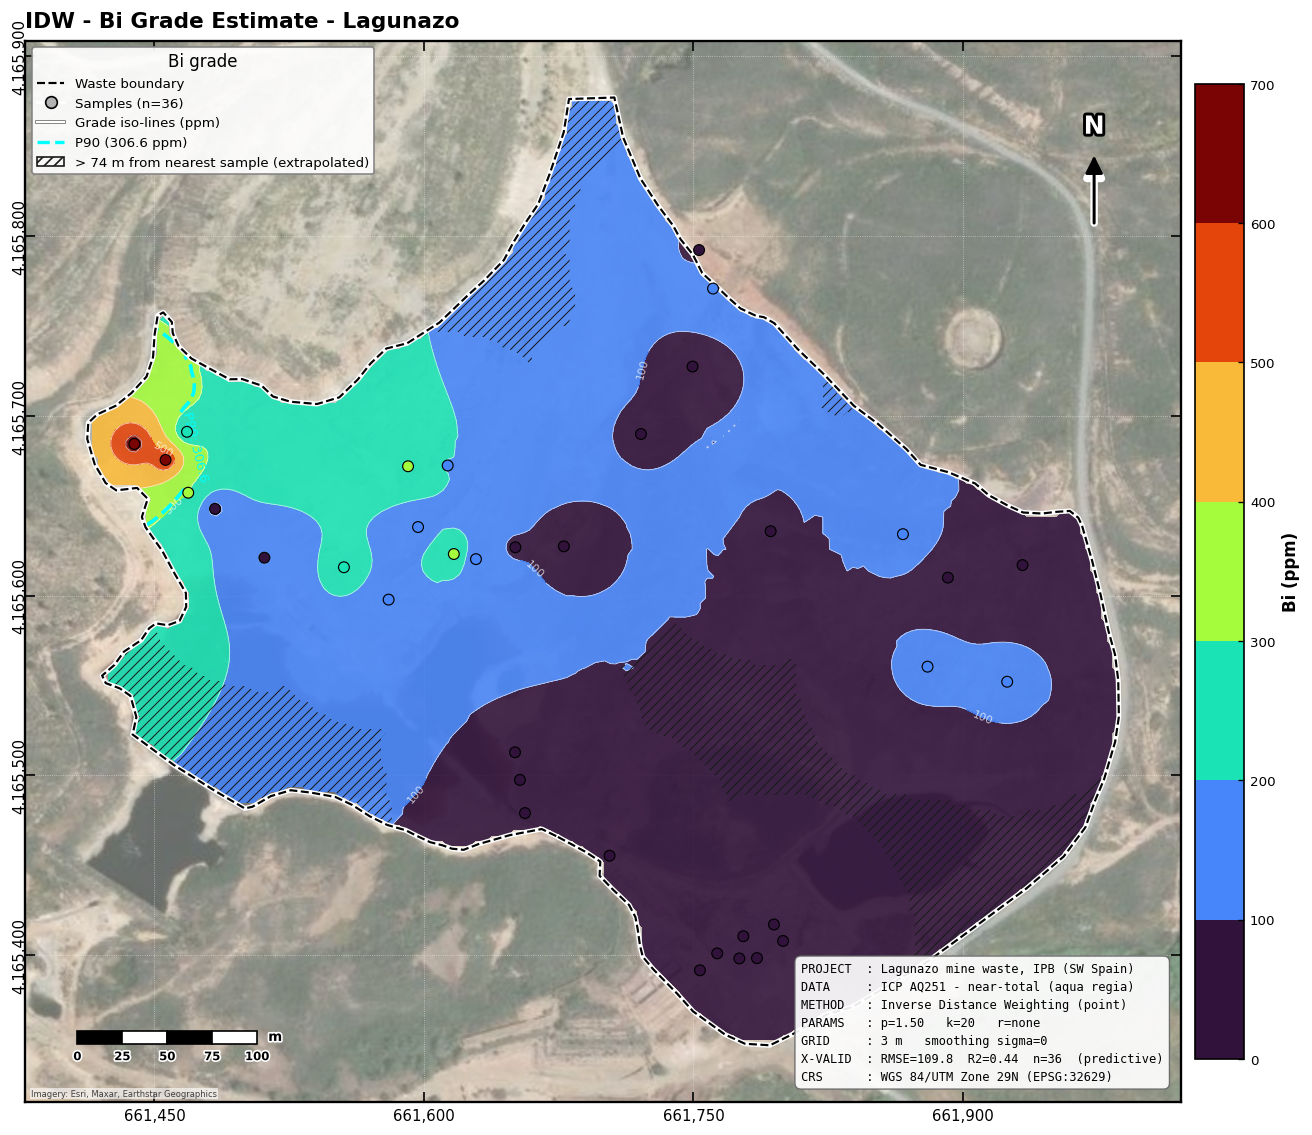

Figure 1 saved -> IDW_Bi_grade_map_UTM29N.png / .pdf (400 dpi + vector)


In [17]:
def fmt_tick(v, _=None):
    return fmt_num(v)

def draw_grade_surface(ax, Z, breaks, cmap, norm, svals, sx, sy, p90=None, extrap=None,
                       iso=True, fs=1.0, dot=42):
    """Basemap + classified IDW surface + iso-lines + P90 + extrapolation hatching + stations + furniture."""
    add_satellite_basemap(ax)
    # Round to 10 significant digits for display only: stations with tied values (e.g. many at 0.001 %) give IDW
    # estimates equal to a class break up to floating-point noise, which otherwise speckles across the break.
    Z = np.asarray(Z, float)
    zmax = np.nanmax(np.abs(Z)) if np.isfinite(Z).any() else 1.0
    Z = np.round(Z, int(10 - np.floor(np.log10(max(zmax, 1e-300)))))
    Zm = np.ma.masked_invalid(Z)
    cf = ax.contourf(XG, YG, Zm, levels=breaks, cmap=cmap, norm=norm, alpha=0.88, zorder=2, extend="both")
    arts = [cf]
    if iso:
        cl = ax.contour(XG, YG, Zm, levels=breaks[1:-1] if len(breaks) > 2 else breaks, colors="white", linewidths=0.5, alpha=0.7, zorder=3)
        ax.clabel(cl, levels=cl.levels[::2], inline=True, fontsize=6.5 * fs, fmt=fmt_num)
        arts.append(cl)
    if p90 is not None and np.nanmin(Z) < p90 < np.nanmax(Z):
        c90 = ax.contour(XG, YG, Zm, levels=[p90], colors="cyan", linewidths=2.2 * fs, linestyles="--", zorder=5)
        ax.clabel(c90, inline=True, fontsize=8 * fs, fmt=lambda v: f"P90: {fmt_num(v)}")
        arts.append(c90)
    if HATCH_EXTRAP and extrap is not None and np.nanmax(extrap) > 0:
        with plt.rc_context({"hatch.color": "0.1", "hatch.linewidth": 0.6}):
            hf = ax.contourf(XG, YG, np.ma.masked_invalid(extrap), levels=[0.5, 1.5], colors="none",
                             hatches=["////"], zorder=6)
        arts.append(hf)
    clip_to_boundary(ax, *arts)
    ax.scatter(sx, sy, s=dot, c=svals, cmap=cmap, norm=norm, edgecolors="black", linewidths=0.7, zorder=11)
    add_map_furniture(ax, fs=fs)
    return cf


def grade_colorbar(fig, ax, breaks, cmap, norm, label, scheme=None, fmt=None, **kw):
    scheme = CLASS_SCHEME if scheme is None else scheme
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, boundaries=breaks, ticks=breaks,
                      spacing="uniform" if scheme == "quantile" else "proportional",
                      format=fmt or mticker.FuncFormatter(fmt_tick), **kw)
    cb.set_label(label, fontsize=10, fontweight="bold")
    cb.ax.tick_params(labelsize=8)
    return cb


def rtxt(r):
    return f"{r:.0f} m" if np.isfinite(r) else "none"


def no_skill_stamp(ax, m, fs=1.0):
    """Reliability label on every map whose LOOCV R2 is below MIN_R2_SURFACE."""
    r2 = m.get("R2_pred", 1)
    rel = reliability_class(r2)
    if rel == "predictive":
        return
    txt = (f"WEAK: LOOCV R2 = {r2:.2f} (< {MIN_R2_SURFACE:g})\nthe surface explains little of the held-out variance"
           if rel == "weak" else
           f"NO SKILL: LOOCV R2 = {r2:.2f}\ndescriptive smoothing of the samples, not a predictive model")
    ax.text(0.62, 0.965, txt, transform=ax.transAxes, ha="center", va="top", fontsize=8.5 * fs, fontweight="bold",
            color=RELIABILITY_COLOUR[rel], zorder=25,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=RELIABILITY_COLOUR[rel], alpha=0.9))


def plot_grade_map(el, unit, Z, EX, ex_d, breaks, svals, sx, sy, prm, m, out_stem, title=None, scheme=None,
                   cb_fmt=None, extra_lines=(), mdl=None):
    """Full r8-style Figure 1 for one element (grey lowest class when it is '<MDL')."""
    cmap = crm_cmap(breaks, mdl)
    norm = BoundaryNorm(breaks, cmap.N)
    p90 = float(np.nanpercentile(svals, 90))
    fig, ax = plt.subplots(figsize=(11, 9.6))
    draw_grade_surface(ax, Z, breaks, cmap, norm, svals, sx, sy, p90=p90, extrap=EX)
    scheme = CLASS_SCHEME if scheme is None else scheme
    grade_colorbar(fig, ax, breaks, cmap, norm, f"{el} ({unit})" + ("  [percentile classes]" if scheme == "quantile"
                   else "") + ("  [lowest class = below MDL]" if cb_fmt is not None else ""), scheme=scheme,
                   fmt=cb_fmt, fraction=0.040, pad=0.012)
    flag = " †" if is_partial(el) else ""
    ax.set_title(title or f"IDW - {el}{flag} Grade Estimate - Lagunazo",
                 fontsize=13, fontweight="bold", loc="left", pad=8)
    info_block(ax, [
        "PROJECT  : Lagunazo mine waste, IPB (SW Spain)",
        f"DATA     : ICP {META.loc[el, 'method']} - {digestion_class(el).replace(' †', '')}",
        f"METHOD   : Inverse Distance Weighting (point){', log' if TRANSFORM == 'log' else ''}",
        f"PARAMS   : p={prm['p']:.2f}   k={prm['k']}   r={rtxt(prm['r'])}"
        + (f"   min k={prm['mink']}" if np.isfinite(prm["r"]) else ""),
        f"GRID     : {GRID_DENSITY_M:g} m   smoothing sigma={SMOOTH_SIGMA:g}",
        f"X-VALID  : RMSE={fmt_num(m['RMSE'])}  R2={m['R2_pred']:.2f}  n={m['n']}  ({reliability_class(m['R2_pred'])})",
        "CRS      : WGS 84/UTM Zone 29N (EPSG:32629)"] + [l for l in extra_lines if l])
    handles = [
        Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
        Line2D([0], [0], marker="o", color="w", mfc="0.7", mec="black", ms=7, label=f"Samples (n={len(svals)})"),
        Line2D([0], [0], color="white", lw=1.2, label=f"Grade iso-lines ({unit})",
               path_effects=[mpe.withStroke(linewidth=2.2, foreground="0.45")]),
        Line2D([0], [0], color="cyan", lw=2.0, ls="--", label=f"P90 ({fmt_num(p90)} {unit})")]
    if HATCH_EXTRAP and EX is not None and np.nanmax(EX) > 0:
        handles.append(Patch(fc="none", ec="0.1", hatch="////",
                             label=f"> {ex_d:.0f} m from nearest sample (extrapolated)"))
    ax.legend(handles=handles, loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5",
              title=f"{el} grade")
    no_skill_stamp(ax, m)
    plt.tight_layout()
    plt.savefig(f"{out_stem}.png", dpi=400, bbox_inches="tight")
    return fig

def draw_posted_values(ax, breaks, cmap, norm, svals, sx, sy, fs=1.0, dot=60):
    """Classed sample symbols (colour and size by class) on the basemap - used where IDW has no LOOCV skill."""
    add_satellite_basemap(ax)
    ax.fill(px_utm, py_utm, fc="white", ec="none", alpha=0.18, zorder=1)
    svals = np.asarray(svals, float)
    cls = np.clip(np.digitize(svals, breaks[1:-1]), 0, len(breaks) - 2)
    order = np.argsort(svals)
    ax.scatter(np.asarray(sx)[order], np.asarray(sy)[order], s=dot * (0.55 + 0.3 * cls[order]),
               c=svals[order], cmap=cmap, norm=norm, edgecolors="black", linewidths=0.8, zorder=11)
    add_map_furniture(ax, fs=fs)


def plot_posted_map(el, unit, breaks, svals, sx, sy, m, out_stem):
    """r8-layout map of classed sample values for an element without LOOCV skill."""
    cmap = plt.get_cmap(GRADE_CMAP, len(breaks) - 1)
    norm = BoundaryNorm(breaks, cmap.N)
    fig, ax = plt.subplots(figsize=(11, 9.6))
    draw_posted_values(ax, breaks, cmap, norm, svals, sx, sy, dot=90)
    grade_colorbar(fig, ax, breaks, cmap, norm, f"{el} ({unit})  [percentile classes]",
                   scheme=ATLAS_CLASS_SCHEME, fraction=0.040, pad=0.012)
    flag = " †" if is_partial(el) else ""
    ax.set_title(f"{el}{flag} sample values - Lagunazo - not interpolated",
                 fontsize=13, fontweight="bold", loc="left", pad=8)
    info_block(ax, [
        "PROJECT  : Lagunazo mine waste, IPB (SW Spain)",
        f"DATA     : ICP {META.loc[el, 'method']} - {digestion_class(el).replace(' †', '')}",
        "METHOD   : posted values, symbol size and colour by class",
        f"REASON   : IDW LOOCV R2 = {m['R2_pred']:.2f} (< {MIN_R2_SURFACE:g}; no spatial predictability)",
        "CRS      : WGS 84/UTM Zone 29N (EPSG:32629)"])
    ax.legend(handles=[
        Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
        Line2D([0], [0], marker="o", color="w", mfc="0.7", mec="black", ms=8, label=f"Samples (n={len(svals)})")],
        loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5", title=f"{el} values")
    plt.tight_layout()
    plt.savefig(f"{out_stem}.png", dpi=400, bbox_inches="tight")
    return fig


PRM = dict(p=BEST_P, k=BEST_K, r=BEST_RAD, mink=BEST_MINK)
fig = plot_grade_map(VAR_NAME, UNIT, Z_disp, EX_grid, EXTRAP_D, grade_breaks, vals_s, xs_utm, ys_utm, PRM, cv_metrics,
                     f"IDW_{VAR_NAME}_grade_map_UTM29N")
plt.savefig(f"IDW_{VAR_NAME}_grade_map_UTM29N.pdf", bbox_inches="tight")
plt.show()
print(f"Figure 1 saved -> IDW_{VAR_NAME}_grade_map_UTM29N.png / .pdf (400 dpi + vector)")

## 13 · Figure 2 - Grade and Data Support

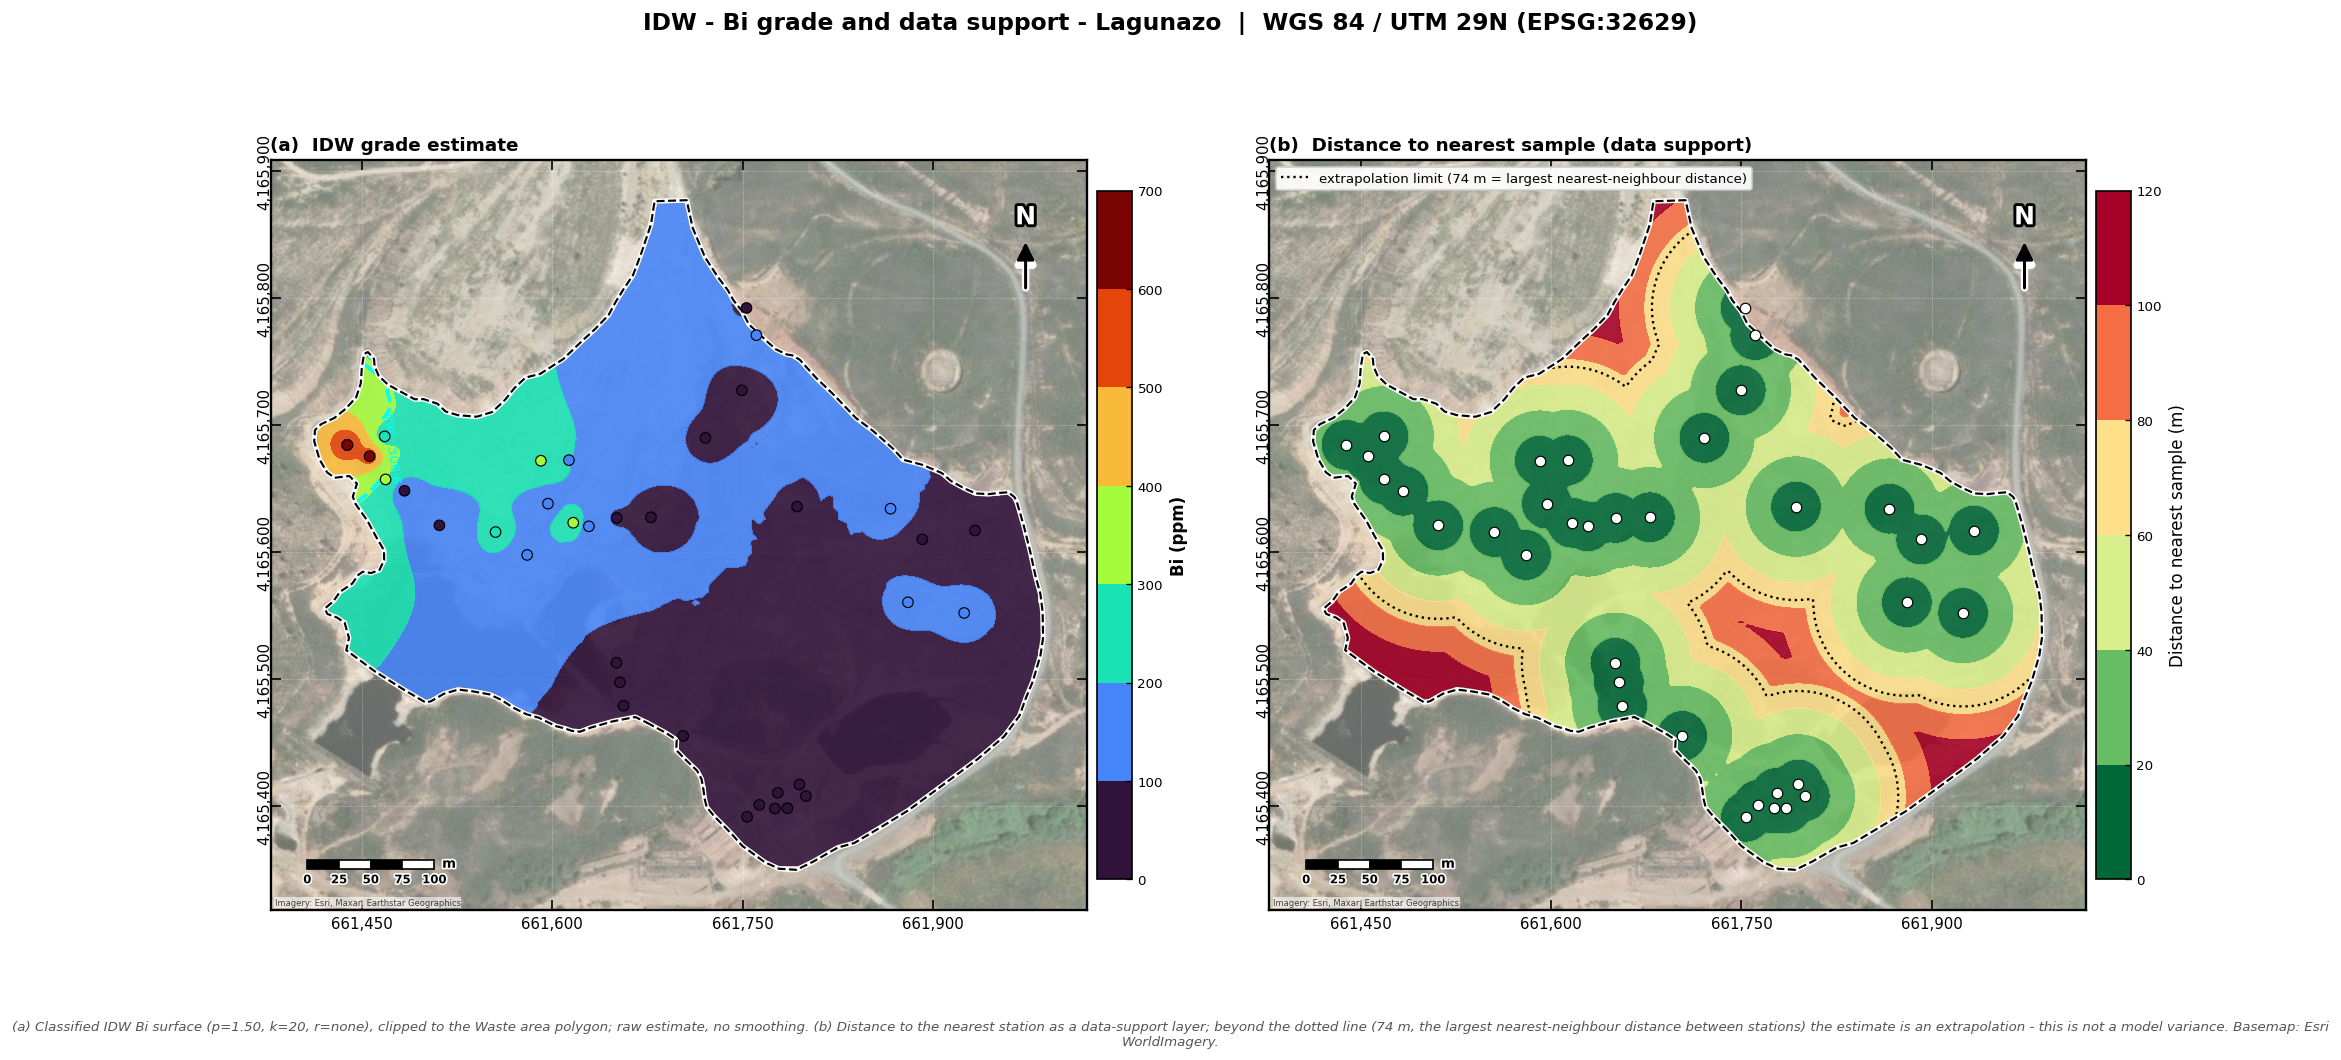

Figure 2 saved -> IDW_Bi_grade_support_UTM29N.png / .pdf


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={"wspace": 0.16})
fig.suptitle(f"IDW - {VAR_NAME} grade and data support - Lagunazo  |  WGS 84 / UTM 29N (EPSG:32629)",
             fontsize=14, fontweight="bold", y=0.98)

ax_a = axes[0]
draw_grade_surface(ax_a, Z_disp, grade_breaks, grade_cmap, grade_norm, vals_s, xs_utm, ys_utm,
                   p90=P90_THR, extrap=None, iso=False, dot=40)
ax_a.set_title("(a)  IDW grade estimate", fontsize=11, fontweight="bold", loc="left")
grade_colorbar(fig, ax_a, grade_breaks, grade_cmap, grade_norm, f"{VAR_NAME} ({UNIT})", fraction=0.040, pad=0.012)

ax_b = axes[1]
add_satellite_basemap(ax_b)
cf_b = ax_b.contourf(XG, YG, np.ma.masked_invalid(D_grid), levels=supp_breaks, cmap=supp_cmap, norm=supp_norm,
                     alpha=0.88, zorder=2, extend="max")
cr_b = ax_b.contour(XG, YG, np.ma.masked_invalid(D_grid), levels=[EXTRAP_D], colors="black",
                    linewidths=1.4, linestyles=":", zorder=5)
clip_to_boundary(ax_b, cf_b, cr_b)
ax_b.scatter(xs_utm, ys_utm, s=40, c="white", edgecolors="black", linewidths=0.7, zorder=11)
add_map_furniture(ax_b)
ax_b.set_title("(b)  Distance to nearest sample (data support)", fontsize=11, fontweight="bold", loc="left")
cb_b = fig.colorbar(plt.cm.ScalarMappable(norm=supp_norm, cmap=supp_cmap), ax=ax_b, fraction=0.040, pad=0.012,
                    boundaries=supp_breaks, ticks=supp_breaks, spacing="proportional")
cb_b.set_label("Distance to nearest sample (m)", fontsize=10); cb_b.ax.tick_params(labelsize=8)
ax_b.legend(handles=[Line2D([0], [0], color="black", lw=1.4, ls=":",
                             label=f"extrapolation limit ({EXTRAP_D:.0f} m = largest nearest-neighbour distance)")],
            loc="upper left", fontsize=8, framealpha=0.92)

fig.text(0.5, 0.02,
    f"(a) Classified IDW {VAR_NAME} surface (p={BEST_P:.2f}, k={BEST_K}, r={RAD_TXT}), clipped to the "
    f"{BND_LABEL}; raw estimate, no smoothing. (b) Distance to the nearest station as a data-support layer; beyond "
    f"the dotted line ({EXTRAP_D:.0f} m, the largest nearest-neighbour distance between stations) the estimate is an "
    f"extrapolation - this is not a model variance. Basemap: Esri WorldImagery.",
    ha="center", fontsize=8, color="#555", style="italic", va="bottom", wrap=True)
plt.savefig(f"IDW_{VAR_NAME}_grade_support_UTM29N.png", dpi=400, bbox_inches="tight")
plt.savefig(f"IDW_{VAR_NAME}_grade_support_UTM29N.pdf", bbox_inches="tight")
plt.show()
print(f"Figure 2 saved -> IDW_{VAR_NAME}_grade_support_UTM29N.png / .pdf")

## 14 · Figure 3 - Cross-Validation Performance Dashboard

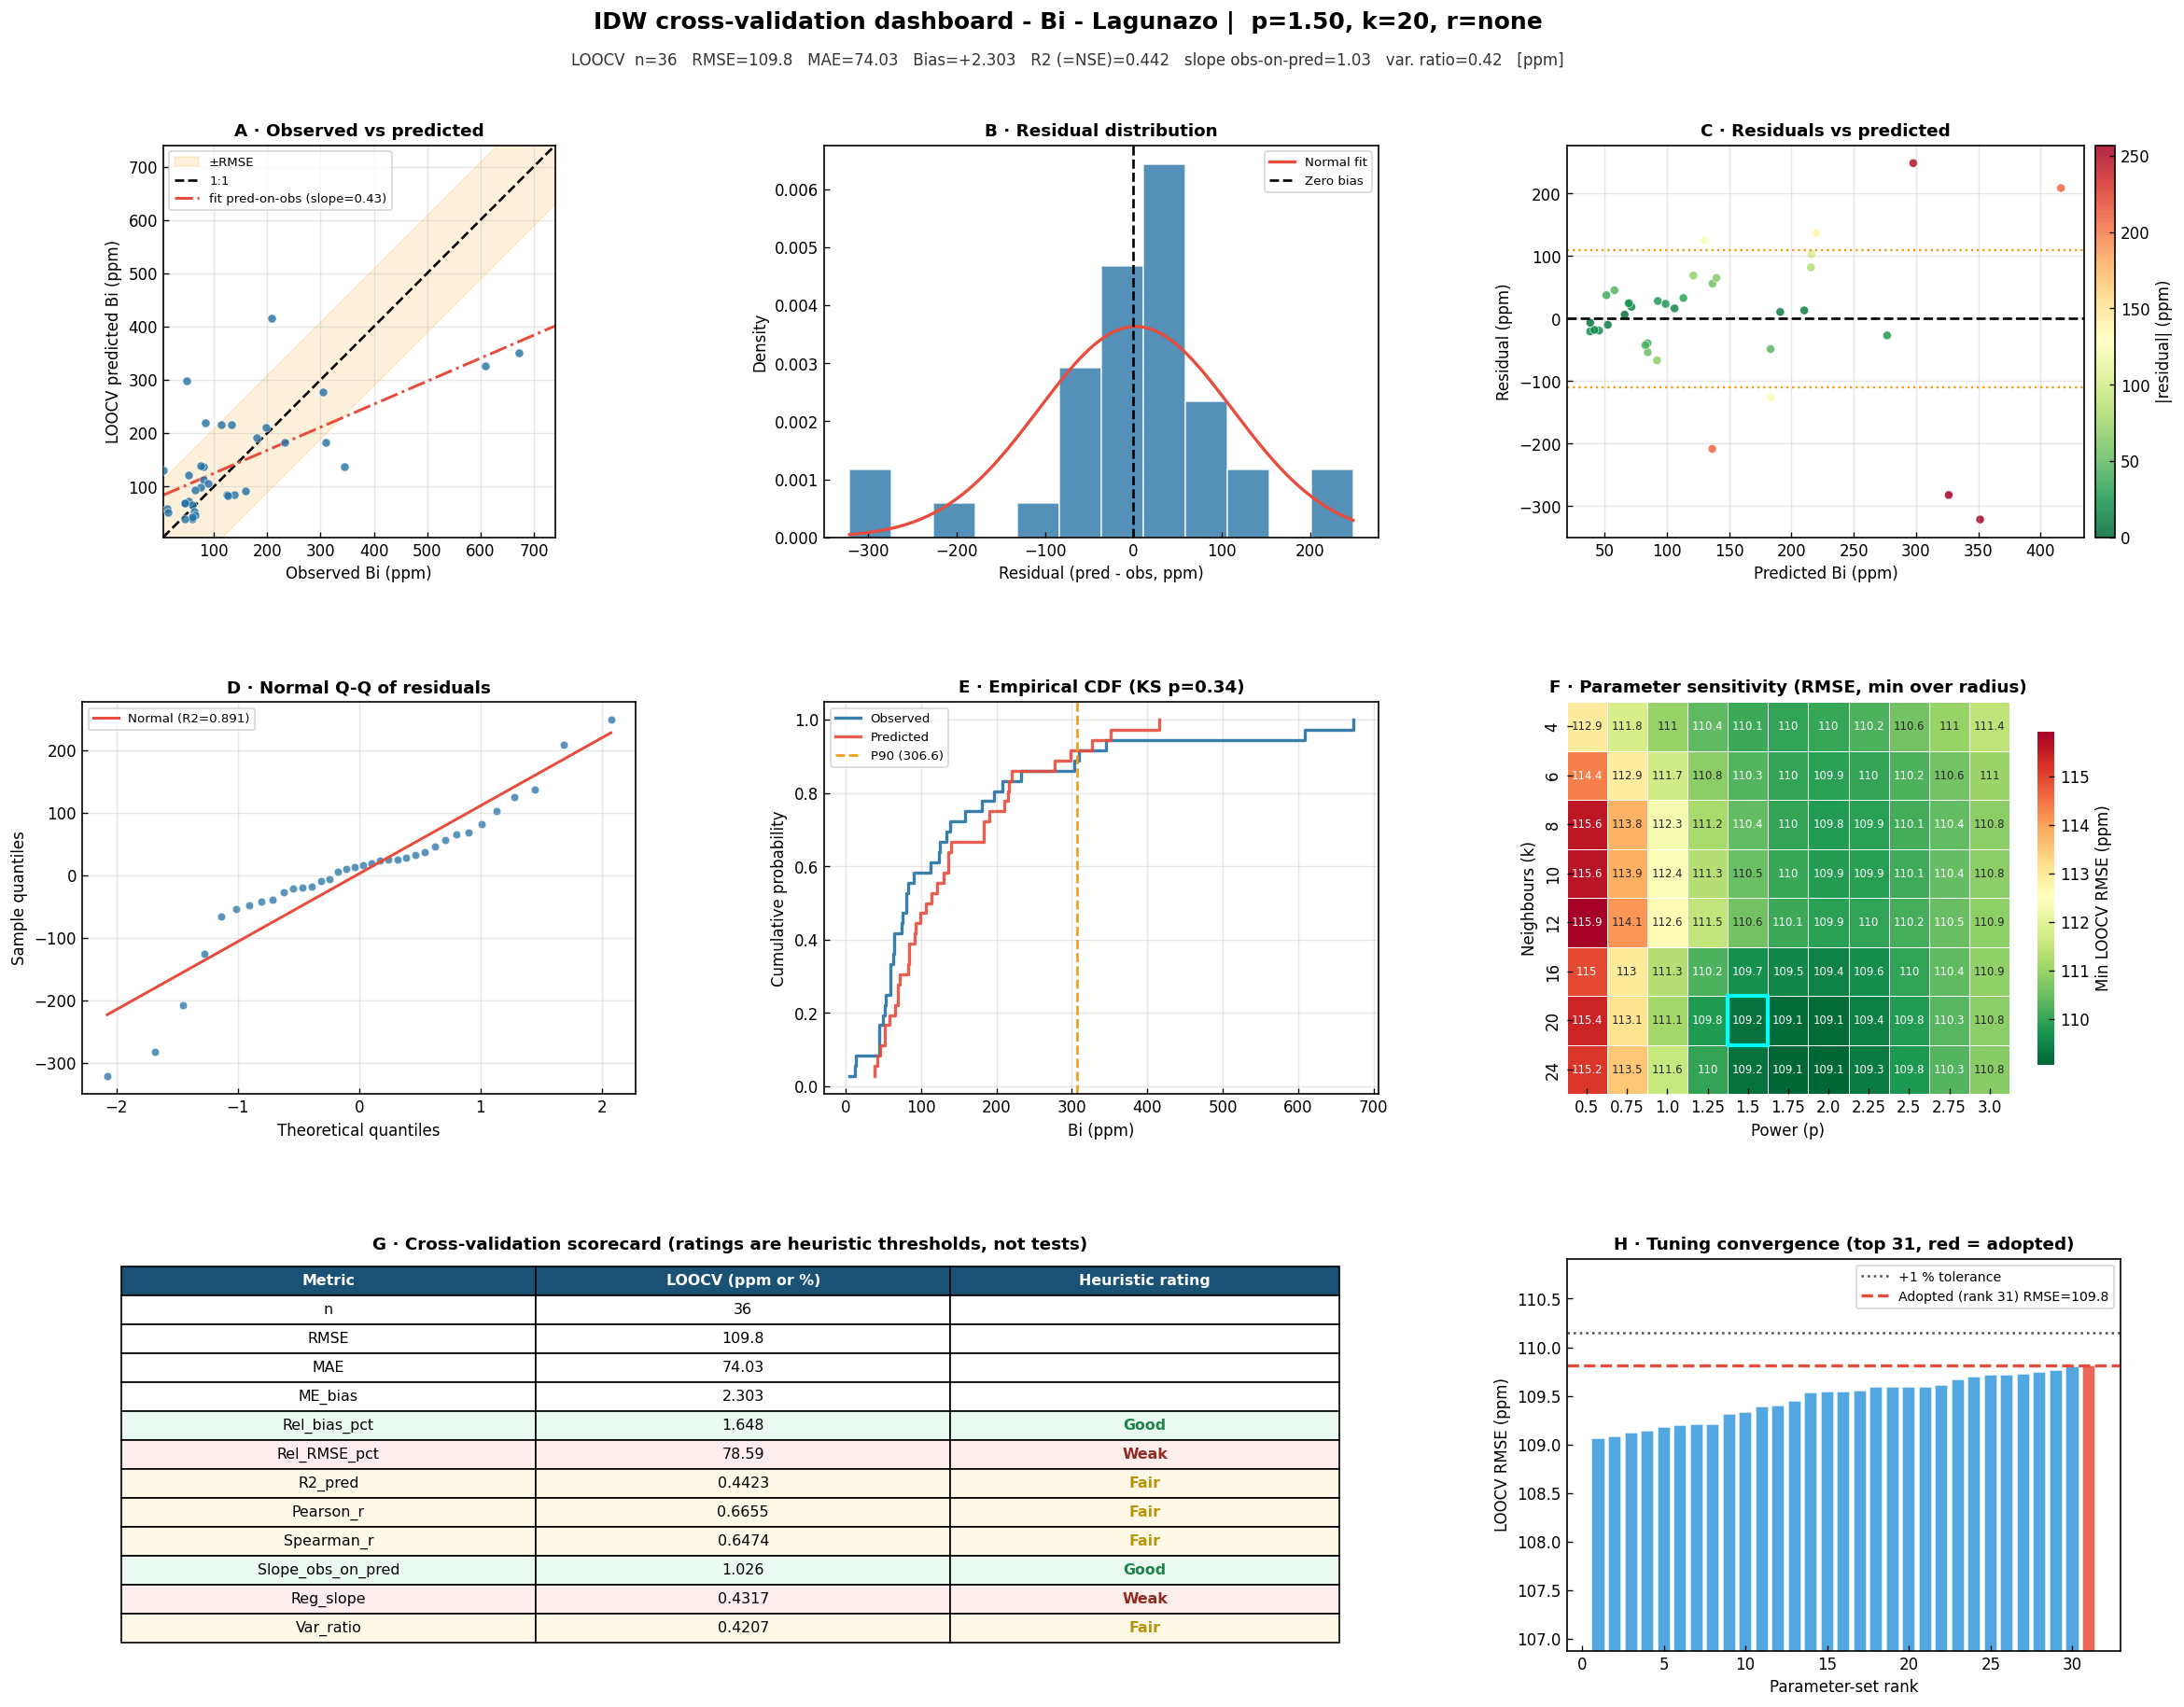

Figure 3 saved -> IDW_Bi_performance_dashboard.png


In [19]:
obs  = cv_df[VAR_NAME].to_numpy(float)
pred = cv_df["Predicted_LOOCV"].to_numpy(float)
ok   = np.isfinite(obs) & np.isfinite(pred)
obs, pred = obs[ok], pred[ok]
resid = pred - obs
rmse_v = cv_metrics["RMSE"]

fig = plt.figure(figsize=(20, 16))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.34, left=0.06, right=0.97, top=0.90, bottom=0.06)
fig.suptitle(f"IDW cross-validation dashboard - {VAR_NAME} - Lagunazo |  p={BEST_P:.2f}, k={BEST_K}, "
             f"r={RAD_TXT}", fontsize=15, fontweight="bold", y=0.975)
fig.text(0.5, 0.945,
    f"LOOCV  n={cv_metrics['n']}   RMSE={fmt_num(cv_metrics['RMSE'])}   MAE={fmt_num(cv_metrics['MAE'])}   "
    f"Bias={cv_metrics['ME_bias']:+.4g}   R2 (=NSE)={cv_metrics['R2_pred']:.3f}   "
    f"slope obs-on-pred={cv_metrics['Slope_obs_on_pred']:.2f}   var. ratio={cv_metrics['Var_ratio']:.2f}   [{UNIT}]",
    ha="center", fontsize=10, color="#333")
DOT, HL = "#2471a3", "#e74c3c"

axA = fig.add_subplot(gs[0, 0])
lim = [min(obs.min(), pred.min()) * 0.9, max(obs.max(), pred.max()) * 1.1]
axA.fill_between(lim, [v - rmse_v for v in lim], [v + rmse_v for v in lim], color="#f39c12", alpha=0.15,
                 zorder=1, label="±RMSE")
axA.scatter(obs, pred, s=30, alpha=0.8, color=DOT, edgecolors="white", lw=0.4, zorder=3)
axA.plot(lim, lim, "k--", lw=1.6, zorder=2, label="1:1")
if np.std(obs) > 0 and np.std(pred) > 0:
    m_r, c_r = stats.linregress(obs, pred)[:2]
    xx = np.linspace(lim[0], lim[1], 100)
    axA.plot(xx, m_r * xx + c_r, color=HL, lw=1.8, ls="-.", label=f"fit pred-on-obs (slope={m_r:.2f})")
axA.set_xlim(lim); axA.set_ylim(lim); axA.set_aspect("equal", adjustable="box")
axA.set_xlabel(f"Observed {VAR_NAME} ({UNIT})"); axA.set_ylabel(f"LOOCV predicted {VAR_NAME} ({UNIT})")
axA.set_title("A · Observed vs predicted", fontweight="bold"); axA.legend(fontsize=8, loc="upper left")
axA.grid(alpha=0.3)

axB = fig.add_subplot(gs[0, 1])
axB.hist(resid, bins=min(25, max(8, N_SAMPLES // 3)), color=DOT, edgecolor="white", alpha=0.78, density=True)
mu_r, s_r = stats.norm.fit(resid)
xr = np.linspace(resid.min(), resid.max(), 200)
axB.plot(xr, stats.norm.pdf(xr, mu_r, s_r), color=HL, lw=2.0, label="Normal fit")
axB.axvline(0, color="black", ls="--", lw=1.6, label="Zero bias")
axB.set_xlabel(f"Residual (pred - obs, {UNIT})"); axB.set_ylabel("Density")
axB.set_title("B · Residual distribution", fontweight="bold"); axB.legend(fontsize=8)

axC = fig.add_subplot(gs[0, 2])
scC = axC.scatter(pred, resid, s=30, c=np.abs(resid), cmap="RdYlGn_r", vmin=0,
                  vmax=np.percentile(np.abs(resid), 95), alpha=0.85, edgecolors="white", lw=0.4)
axC.axhline(0, color="black", ls="--", lw=1.6)
axC.axhline(rmse_v, color="#f39c12", ls=":", lw=1.4); axC.axhline(-rmse_v, color="#f39c12", ls=":", lw=1.4)
fig.colorbar(scC, ax=axC, fraction=0.045, pad=0.02, label=f"|residual| ({UNIT})")
axC.set_xlabel(f"Predicted {VAR_NAME} ({UNIT})"); axC.set_ylabel(f"Residual ({UNIT})")
axC.set_title("C · Residuals vs predicted", fontweight="bold"); axC.grid(alpha=0.3)

axD = fig.add_subplot(gs[1, 0])
(osm, osr), (sl, ic, rqq) = stats.probplot(resid, dist="norm")
axD.scatter(osm, osr, s=26, color=DOT, alpha=0.75, edgecolors="white", lw=0.4)
axD.plot(osm, sl * np.array(osm) + ic, color=HL, lw=1.8, label=f"Normal (R2={rqq ** 2:.3f})")
axD.set_xlabel("Theoretical quantiles"); axD.set_ylabel("Sample quantiles")
axD.set_title("D · Normal Q-Q of residuals", fontweight="bold"); axD.legend(fontsize=8); axD.grid(alpha=0.3)

axE = fig.add_subplot(gs[1, 1])
for arr, lab, col in [(obs, "Observed", DOT), (pred, "Predicted", HL)]:
    s = np.sort(arr); pp = np.arange(1, len(s) + 1) / len(s)
    axE.step(s, pp, where="post", color=col, lw=2.0, label=lab, alpha=0.9)
axE.axvline(P90_THR, color="#f39c12", ls="--", lw=1.6, label=f"P90 ({fmt_num(P90_THR)})")
ks, ksp = stats.ks_2samp(obs, pred)
axE.set_xlabel(f"{VAR_NAME} ({UNIT})"); axE.set_ylabel("Cumulative probability")
axE.set_title(f"E · Empirical CDF (KS p={ksp:.2f})", fontweight="bold"); axE.legend(fontsize=8); axE.grid(alpha=0.3)

axF = fig.add_subplot(gs[1, 2])
piv = (tuning_df.groupby(["p", "k_neighbors"])["RMSE"].min().reset_index()
                .pivot(index="k_neighbors", columns="p", values="RMSE"))
if SNS_OK:
    sns.heatmap(piv, annot=True, fmt=".4g", cmap="RdYlGn_r", ax=axF, annot_kws={"size": 7},
                linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.85, "label": f"Min LOOCV RMSE ({UNIT})"})
else:
    imF = axF.imshow(piv.values, aspect="auto", cmap="RdYlGn_r", origin="upper")
    axF.set_xticks(range(len(piv.columns)), [f"{v:.2f}" for v in piv.columns], rotation=45)
    axF.set_yticks(range(len(piv.index)), [str(v) for v in piv.index])
    fig.colorbar(imF, ax=axF, shrink=0.85, label=f"Min LOOCV RMSE ({UNIT})")
bp = list(piv.columns).index(BEST_P); bk = list(piv.index).index(BEST_K)
axF.add_patch(Rectangle((bp, bk), 1, 1, fill=False, edgecolor="cyan", lw=2.5, zorder=5))
axF.set_xlabel("Power (p)"); axF.set_ylabel("Neighbours (k)")
axF.set_title("F · Parameter sensitivity (RMSE, min over radius)", fontweight="bold")

axG = fig.add_subplot(gs[2, 0:2]); axG.axis("off")
show_keys = ["n", "RMSE", "MAE", "ME_bias", "Rel_bias_pct", "Rel_RMSE_pct", "R2_pred",
             "Pearson_r", "Spearman_r", "Slope_obs_on_pred", "Reg_slope", "Var_ratio"]
bands = {"Rel_bias_pct": (5, 15, "near0"), "Rel_RMSE_pct": (25, 50, "low"), "R2_pred": (0.6, 0.3, "high"),
         "Pearson_r": (0.8, 0.5, "high"), "Spearman_r": (0.8, 0.5, "high"), "Reg_slope": (0.8, 0.5, "high"),
         "Var_ratio": (0.7, 0.4, "high"), "Slope_obs_on_pred": (0.1, 0.25, "near1")}
def _assess(k, v):
    if k not in bands or not np.isfinite(v):
        return ""
    a, b, kind = bands[k]
    if kind == "low":
        return "Good" if v <= a else "Fair" if v <= b else "Weak"
    if kind == "high":
        return "Good" if v >= a else "Fair" if v >= b else "Weak"
    if kind == "near1":
        return "Good" if abs(v - 1) <= a else "Fair" if abs(v - 1) <= b else "Weak"
    return "Good" if abs(v) <= a else "Fair" if abs(v) <= b else "Weak"
rows_g = [[k, f"{cv_metrics[k]:,.4g}" if k != "n" else str(cv_metrics[k]), _assess(k, cv_metrics[k])]
          for k in show_keys]
cols = ["Metric", f"LOOCV ({UNIT} or %)", "Heuristic rating"]
tbl = axG.table(cellText=rows_g, colLabels=cols, cellLoc="center", loc="center", colWidths=[0.32, 0.32, 0.30])
tbl.auto_set_font_size(False); tbl.set_fontsize(9.5); tbl.scale(1.0, 1.55)
for c in range(len(cols)):
    tbl[0, c].set_facecolor("#1A5276"); tbl[0, c].set_text_props(color="white", fontweight="bold")
for r in range(1, len(rows_g) + 1):
    st = rows_g[r - 1][2]
    fc = {"Good": "#eafaf1", "Fair": "#fef9e7", "Weak": "#fdedec"}.get(st, "white")
    for c in range(len(cols)):
        tbl[r, c].set_facecolor(fc)
    if st:
        tbl[r, 2].set_text_props(fontweight="bold",
                                 color={"Good": "#1e8449", "Fair": "#b7950b", "Weak": "#922b21"}[st])
axG.set_title("G · Cross-validation scorecard (ratings are heuristic thresholds, not tests)",
              fontweight="bold", pad=6)

axH = fig.add_subplot(gs[2, 2])
topn = min(max(30, BEST_RANK), len(tuning_df)); vals_h = tuning_df.head(topn)["RMSE"].to_numpy()
axH.bar(range(1, topn + 1), vals_h, color=["#e74c3c" if i + 1 == BEST_RANK else "#3498db" for i in range(topn)],
        edgecolor="white", alpha=0.85)
axH.axhline(tuning_df["RMSE"].min() * (1 + RMSE_TOL_PCT / 100), color="0.3", ls=":", lw=1.5,
            label=f"+{RMSE_TOL_PCT:g} % tolerance")
axH.axhline(cv_metrics["RMSE"], color=HL, ls="--", lw=2,
            label=f"Adopted (rank {BEST_RANK}) RMSE={fmt_num(cv_metrics['RMSE'])}")
axH.set_ylim(vals_h.min() * 0.98, vals_h.max() * 1.01)
axH.set_xlabel("Parameter-set rank"); axH.set_ylabel(f"LOOCV RMSE ({UNIT})")
axH.set_title(f"H · Tuning convergence (top {topn}, red = adopted)", fontweight="bold"); axH.legend(fontsize=8.5)

plt.savefig(f"IDW_{VAR_NAME}_performance_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure 3 saved -> IDW_{VAR_NAME}_performance_dashboard.png")

## 15 · Figure 4 - Spatial Residuals and Estimation Reliability

IDW has no model-based prediction variance. Reliability is therefore shown with two empirical layers: (b) the
magnitude of the LOOCV error interpolated between stations, in grade units (the r8 relative-error surface capped at
50 % saturated for skewed elements), and (d) the status of the search neighbourhood at each node.

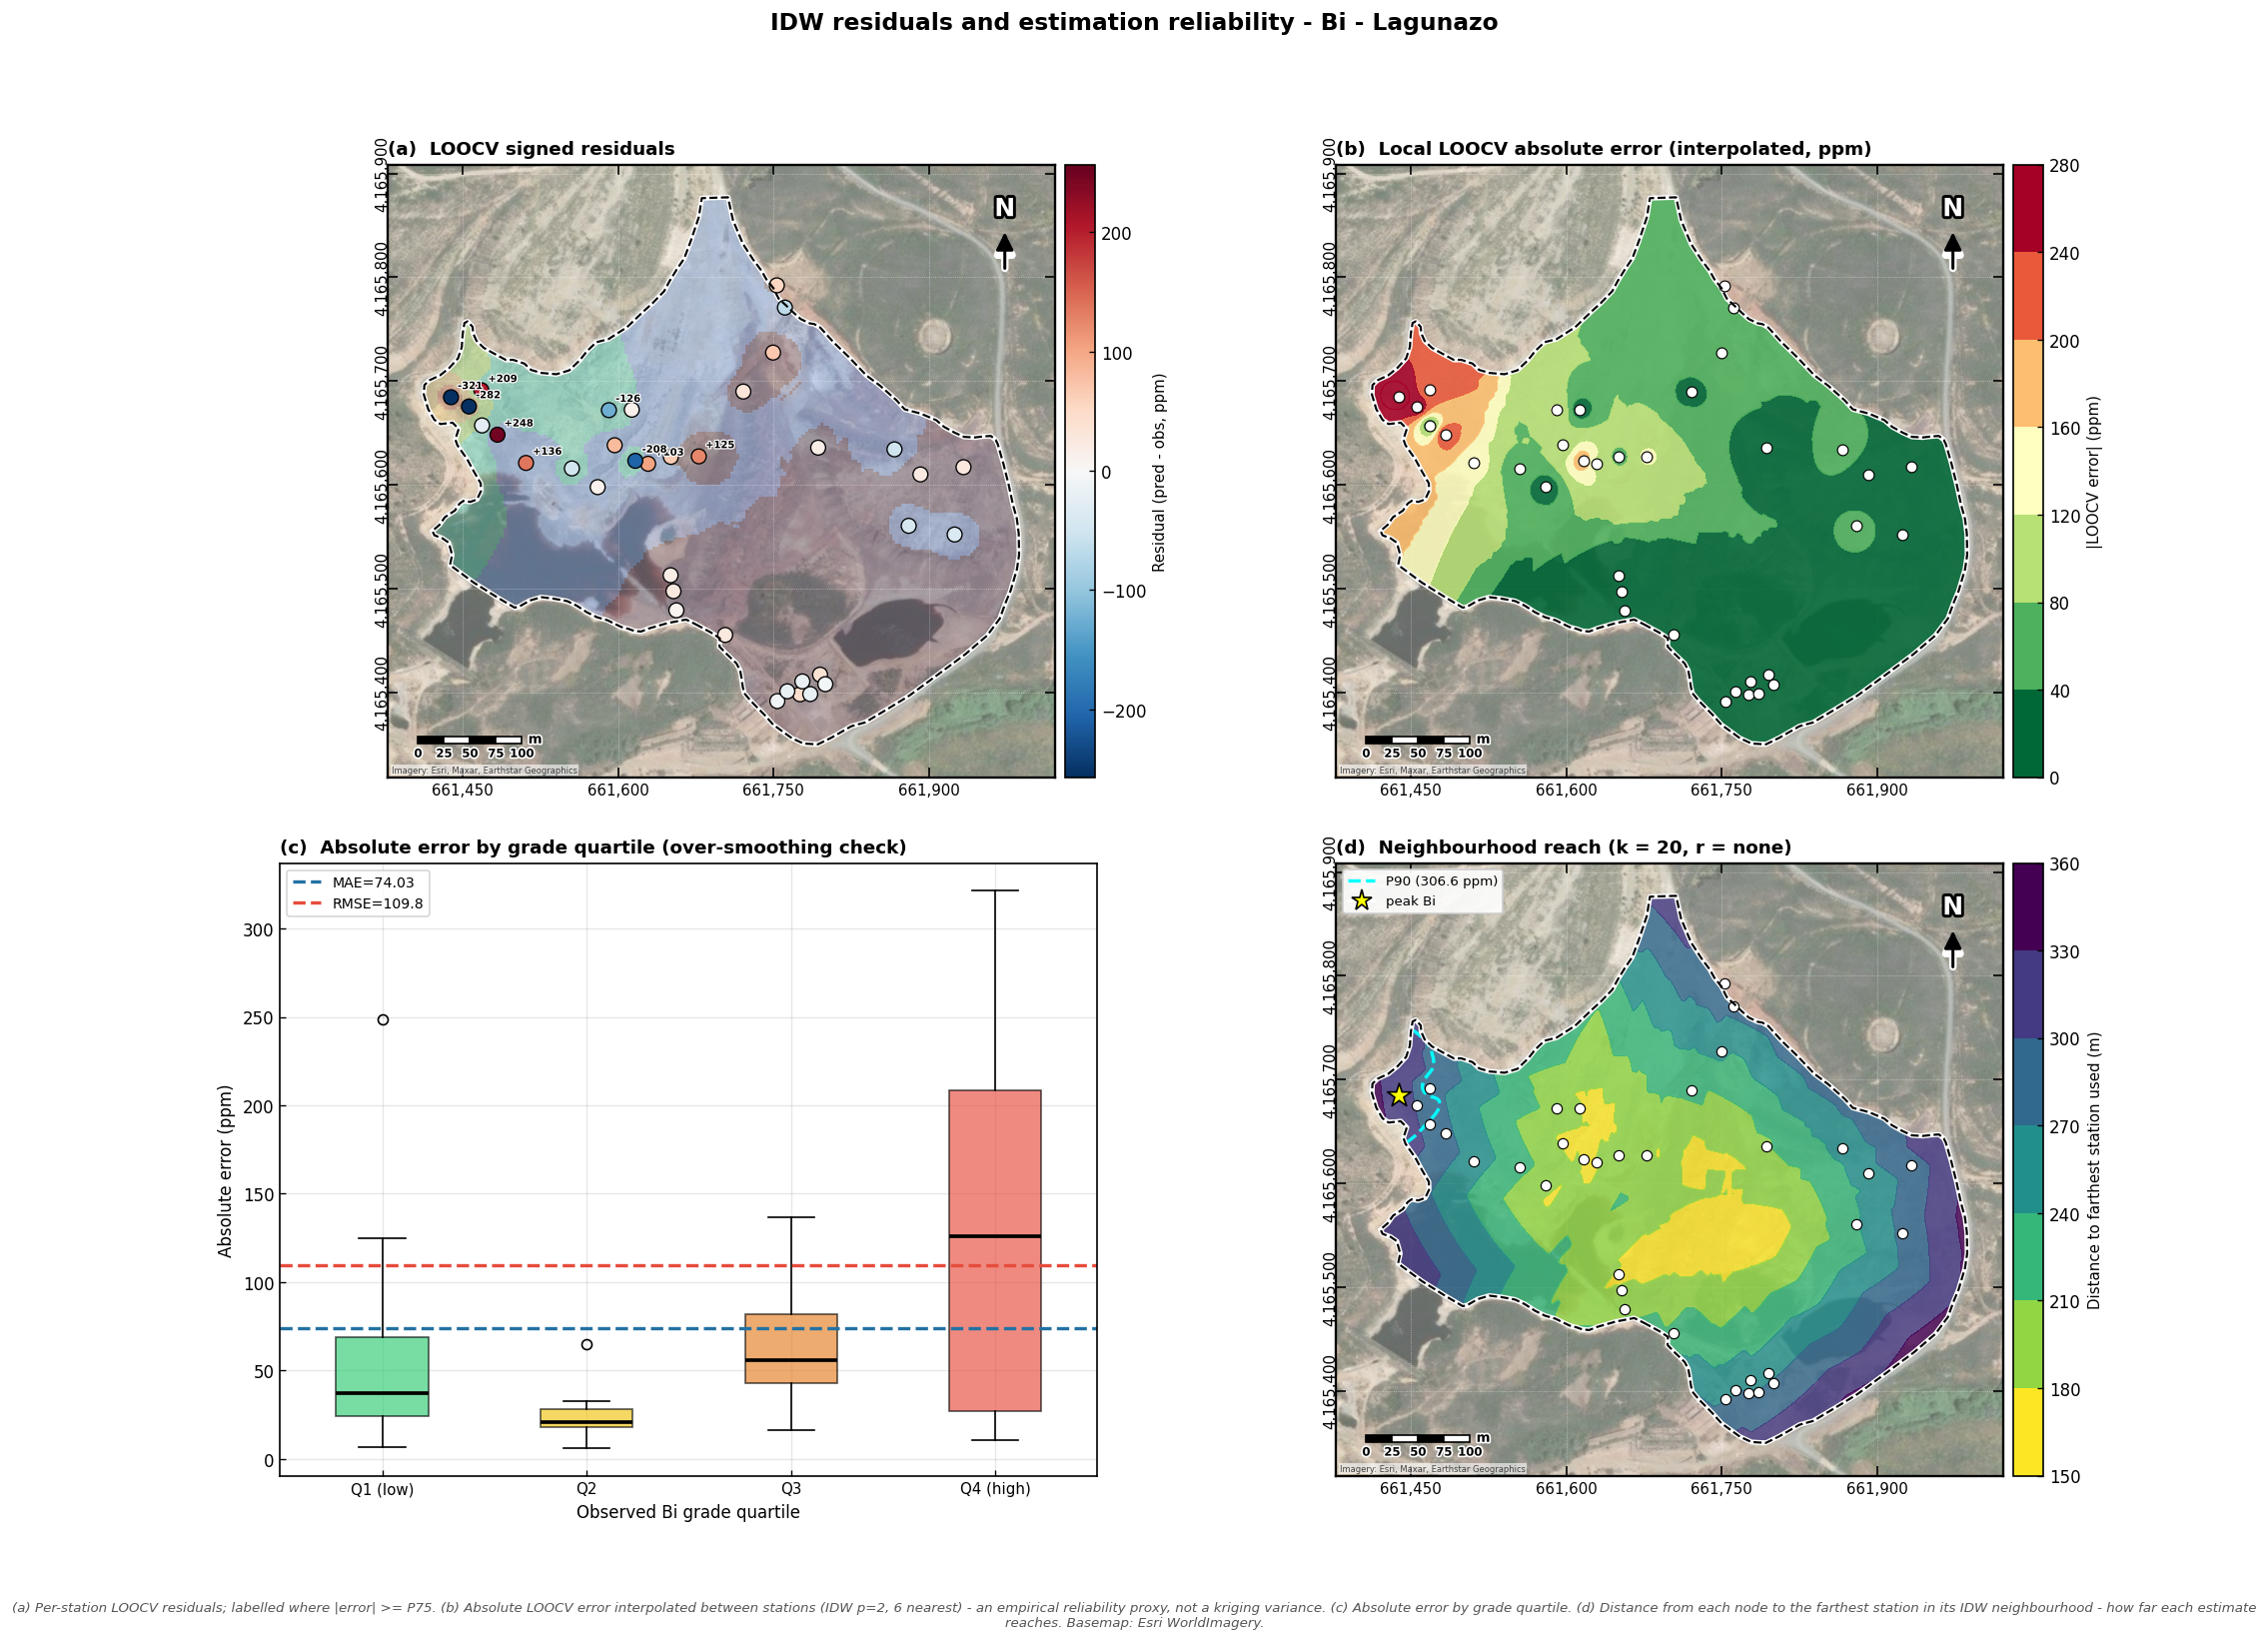

Figure 4 saved -> IDW_Bi_residuals_reliability.png / .pdf


In [20]:
xs_cv, ys_cv = cv_df["X_utm"].to_numpy(float), cv_df["Y_utm"].to_numpy(float)
res_cv = cv_df["Residual"].to_numpy(float)
abs_cv = cv_df["Abs_Error"].to_numpy(float)
obs_cv = cv_df[VAR_NAME].to_numpy(float)

# Local |LOOCV error| surface: plain IDW (p = 2, 6 nearest) of the absolute errors, grade units
ae_flat, _, _, _ = idw_grid(grid_pts, coords_utm, abs_cv, 2.0, 6, 1, None, tree=tree)
AE_grid = np.where(in_hull, ae_flat.reshape(NROW, NCOL), np.nan)
ae_breaks = nice_breaks(0.0, float(np.nanpercentile(AE_grid, 99)), 6)
ae_cmap = plt.get_cmap("RdYlGn_r", len(ae_breaks) - 1)
ae_norm = BoundaryNorm(ae_breaks, ae_cmap.N)

fig, axes = plt.subplots(2, 2, figsize=(19, 14.2), gridspec_kw={"hspace": 0.14, "wspace": 0.16})
fig.suptitle(f"IDW residuals and estimation reliability - {VAR_NAME} - Lagunazo",
             fontsize=14, fontweight="bold", y=0.97)

# (a) signed residuals at stations
axa = axes[0, 0]
add_satellite_basemap(axa)
pm = axa.pcolormesh(XG, YG, np.ma.masked_invalid(Z_disp), cmap=grade_cmap, norm=grade_norm, shading="auto",
                    alpha=0.25, zorder=1)
rmax = np.nanpercentile(np.abs(res_cv), 95)
sca = axa.scatter(xs_cv, ys_cv, s=80, c=res_cv, cmap=RESID_CMAP, vmin=-rmax, vmax=rmax,
                  edgecolors="black", linewidths=0.8, zorder=10)
thr = np.nanpercentile(abs_cv, 75)
for x_, y_, r_ in zip(xs_cv, ys_cv, res_cv):
    if abs(r_) >= thr:
        axa.annotate(f"{r_:+.3g}", xy=(x_, y_), xytext=(4, 5), textcoords="offset points", fontsize=6,
                     fontweight="bold", path_effects=[mpe.withStroke(linewidth=1.5, foreground="white")], zorder=12)
add_map_furniture(axa)
axa.set_title("(a)  LOOCV signed residuals", fontsize=11, fontweight="bold", loc="left")
fig.colorbar(sca, ax=axa, fraction=0.040, pad=0.012).set_label(f"Residual (pred - obs, {UNIT})", fontsize=9)

# (b) interpolated absolute LOOCV error
axb = axes[0, 1]
add_satellite_basemap(axb)
mb = axb.contourf(XG, YG, np.ma.masked_invalid(AE_grid), levels=ae_breaks, cmap=ae_cmap, norm=ae_norm,
                  alpha=0.88, zorder=2, extend="max")
clip_to_boundary(axb, mb)
axb.scatter(xs_cv, ys_cv, s=42, c="white", edgecolors="black", linewidths=0.7, zorder=10)
add_map_furniture(axb)
axb.set_title(f"(b)  Local LOOCV absolute error (interpolated, {UNIT})", fontsize=11, fontweight="bold", loc="left")
cbb = fig.colorbar(plt.cm.ScalarMappable(norm=ae_norm, cmap=ae_cmap), ax=axb, fraction=0.040, pad=0.012,
                   boundaries=ae_breaks, ticks=ae_breaks, format=mticker.FuncFormatter(fmt_tick))
cbb.set_label(f"|LOOCV error| ({UNIT})", fontsize=9)

# (c) absolute error by grade quartile
axc = axes[1, 0]
n_q = int(min(4, max(1, pd.Series(obs_cv).nunique())))
q_lab = ["Q1 (low)", "Q2", "Q3", "Q4 (high)"][:n_q] if n_q == 4 else [f"Q{i + 1}" for i in range(n_q)]
q = pd.qcut(pd.Series(obs_cv).rank(method="first"), q=n_q, labels=q_lab)
groups = [abs_cv[np.asarray(q == c_)] for c_ in q.cat.categories]
bpl = axc.boxplot(groups, patch_artist=True, medianprops=dict(color="black", lw=2.2))
for patch, c_ in zip(bpl["boxes"], ["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"]):
    patch.set_facecolor(c_); patch.set_alpha(0.65)
axc.axhline(cv_metrics["MAE"], color="#2471a3", ls="--", lw=2, label=f"MAE={fmt_num(cv_metrics['MAE'])}")
axc.axhline(cv_metrics["RMSE"], color="#e74c3c", ls="--", lw=2, label=f"RMSE={fmt_num(cv_metrics['RMSE'])}")
axc.set_xticks(range(1, n_q + 1)); axc.set_xticklabels(list(q.cat.categories), fontsize=9)
axc.set_xlabel(f"Observed {VAR_NAME} grade quartile"); axc.set_ylabel(f"Absolute error ({UNIT})")
axc.set_title("(c)  Absolute error by grade quartile (over-smoothing check)", fontsize=11, fontweight="bold", loc="left")
axc.legend(fontsize=8.5); axc.grid(alpha=0.3)

# (d) neighbourhood reach: distance to the farthest station used at each node
axd = axes[1, 1]
add_satellite_basemap(axd)
_rv = REACH_grid[np.isfinite(REACH_grid)]
reach_breaks = nice_breaks(float(_rv.min()), float(np.nanpercentile(_rv, 99)), 6)
reach_cmap = plt.get_cmap("viridis_r", len(reach_breaks) - 1)
reach_norm = BoundaryNorm(reach_breaks, reach_cmap.N)
md_ = axd.contourf(XG, YG, np.ma.masked_invalid(REACH_grid), levels=reach_breaks, cmap=reach_cmap,
                   norm=reach_norm, alpha=0.8, zorder=2, extend="max")
arts_d = [md_]
if HAS_RADIUS and np.nanmax(FB_grid) > 0:
    arts_d.append(axd.contour(XG, YG, np.ma.masked_invalid(FB_grid), levels=[0.5], colors="white",
                              linewidths=1.6, zorder=5))
if np.nanmin(Z_disp) < P90_THR < np.nanmax(Z_disp):
    arts_d.append(axd.contour(XG, YG, np.ma.masked_invalid(Z_disp), levels=[P90_THR], colors="cyan",
                              linewidths=2.0, linestyles="--", zorder=5))
clip_to_boundary(axd, *arts_d)
axd.scatter(xs_utm, ys_utm, s=38, c="white", edgecolors="black", linewidths=0.7, zorder=10)
top = int(np.argmax(vals_s))
axd.scatter(xs_utm[top], ys_utm[top], s=220, marker="*", color="yellow", edgecolors="black", lw=1.0, zorder=12)
add_map_furniture(axd)
axd.set_title(f"(d)  Neighbourhood reach (k = {BEST_K}, r = {RAD_TXT})", fontsize=11, fontweight="bold", loc="left")
cbd = fig.colorbar(plt.cm.ScalarMappable(norm=reach_norm, cmap=reach_cmap), ax=axd, fraction=0.040, pad=0.012,
                   boundaries=reach_breaks, ticks=reach_breaks)
cbd.set_label("Distance to farthest station used (m)", fontsize=9)
_hd = [Line2D([0], [0], color="cyan", lw=2, ls="--", label=f"P90 ({fmt_num(P90_THR)} {UNIT})"),
       Line2D([0], [0], marker="*", color="w", mfc="yellow", mec="black", ms=13, label=f"peak {VAR_NAME}")]
if HAS_RADIUS:
    _hd.insert(0, Line2D([0], [0], color="white", lw=1.6, label="local / extended neighbourhood boundary",
                         path_effects=[mpe.withStroke(linewidth=2.6, foreground="0.4")]))
axd.legend(handles=_hd, loc="upper left", fontsize=8, framealpha=0.92)

fig.text(0.5, 0.02,
    f"(a) Per-station LOOCV residuals; labelled where |error| >= P75. (b) Absolute LOOCV error interpolated between "
    f"stations (IDW p=2, 6 nearest) - an empirical reliability proxy, not a kriging variance. (c) Absolute error by "
    f"grade quartile. (d) Distance from each node to the farthest station in its IDW neighbourhood - how far each "
    f"estimate reaches" + (f"; the white line separates local (>= {BEST_MINK} stations within {RAD_TXT}) from "
    f"extended ({BEST_K}-nearest) nodes" if HAS_RADIUS else "") + ". Basemap: Esri WorldImagery.",
    ha="center", fontsize=8, color="#555", style="italic", va="bottom", wrap=True)
plt.savefig(f"IDW_{VAR_NAME}_residuals_reliability.png", dpi=300, bbox_inches="tight")
plt.savefig(f"IDW_{VAR_NAME}_residuals_reliability.pdf", bbox_inches="tight")
plt.show()
print(f"Figure 4 saved -> IDW_{VAR_NAME}_residuals_reliability.png / .pdf")

## 16 · CRM Atlas - IDW of every mappable CRM element

Each element is tuned independently by LOOCV on its own stations, estimated on the same grid and domain, and
mapped with its own station-percentile classes (P0-10-25-50-75-90-95-100, `ATLAS_CLASS_SCHEME`), the
geochemical-atlas convention for skewed data — equal intervals put most of the domain into one class for elements
such as Cu, Co, Mn or Ni.

**A surface for every CRM, with its reliability.** Every mappable CRM is interpolated (`MAP_ALL_SURFACES = True`) and
each map states how well IDW predicted held-out samples (LOOCV R²): **predictive** (R² ≥ 0.10), **weak**
(0 ≤ R² < 0.10) or **no skill** (R² < 0 — the tuning has collapsed towards the global mean and the surface is a
descriptive smoothing of the samples, not a prediction of unsampled ground; at the current spacing, traverses ~22 m
along-line and 60–150 m apart, this is common). **Censored elements** (Li, Sc, Ge, Mg, Nb, B, Pt and a few samples of
others) are mapped with a grey lowest class `<MDL`; the classes above it are built from the detected values only. CRMs with
fewer than five located detections (Be, Pd, Ta) are shown as detection maps after the atlas. Setting
`MAP_ALL_SURFACES = False` restores the previous behaviour (posted values below R² 0.10).
† = aqua regia is a partial digestion for this element (extractable concentration);
‡ = at least one value above the upper reporting limit (set to the limit, so the local maximum is a lower bound).

In [21]:
ATLAS, atlas_rows = {}, []
if RUN_ATLAS:
    t0 = time.time()
    for el in MAPPABLE:
        pe = element_points(el)
        st, _ = station_means(pe, "X_utm", "Y_utm", el, tol_m=STATION_TOL_M, id_col="Sample",
                              flag_col="flag", verbose=False)
        c = st[["X_utm", "Y_utm"]].to_numpy(float)
        v = st[el].to_numpy(float)
        tdf, sp = tune_idw(c, v)
        b, n_eq = select_best(tdf)
        prm = dict(p=float(b["p"]), k=int(b["k_neighbors"]), mink=int(b["min_neighbors"]),
                   r=float(b["search_radius_m"]))
        pr_t, nfb = loocv_idw(c, fwd(v), prm["p"], prm["k"], prm["mink"], prm["r"])
        m = metrics(v, back(pr_t), label=f"LOOCV {el}")
        zt, fbk, _, _ = idw_grid(grid_pts, c, fwd(v), prm["p"], prm["k"], prm["mink"], prm["r"])
        Z = np.where(in_hull, back(zt).reshape(NROW, NCOL), np.nan)
        FB = np.where(in_hull, fbk.reshape(NROW, NCOL).astype(float), np.nan)
        ex_d = extrap_distance(c)
        EX = np.where(in_hull, (cKDTree(c).query(grid_pts, k=1)[0].reshape(NROW, NCOL) > ex_d).astype(float), np.nan)
        w, cs, _ = declustering_weights(c, v)
        dst = declustered_stats(v, w)
        cz = pe["flag"].value_counts()
        _br, _mdl = crm_breaks(el, Z, v, ATLAS_CLASS_SCHEME)
        _rel = reliability_class(m["R2_pred"])
        ATLAS[el] = dict(Z=Z, FB=FB, EX=EX, ex_d=ex_d, x=c[:, 0], y=c[:, 1], v=v, prm=prm, m=m, unit=unit_of(el),
                         breaks=_br, mdl=_mdl, fmt=crm_formatter(_br, _mdl), edge=edge_flags(b, len(v)),
                         n_odl=int(cz.get("odl", 0)), n_bdl=int(cz.get("bdl", 0)), reliability=_rel,
                         surface=bool(MAP_ALL_SURFACES or m["R2_pred"] >= MIN_R2_SURFACE))
        crm_name = CRM_TABLE.loc[CRM_TABLE["Analyte"] == el, "CRMA 2024 raw material"].iloc[0]
        srm = CRM_TABLE.loc[CRM_TABLE["Analyte"] == el, "Strategic (Annex I)"].iloc[0]
        atlas_rows.append({
            "Element": el, "CRMA 2024": crm_name, "Strategic": srm, "Unit": unit_of(el),
            "Digestion": digestion_class(el), "n stations": len(v),
            "n below MDL": int(cz.get("bdl", 0)), "n above UDL": int(cz.get("odl", 0)),
            "Min": v.min(), "Median": float(np.median(v)), "Max": v.max(),
            "Naive mean": dst["naive_mean"], "Declustered mean": dst["declustered_mean"],
            "p": prm["p"], "k": prm["k"], "Radius (m)": round(prm["r"], 1) if np.isfinite(prm["r"]) else "none",
            "LOOCV RMSE": m["RMSE"], "Rel. RMSE %": m["Rel_RMSE_pct"], "LOOCV R2": m["R2_pred"],
            "Slope obs-on-pred": m["Slope_obs_on_pred"], "Var. ratio": m["Var_ratio"],
            "LOOCV extended nbhd": int(b["n_fallback"]), "Extended nbhd % of domain": 100 * float(np.nanmean(FB)),
            "Extrapolated % of domain": 100 * float(np.nanmean(EX)),
            "Sets within tol.": n_eq,
            "Predictive (R2>0)": "yes" if m["R2_pred"] > 0 else "no",
            "Reliability": _rel, "Censored stations": int(np.sum(v < META.loc[el, "mdl"] * (1 - 1e-9))),
            "Map type": ("IDW surface" if ATLAS[el]["surface"] else "posted values (no LOOCV skill)")
                        + (" with '<MDL' class" if _mdl is not None else ""),
            "Edge optimum": "; ".join(ATLAS[el]["edge"])})
    ATLAS_SUMMARY = pd.DataFrame(atlas_rows)
    print(f"Atlas: {len(ATLAS)} CRM elements tuned and interpolated in {time.time() - t0:.1f}s")
    show_table(ATLAS_SUMMARY, precision=3)
    SURF_ELS = [e for e, a in ATLAS.items() if a["surface"]]
    POST_ELS = [e for e, a in ATLAS.items() if not a["surface"]]
    print(f"\nIDW surfaces: {len(SURF_ELS)} of {len(ATLAS)} mappable CRMs"
          + (" (MAP_ALL_SURFACES = True)" if MAP_ALL_SURFACES else f" (LOOCV R2 >= {MIN_R2_SURFACE:g})"))
    for _rel in ("predictive", "weak", "no skill"):
        _e = [e for e, a in ATLAS.items() if a["reliability"] == _rel]
        print(f"  {_rel:10s} ({len(_e):2d}): " + (", ".join(f"{e} ({ATLAS[e]['m']['R2_pred']:+.2f})" for e in _e) or "-"))
    _c = [e for e, a in ATLAS.items() if a["mdl"] is not None]
    print("  with a '<MDL' class: " + (", ".join(f"{e} ({ATLAS[e]['n_bdl']}/{len(ATLAS[e]['v'])})" for e in _c) or "-"))
    if POST_ELS:
        print(f"Posted values only: {', '.join(POST_ELS)}")
else:
    ATLAS_SUMMARY = pd.DataFrame()
    SURF_ELS, POST_ELS = [], []
    print("RUN_ATLAS = False - atlas skipped.")

Atlas: 26 CRM elements tuned and interpolated in 50.6s


Element,CRMA 2024,Strategic,Unit,Digestion,n stations,n below MDL,n above UDL,Min,Median,Max,Naive mean,Declustered mean,p,k,Radius (m),LOOCV RMSE,Rel. RMSE %,LOOCV R2,Slope obs-on-pred,Var. ratio,LOOCV extended nbhd,Extended nbhd % of domain,Extrapolated % of domain,Sets within tol.,Predictive (R2>0),Reliability,Censored stations,Map type,Edge optimum
Al,Aluminium / bauxite,yes,%,partial (aqua regia) †,36,3,0,0.005,0.075,0.650,0.107,0.092,0.50,16,none,0.126,117.951,-0.039,0.339,0.109,0,0.000,16.712,4,no,no skill,3,IDW surface with '<MDL' class,p=0.50 on the edge of P_VALUES
Sb,Antimony,no,ppm,near-total (aqua regia),36,0,2,38.870,336.775,2000.000,532.430,485.075,1.25,20,none,415.304,78.001,0.322,1.019,0.310,0,0.000,16.712,32,yes,predictive,0,IDW surface,
As,Arsenic,no,ppm,near-total (aqua regia),36,0,0,314.700,898.750,6377.000,1361.525,1386.875,0.50,6,none,1115.540,81.933,0.181,0.913,0.228,0,0.000,16.712,6,yes,predictive,0,IDW surface,p=0.50 on the edge of P_VALUES
Ba,Baryte,no,ppm,partial (aqua regia) †,36,0,0,1.800,30.900,191.200,45.608,44.807,0.75,6,none,37.107,81.361,0.355,1.007,0.358,0,0.000,16.712,4,yes,predictive,0,IDW surface,
Bi,Bismuth,yes,ppm,near-total (aqua regia),36,0,0,5.340,80.675,672.680,139.724,128.190,1.50,20,none,109.814,78.594,0.442,1.026,0.421,0,0.000,16.712,108,yes,predictive,0,IDW surface,
B,Boron / borate,yes (metallurgy grade),ppm,partial (aqua regia) †,36,28,0,0.500,0.500,5.000,0.778,0.767,0.75,16,none,0.813,104.532,-0.025,0.336,0.072,0,0.000,16.712,26,no,no skill,28,IDW surface with '<MDL' class,
Co,Cobalt,yes,ppm,near-total (aqua regia),36,0,0,0.200,3.100,32.500,4.636,3.732,0.50,24,none,7.028,151.603,0.005,0.526,0.095,0,0.000,16.712,2,yes,weak,0,IDW surface,p=0.50 on the edge of P_VALUES; k=24 on the edge of K_VALUES
Cu,Copper,yes,ppm,near-total (aqua regia),36,0,0,64.210,239.950,4159.290,511.453,413.487,0.50,24,none,863.738,168.879,0.003,0.517,0.084,0,0.000,16.712,2,yes,weak,0,IDW surface,p=0.50 on the edge of P_VALUES; k=24 on the edge of K_VALUES
Ga,Gallium,yes,ppm,partial (aqua regia) †,36,1,0,0.050,0.550,4.100,0.779,0.759,1.75,20,none,0.600,77.060,0.361,1.006,0.356,0,0.000,16.712,15,yes,predictive,1,IDW surface with '<MDL' class,
Ge,Germanium,yes,ppm,variable (aqua regia),36,19,0,0.050,0.050,0.600,0.137,0.115,0.75,20,none,0.138,100.384,0.171,0.947,0.193,0,0.000,16.712,5,yes,predictive,19,IDW surface with '<MDL' class,



IDW surfaces: 26 of 26 mappable CRMs (MAP_ALL_SURFACES = True)
  predictive ( 9): Sb (+0.32), As (+0.18), Ba (+0.36), Bi (+0.44), Ga (+0.36), Ge (+0.17), Hf (+0.18), P (+0.23), Pt (+0.38)
  weak       ( 6): Co (+0.01), Cu (+0.00), Y (+0.00), Li (+0.03), Mn (+0.02), Ni (+0.04)
  no skill   (11): Al (-0.04), B (-0.02), La (-0.10), Ce (-0.08), Mg (-0.01), Nb (-0.09), Sc (-0.02), Sr (-0.14), Ti (-0.06), W (-0.01), V (-0.02)
  with a '<MDL' class: Al (3/36), B (28/36), Ga (1/36), Ge (19/36), Hf (2/36), Li (14/36), Mg (22/36), Nb (26/36), P (3/36), Pt (30/36), Sc (12/36), Ti (4/36), W (5/36), V (7/36)


In [ ]:
if RUN_ATLAS and ATLAS:
    els = list(ATLAS)
    ncol = 4
    nrow = int(math.ceil(len(els) / ncol))
    asp = (ymax_u - ymin_u + 2 * pad_y) / (xmax_u - xmin_u + 2 * pad_x)
    row_h = 5.0 * asp + 1.25
    fig_h = row_h * nrow + 0.9
    fig, axs = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, fig_h),
                            gridspec_kw={"hspace": 0.34, "wspace": 0.10})
    fig.subplots_adjust(top=1 - 0.75 / fig_h, bottom=1.1 / fig_h, left=0.03, right=0.99)
    axs = np.atleast_2d(axs)
    for ax, el in zip(axs.ravel(), els):
        a = ATLAS[el]
        cmap = crm_cmap(a["breaks"], a["mdl"])
        norm = BoundaryNorm(a["breaks"], cmap.N)
        rc = RELIABILITY_COLOUR[a["reliability"]]
        if a["surface"]:
            draw_grade_surface(ax, a["Z"], a["breaks"], cmap, norm, a["v"], a["x"], a["y"], p90=None,
                               extrap=a["EX"], iso=False, fs=0.55, dot=14)
        else:
            draw_posted_values(ax, a["breaks"], cmap, norm, a["v"], a["x"], a["y"], fs=0.55, dot=26)
        ax.tick_params(labelsize=5.5)
        tag = (" †" if is_partial(el) else "") + (" ‡" if a["n_odl"] else "")
        ax.set_title(f"{el} ({a['unit']}){tag}", fontsize=11, fontweight="bold", loc="left", pad=3,
                     color="black" if a["surface"] else "#555")
        ax.text(0.99, 1.012, f"R2={a['m']['R2_pred']:.2f} {a['reliability']}"
                + (f"  <MDL {a['n_bdl']}/{len(a['v'])}" if a["mdl"] is not None else "")
                + ("" if a["surface"] else "  - values posted"), transform=ax.transAxes,
                ha="right", va="bottom", fontsize=7.2, fontweight="bold", color=rc)
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                          fraction=0.046, pad=0.035, boundaries=a["breaks"], ticks=a["breaks"],
                          spacing="uniform" if ATLAS_CLASS_SCHEME == "quantile" else "proportional",
                          format=a["fmt"])
        cb.ax.tick_params(labelsize=6, rotation=45)
    for ax in axs.ravel()[len(els):]:
        ax.axis("off")
    fig.suptitle(f"IDW atlas of EU CRMA 2024 critical raw materials ({len(els)} mapped) - Lagunazo mine waste "
                 "(ICP, aqua regia)  |  WGS 84 / UTM 29N", fontsize=15, fontweight="bold", y=1 - 0.25 / fig_h)
    fig.text(0.5, 0.004,
        f"Each element tuned independently by LOOCV (p, k, radius); classes = "
        f"{'station percentiles P0-10-25-50-75-90-95-100' if ATLAS_CLASS_SCHEME == 'quantile' else 'equal intervals'}"
        f"; for censored elements the grey lowest class is <MDL and the classes above it are percentiles of the detected values. "
        + ("Every mappable CRM is interpolated; " if MAP_ALL_SURFACES else f"IDW surfaces only where LOOCV R2 >= {MIN_R2_SURFACE:g}; ")
        + f"panel labels give the LOOCV R2 and reliability: predictive (R2 >= {MIN_R2_SURFACE:g}), weak (0-{MIN_R2_SURFACE:g}), "
        f"no skill (R2 < 0, descriptive smoothing only). Hatching = ground farther from any sample than the largest "
        f"nearest-neighbour distance between samples (extrapolation). † partial aqua-regia digestion (extractable, not "
        f"total). ‡ value(s) above the upper reporting limit set to the limit (lower bound). Boundary: {BND_LABEL}. "
        f"Basemap: Esri WorldImagery.", ha="center", va="bottom", fontsize=9, color="#555", style="italic",
        wrap=True)
    plt.savefig("IDW_CRM_atlas_Lagunazo_ICP.png", dpi=300, bbox_inches="tight")
    plt.savefig("IDW_CRM_atlas_Lagunazo_ICP.pdf", bbox_inches="tight")
    plt.show()
    print("Atlas figure saved -> IDW_CRM_atlas_Lagunazo_ICP.png / .pdf")

    if ATLAS_SINGLE_MAPS:
        for el, a in ATLAS.items():
            if a["surface"]:
                # the detail element's Figure 1 (Section 12) is not overwritten by its atlas-class version
                stem = f"IDW_{el}_grade_map_UTM29N" if el != VAR_NAME else f"IDW_{el}_grade_map_atlas_classes_UTM29N"
                f_ = plot_grade_map(el, a["unit"], a["Z"], a["EX"], a["ex_d"], a["breaks"], a["v"], a["x"], a["y"],
                                    a["prm"], a["m"], stem, scheme=ATLAS_CLASS_SCHEME,
                                    cb_fmt=a["fmt"] if a["mdl"] is not None else None,
                                    extra_lines=[censor_line(el, a["v"])], mdl=a["mdl"])
                if el != VAR_NAME:                     # the detail element's raster is written in Section 10
                    write_esri_ascii(f"IDW_{el}_grade_UTM29N.asc", a["Z"], xi, yi, GRID_DENSITY_M)
            else:
                f_ = plot_posted_map(el, a["unit"], a["breaks"], a["v"], a["x"], a["y"], a["m"],
                                     f"ICP_{el}_posted_values_UTM29N")
            plt.close(f_)
        print(f"Single-element maps saved -> IDW_<element>_grade_map_UTM29N.png + IDW_<element>_grade_UTM29N.asc "
              f"({len(SURF_ELS)})" + (f" and ICP_<element>_posted_values_UTM29N.png ({len(POST_ELS)})" if POST_ELS else ""))

### CRMs with too few detections to interpolate — detection maps

These CRM analytes were assayed at the located samples but detected in fewer than `MIN_DETECTED_N` of them (Be once,
Pd and Ta never). There is nothing to interpolate: the map shows where each was detected (red star, value labelled)
and where it was below the detection limit (open circle).

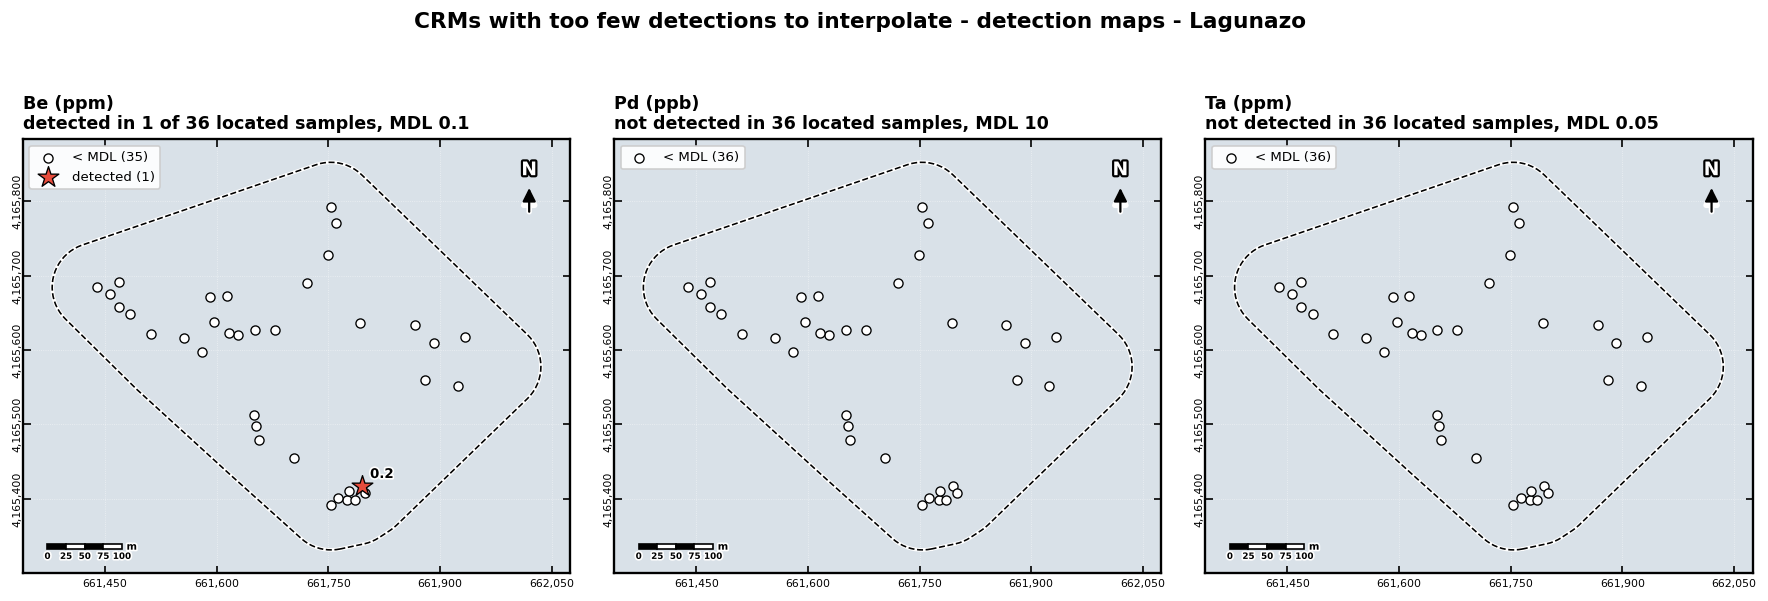

Detection maps (Be, Pd, Ta) saved -> ICP_CRM_detection_maps_UTM29N.png


In [ ]:
if DETECTION_ONLY:
    _asp = (ymax_u - ymin_u + 2 * pad_y) / (xmax_u - xmin_u + 2 * pad_x)
    fig, axs = plt.subplots(1, len(DETECTION_ONLY), figsize=(6.2 * len(DETECTION_ONLY), 6.2 * _asp + 1.0),
                            squeeze=False, gridspec_kw={"wspace": 0.08})
    for ax, el in zip(axs[0], DETECTION_ONLY):
        f_ = RAW_FLAG.loc[has_any, el].to_numpy()[LOCATED]
        v_ = RAW_VAL.loc[has_any, el].to_numpy(float)[LOCATED]
        x_, y_ = SAMP.loc[LOCATED, "X_utm"].to_numpy(float), SAMP.loc[LOCATED, "Y_utm"].to_numpy(float)
        ana = np.isin(f_, ["ok", "bdl", "odl"])
        det = np.isin(f_, ["ok", "odl"])
        add_satellite_basemap(ax)
        ax.scatter(x_[ana & ~det], y_[ana & ~det], s=30, facecolors="white", edgecolors="black", linewidths=0.8,
                   zorder=11, label=f"< MDL ({int((ana & ~det).sum())})")
        if det.any():
            ax.scatter(x_[det], y_[det], s=170, marker="*", c="#e74c3c", edgecolors="black", linewidths=0.8,
                       zorder=12, label=f"detected ({int(det.sum())})")
            for xx, yy, vv in zip(x_[det], y_[det], v_[det]):
                ax.annotate(fmt_num(vv), (xx, yy), xytext=(5, 5), textcoords="offset points", fontsize=8,
                            fontweight="bold", zorder=13, path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
        add_map_furniture(ax, fs=0.75)
        ax.tick_params(labelsize=6.5)
        mdl_ = META.loc[el, "mdl"]
        ax.set_title(f"{el} ({unit_of(el)})\n" + (f"detected in {int(det.sum())} of {int(ana.sum())} located samples"
                     if det.any() else f"not detected in {int(ana.sum())} located samples")
                     + f", MDL {fmt_num(mdl_)}", fontsize=10.5, fontweight="bold", loc="left")
        ax.legend(loc="upper left", fontsize=8, framealpha=0.92)
    fig.suptitle("CRMs with too few detections to interpolate - detection maps - Lagunazo", fontsize=13,
                 fontweight="bold")
    plt.savefig(DETECTION_MAP_PNG, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Detection maps ({', '.join(DETECTION_ONLY)}) saved -> {DETECTION_MAP_PNG}")
else:
    print("Every assayed CRM analyte has enough detections to be interpolated.")

## 17 · Export

In [ ]:
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

OUTPUT_XLS = "IDW_ICP_Lagunazo_CRM_Analysis.xlsx"

# Located samples with substituted CRM values and flags (also written as CSV for the kriging notebooks)
crm_analytes = [a for a in CRM_TABLE["Analyte"] if not a.endswith("_LF725")]
loc_tbl = SAMP.loc[LOCATED, ["Sample", "Field_ID", "No", "ID_fix", "Lon", "Lat", "X_utm", "Y_utm", "In_domain"]].copy()
for a in crm_analytes:
    f = RAW_FLAG.loc[has_any, a].to_numpy()[LOCATED]
    v = RAW_VAL.loc[has_any, a].to_numpy(float)[LOCATED]
    loc_tbl[f"{a}_{META.loc[a, 'unit']}"] = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v,
                                                      np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    loc_tbl[f"{a}_flag"] = f
loc_tbl.to_csv("Lagunazo_ICP_located_samples.csv", index=False)

grid_out = pd.DataFrame({"Easting_m": XG.ravel(), "Northing_m": YG.ravel(),
                         f"{VAR_NAME}_IDW_{UNIT}": Z_grid.ravel(), "Dist_NearestSample_m": D_grid.ravel(),
                         "Extended_nbhd_flag": FB_grid.ravel(), "Extrapolated_flag": EX_grid.ravel(),
                         "Abs_LOOCV_error": AE_grid.ravel()}
                        ).dropna(subset=[f"{VAR_NAME}_IDW_{UNIT}"])
if ATLAS:
    atlas_grid = pd.DataFrame({"Easting_m": XG.ravel()[inside_flat], "Northing_m": YG.ravel()[inside_flat]})
    for el, a in ATLAS.items():
        if a["surface"]:                               # every interpolated CRM; reliability in Atlas_Summary
            atlas_grid[f"{el}_{a['unit']}"] = a["Z"].ravel()[inside_flat]

reco = SAMP[["Sample", "Series", "Located", "No", "Field_ID_recorded", "Field_ID", "ID_fix", "Lon", "Lat",
             "X_utm", "Y_utm"]].copy()

sheets = [("CRM_Identification", CRM_TABLE), ("CRM_Elements", CRM_ELEMENTS), ("CRM_Not_Covered", CRM_NOT_COVERED),
          ("Digestion_Check", DIGESTION_CHECK), ("Analyte_Census", census.reset_index()),
          ("QC_Pulp_Duplicate", QC_DUP), ("QC_Standards", QC_STD), ("QC_Blanks", QC_BLK),
          ("ID_Fixes", ID_FIX_TABLE), ("Sample_Reconciliation", reco), ("Located_Samples", loc_tbl),
          (f"{VAR_NAME}_LOOCV", cv_df), ("Performance_Metrics", metrics_tbl.reset_index()),
          ("Tuning_Results", tuning_df), ("Audit_Checks", AUDIT_TBL),
          (f"{VAR_NAME}_Grid", grid_out)]
if ATLAS:
    sheets += [("Atlas_Summary", ATLAS_SUMMARY), ("Atlas_Grid", atlas_grid)]

with pd.ExcelWriter(OUTPUT_XLS, engine="openpyxl") as writer:
    for name, df_ in sheets:
        df_.to_excel(writer, sheet_name=name[:31], index=False)
    hdr_fill = PatternFill("solid", fgColor="1A5276")
    hdr_font = Font(bold=True, color="FFFFFF", size=10)
    thin = Side(border_style="thin", color="D5D8DC")
    for ws in writer.book.worksheets:
        for cell in ws[1]:
            cell.fill, cell.font = hdr_fill, hdr_font
            cell.alignment = Alignment(horizontal="center", wrap_text=True)
        if ws.max_row <= 2000:
            for row in ws.iter_rows(min_row=2):
                for cell in row:
                    cell.border = Border(thin, thin, thin, thin)
        for col_cells in ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)):
            mlen = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
            ws.column_dimensions[get_column_letter(col_cells[0].column)].width = min(max(mlen + 2, 8), 40)
        ws.freeze_panes = "A2"
print(f"Excel saved -> {OUTPUT_XLS}  ({len(sheets)} sheets)")
print("CSV saved   -> Lagunazo_ICP_located_samples.csv")

print()
print("=" * 66)
print("  IDW INTERPOLATION COMPLETE - Lagunazo ICP (EU CRMA 2024)")
print("=" * 66)
print(f"  Workbook        : {ICP_XLSX} (job {LAB_INFO.get('Job Number', '')})")
print(f"  Samples         : {len(SAMP)} with assays, {int(LOCATED.sum())} located, boundary = {BND_LABEL}")
print(f"  CRM identified  : " + ", ".join(CRM_ELEMENTS.loc[CRM_ELEMENTS['Status'] == 'identified', 'Element']))
print(f"  IDW surfaces    : {len(SURF_ELS)} CRMs - " + ", ".join(f"{e} ({ATLAS[e]['reliability']})" for e in SURF_ELS))
if POST_ELS:
    print(f"  Posted values   : " + ", ".join(POST_ELS) + f"  (LOOCV R2 < {MIN_R2_SURFACE:g})")
print(f"  Detection maps  : " + (", ".join(DETECTION_ONLY) or "none") + f"  (< {MIN_DETECTED_N} located detections)")
print(f"  Detail element  : {VAR_NAME} ({UNIT}), n = {N_SAMPLES} stations")
print(f"  Best parameters : p={BEST_P:.2f}  k={BEST_K}  radius={RAD_TXT}")
print(f"  LOOCV           : RMSE={fmt_num(cv_metrics['RMSE'])}  R2={cv_metrics['R2_pred']:.3f}  "
      f"bias={cv_metrics['ME_bias']:+.4g}  slope obs-on-pred={cv_metrics['Slope_obs_on_pred']:.2f}")
print(f"  Audit           : {int((AUDIT_TBL['Status'] == 'PASS').sum())} PASS / "
      f"{int((AUDIT_TBL['Status'] == 'WARN').sum())} WARN / 0 FAIL")
print(f"  Rasters (.asc)  : IDW_{VAR_NAME}_grade / _support_dist" + (" / _extended_nbhd_flag" if HAS_RADIUS else "")
      + " _UTM29N.asc")
print(f"  Figures         : locations, distribution, grade map, grade+support, dashboard, residuals"
      + (", CRM atlas + single maps" if ATLAS else ""))
print(f"  Workbook        : {OUTPUT_XLS}")
print("=" * 66)

Excel saved -> IDW_ICP_Lagunazo_CRM_Analysis.xlsx  (18 sheets)
CSV saved   -> Lagunazo_ICP_located_samples.csv

  IDW INTERPOLATION COMPLETE - Lagunazo ICP (EU CRMA 2024)
  Workbook        : ICP-DATA_2026.xlsx (job PLKRK2600014)
  Samples         : 50 with assays, 40 located, boundary = 60 m buffered hull (KMZ not found)
  CRM identified  : Al, Sb, As, Ba, Be, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pd, Pt, Sc, Si, Sr, Ti, W, V
  IDW surfaces    : 26 CRMs - Al (no skill), Sb (predictive), As (predictive), Ba (predictive), Bi (predictive), B (no skill), Co (weak), Cu (weak), Ga (predictive), Ge (predictive), Hf (predictive), Y (weak), La (no skill), Ce (no skill), Li (weak), Mg (no skill), Mn (weak), Ni (weak), Nb (no skill), P (predictive), Pt (predictive), Sc (no skill), Sr (no skill), Ti (no skill), W (no skill), V (no skill)
  Detection maps  : Be, Pd, Ta  (< 5 located detections)
  Detail element  : Bi (ppm), n = 36 stations
  Best parameters : p=1.50  k=20  ra